# Modèle de gravité — Analyse des données

Ce notebook réalise la partie **« Analyse des données » de la roadmap** pour notre
modèle de **gravité automobile** : description des données, description de la cible
et pertinence des variables. Les résultats, graphiques et commentaires sont calculés
à partir des fichiers locaux `Data/train.csv` et `Data/test.csv`.

La quantité que l'on cherchera ensuite à prédire est :

\[
\mathbb{E}[\text{montant\_sinistre}\mid\text{montant\_sinistre}>0, X].
\]

Le fichier fournit un montant par contrat. On vérifie que `nombre_sinistres` vaut
uniquement 0 ou 1 avant d'interpréter les montants positifs comme des coûts par
sinistre. **Les montants nuls ne font pas partie de la population de gravité.**

1. **Description des données** : types, valeurs manquantes, distributions,
   valeurs aberrantes, doublons et structure par client.
2. **Description de la cible** : coûts positifs, quantiles, valeurs répétées,
   asymétrie et concentration des gros sinistres.
3. **Pertinence des données** : cohérence métier, liens avec la gravité,
   modalités rares, redondances et compatibilité avec le test.

La suite du notebook réalise aussi le **découpage 80/20 par client**, le
**traitement des NaN** et la création d'une variable géographique limitée au
**département**, ainsi que les interactions **âge du véhicule × puissance**,
**puissance × ancienneté du permis principal** et **vitesse × âge du conducteur principal**. La section 6 compare des ensembles de variables en validation croisée, sans entraîner ni sauvegarder de modèle final.

## Repère dans la roadmap et méthode de lecture

![Roadmap de référence](../gravite_xgboost/assets/roadmap_reference.png)

Les trois sous-parties de la colonne **Analyse des données** sont couvertes ci-dessous.
La séparation par client sert de garde-fou méthodologique : les descriptions liées
aux coûts utilisent exclusivement les 80 % de développement, selon le découpage
déjà utilisé dans le projet (`random_state=2026`). Les cibles des 20 % réservés ne
sont pas décrites ni utilisées pour choisir des variables.

L'audit de schéma et de présence des cibles porte sur les fichiers complets. Le
test est consulté uniquement pour ses caractéristiques et son format. Les données
ayant été étudiées dans des travaux antérieurs, le jeu réservé ne constitue pas
une nouvelle validation externe.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import platform
import importlib.metadata

os.environ.setdefault('MPLCONFIGDIR', '/tmp/gravite_analyse_mpl')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pandas.api.types import is_numeric_dtype
from sklearn.model_selection import GroupShuffleSplit
from IPython.display import display, Markdown, Image

SEED = 2026
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / 'TD-Tarification-automobile-par-Machine-Learning']
REPO = next((p for p in candidates if (p / 'Data/train.csv').is_file()
             and (p / 'nouveau_notebook/notebook.ipynb').is_file()), None)
if REPO is None:
    raise FileNotFoundError('Exécuter depuis le dossier du notebook, le dépôt ou Project.')
HERE = REPO / 'nouveau_notebook'
sys.path.insert(0, str(HERE))
from preparation_gravite import (PreparationGravite, extraire_departement, interaction_age_puissance,
                                  MODEL_FEATURES, NUMERIC_FEATURES, DERIVED_NUMERIC_FEATURES, INTERACTION_FEATURE,
                                  creer_interactions, INTERACTION_SOURCES)
REPORTS = HERE / 'reports'
REPORTS.mkdir(exist_ok=True)
TARGET = 'montant_sinistre'
IDS = ['index', 'id_client', 'id_vehicule', 'id_contrat']
SEXES = ['sex_conducteur1', 'sex_conducteur2']
TARGETS = ['nombre_sinistres', TARGET]
PRIMARY, SECONDARY = '#215e80', '#bd753d'
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18})

def note(text):
    display(Markdown(text))

def table(frame, filename):
    frame.to_csv(REPORTS / f'{filename}.csv', index=False)
    display(frame)

def figure(fig, filename):
    fig.tight_layout()
    path = REPORTS / f'{filename}.png'
    fig.savefig(path, dpi=130, bbox_inches='tight')
    display(Image(filename=str(path)))
    plt.close(fig)

versions = {'python': platform.python_version()}
for package in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'nbformat', 'nbclient', 'ipykernel']:
    versions[package] = importlib.metadata.version(package)
display(pd.Series(versions, name='version exécutée').to_frame())

/home/cytech/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


,version exécutée
python,3.12.3
numpy,2.5.3
pandas,3.0.6
matplotlib,3.11.2
scikit-learn,1.9.1
nbformat,5.9.1
nbclient,0.8.0
ipykernel,6.29.3


In [2]:
train = pd.read_csv(REPO / 'Data/train.csv', dtype={'code_postal': 'string'})
test = pd.read_csv(REPO / 'Data/test.csv', dtype={'code_postal': 'string'})
source_shapes = {'train': train.shape, 'test': test.shape}
train['departement'] = extraire_departement(train['code_postal'])
test['departement'] = extraire_departement(test['code_postal'])
for frame in [train, test]:
    frame[list(DERIVED_NUMERIC_FEATURES)] = creer_interactions(frame)
assert set(IDS + TARGETS).issubset(train.columns)
assert train['index'].is_unique and test['index'].is_unique
assert set(train['index']).isdisjoint(set(test['index']))
assert train['id_client'].notna().all(), 'Le découpage exige un identifiant client renseigné.'
assert train[TARGETS].notna().all().all(), 'Cible manquante à résoudre avant analyse.'
assert np.isfinite(train[TARGETS].to_numpy()).all()
assert train[TARGET].ge(0).all(), 'Montants négatifs à documenter avant analyse.'
assert set(train['nombre_sinistres'].unique()).issubset({0, 1}), (
    'Plusieurs sinistres par contrat : préciser la définition du coût par sinistre.'
)
assert train['nombre_sinistres'].gt(0).equals(train[TARGET].gt(0)), (
    'Incohérence entre présence de sinistre et montant positif.'
)
assert not set(TARGETS).intersection(test.columns), 'Le test attendu ne contient pas de cible.'

dev_idx, reserved_idx = next(GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED
).split(train, groups=train['id_client']))
dev_portfolio = train.iloc[dev_idx].copy()
reserved_clients = set(train.iloc[reserved_idx]['id_client'])
assert set(dev_portfolio['id_client']).isdisjoint(reserved_clients)
gravite = dev_portfolio.loc[dev_portfolio[TARGET].gt(0)].copy()
y = gravite[TARGET]
FEATURES = [c for c in test.columns if c not in IDS + TARGETS + SEXES + ['code_postal']]
assert set(FEATURES) == set(MODEL_FEATURES)
assert set(FEATURES).issubset(train.columns)
numeric = [c for c in FEATURES if is_numeric_dtype(train[c])]
categorical = [c for c in FEATURES if c not in numeric]

table(pd.DataFrame([
    {'jeu': 'train.csv complet', 'lignes': len(train), 'colonnes': source_shapes['train'][1],
     'usage': 'structure, contrôles de cohérence et découpage'},
    {'jeu': 'test.csv', 'lignes': len(test), 'colonnes': source_shapes['test'][1],
     'usage': 'caractéristiques disponibles, aucune cible'},
    {'jeu': 'développement : portefeuille', 'lignes': len(dev_portfolio),
     'colonnes': train.shape[1], 'usage': 'qualité et structure des variables'},
    {'jeu': 'développement : gravité positive', 'lignes': len(gravite),
     'colonnes': train.shape[1], 'usage': 'analyse des coûts conditionnels'},
    {'jeu': 'réserve par client', 'lignes': len(reserved_idx),
     'colonnes': train.shape[1], 'usage': 'aucune statistique de coût calculée ici'},
]), '01_perimetre')
note(f'**Population utile à la gravité : {len(gravite):,} contrats sinistrés** '
     f'parmi les {len(dev_portfolio):,} contrats de développement '
     f'({len(gravite) / len(dev_portfolio):.2%}). '
     f'On dispose de {len(numeric)} variables quantitatives et '
     f'{len(categorical)} variables qualitatives candidates, avant tout traitement.')
note('Les dimensions des fichiers sont celles des sources ; les vues de développement '
     'comptent aussi le département et les interactions, créés au chargement sans utiliser les coûts.')

,jeu,lignes,colonnes,usage
0,train.csv complet,50000,33,"structure, contrôles de cohérence et découpage"
1,test.csv,50000,28,"caractéristiques disponibles, aucune cible"
2,développement : portefeuille,39964,37,qualité et structure des variables
3,développement : gravité positive,2356,37,analyse des coûts conditionnels
4,réserve par client,10036,37,aucune statistique de coût calculée ici


**Population utile à la gravité : 2,356 contrats sinistrés** parmi les 39,964 contrats de développement (5.90%). On dispose de 18 variables quantitatives et 10 variables qualitatives candidates, avant tout traitement.

Les dimensions des fichiers sont celles des sources ; les vues de développement comptent aussi le département et les interactions, créés au chargement sans utiliser les coûts.

## 1. Description des données

### 1.1 Dictionnaire, types et disponibilité

Les types informatiques ne suffisent pas à interpréter une variable. `code_postal`
reste du texte, et les identifiants servent au suivi et à la séparation des clients.
Les deux variables de sexe sont auditées mais exclues des candidats selon la
convention déjà retenue dans le projet. Cette convention ne détermine pas à elle
seule la pertinence des autres variables.

Les noms des variables donnent des indications métier ; les unités non documentées
ne sont pas inventées. En particulier, `duree_contrat` ne permet pas d'annualiser le
coût sans définition de la période d'exposition.

**Que signifient début et fin de vente ?** Les colonnes sont
`debut_vente_vehicule` et `fin_vente_vehicule` : leurs noms renvoient à la
commercialisation du véhicule. L'interprétation provisoire est l'ancienneté
depuis le début et la fin de commercialisation du modèle automobile. Leurs
valeurs entières ne sont pas des dates de contrat ; le codage et l'unité exacts
ne sont pas précisés dans le dictionnaire disponible. On ne les convertit donc
pas en dates calendaires et on ne les utilise pas pour calculer une exposition.


In [3]:
descriptions = {
    'index': ('technique', 'Ordre technique ; disponible dans le test.'),
    'id_client': ('identifiant', 'Groupe client pour séparer les contrats ; absent du test.'),
    'id_vehicule': ('identifiant', 'Identifiant local du véhicule ; absent du test.'),
    'id_contrat': ('identifiant', 'Identifiant du contrat ; absent du test.'),
    'bonus': ('quantitative', 'Coefficient bonus-malus déclaré.'),
    'type_contrat': ('qualitative', 'Niveau de couverture déclaré.'),
    'duree_contrat': ('quantitative', 'Durée / ancienneté déclarée ; unité et exposition à confirmer.'),
    'anciennete_info': ('quantitative', 'Ancienneté de l’information ; unité à confirmer.'),
    'freq_paiement': ('qualitative', 'Périodicité déclarée du paiement.'),
    'paiement': ('qualitative', 'Indicateur de paiement ; définition précise à confirmer.'),
    'utilisation': ('qualitative', 'Usage déclaré du véhicule.'),
    'code_postal': ('qualitative', 'Source de departement ; code fin exclu des entrées du modèle.'),
    'departement': ('qualitative créée', 'Département extrait du code source ; catégorie nominale.'),
    'conducteur2': ('qualitative', 'Présence déclarée d’un second conducteur.'),
    'age_conducteur1': ('quantitative', 'Âge du conducteur principal.'),
    'age_conducteur2': ('quantitative', 'Âge secondaire ; zéro structurel si absent.'),
    'sex_conducteur1': ('qualitative', 'Sexe principal ; exclu des variables candidates.'),
    'sex_conducteur2': ('qualitative', 'Sexe secondaire ; absence structurelle à contrôler.'),
    'anciennete_permis1': ('quantitative', 'Ancienneté du permis principal ; codes suspects possibles.'),
    'anciennete_permis2': ('quantitative', 'Ancienneté du permis secondaire ; zéro si absent.'),
    'anciennete_vehicule': ('quantitative', 'Ancienneté du véhicule déclarée.'),
    'age_puissance_vehicule': ('quantitative créée', 'Ancienneté du véhicule × puissance DIN ; interaction multiplicative.'),
    'cylindre_vehicule': ('quantitative', 'Cylindrée déclarée ; valeurs non positives à examiner.'),
    'din_vehicule': ('quantitative', 'Puissance DIN déclarée.'),
    'essence_vehicule': ('qualitative', 'Motorisation déclarée.'),
    'marque_vehicule': ('qualitative', 'Marque déclarée.'),
    'modele_vehicule': ('qualitative', 'Modèle automobile ; modalités nombreuses et rares.'),
    'debut_vente_vehicule': ('quantitative', 'Ancienneté de début de commercialisation ; unité à confirmer.'),
    'fin_vente_vehicule': ('quantitative', 'Ancienneté de fin de commercialisation ; unité à confirmer.'),
    'vitesse_vehicule': ('quantitative', 'Vitesse maximale déclarée ; unité à confirmer.'),
    'type_vehicule': ('qualitative', 'Catégorie tourisme / commercial.'),
    'prix_vehicule': ('quantitative', 'Prix déclaré ; date de valeur et unité à confirmer.'),
    'poids_vehicule': ('quantitative', 'Poids déclaré ; valeurs non positives à examiner.'),
    'nombre_sinistres': ('cible auxiliaire', 'Contrôle du filtre positif ; interdit comme entrée du modèle.'),
    'montant_sinistre': ('cible', 'Montant observé ; cible de gravité sur les coûts positifs.'),
}
for name, (left, right) in INTERACTION_SOURCES.items():
    descriptions.setdefault(name, ('quantitative créée', f'Interaction multiplicative : {left} × {right}.'))
assert set(descriptions) == set(train.columns), 'Dictionnaire à mettre à jour.'
audit_rows = []
for col in train.columns:
    s = dev_portfolio[col]
    role = ('cible de gravité' if col == TARGET else 'filtre, jamais prédicteur'
            if col == 'nombre_sinistres' else 'identifiant exclu' if col in IDS
            else 'exclue par convention du projet' if col in SEXES
            else 'source département, exclu du modèle' if col == 'code_postal' else 'candidate')
    audit_rows.append({
        'variable': col, 'nature': descriptions[col][0], 'type_python': str(s.dtype),
        'rôle': role, 'dans_test': col in test.columns,
        'manquants_dev': int(s.isna().sum()), 'modalités_dev': s.nunique(dropna=True),
        'modalités_sinistrés': gravite[col].nunique(dropna=True),
        'description': descriptions[col][1],
    })
audit = pd.DataFrame(audit_rows)
table(audit, '02_dictionnaire_variables')
note('**Différence de schéma :** le test ne contient pas ' +
     ', '.join(f'`{c}`' for c in train.columns if c not in test.columns) + '. '
     'Un identifiant disponible seulement dans le train ne peut pas être un prédicteur réutilisable.')

,variable,nature,type_python,rôle,dans_test,manquants_dev,modalités_dev,modalités_sinistrés,description
0,index,technique,int64,identifiant exclu,True,0,39964,2356,Ordre technique ; disponible dans le test.
1,id_client,identifiant,str,identifiant exclu,False,0,36628,2338,Groupe client pour séparer les contrats ; abse...
2,id_vehicule,identifiant,str,identifiant exclu,False,0,5,4,Identifiant local du véhicule ; absent du test.
3,id_contrat,identifiant,str,identifiant exclu,False,0,39964,2356,Identifiant du contrat ; absent du test.
4,bonus,quantitative,float64,candidate,True,0,72,41,Coefficient bonus-malus déclaré.
5,type_contrat,qualitative,str,candidate,True,0,4,4,Niveau de couverture déclaré.
6,duree_contrat,quantitative,int64,candidate,True,0,41,33,Durée / ancienneté déclarée ; unité et exposit...
7,anciennete_info,quantitative,int64,candidate,True,0,25,15,Ancienneté de l’information ; unité à confirmer.
8,freq_paiement,qualitative,str,candidate,True,0,4,4,Périodicité déclarée du paiement.
9,paiement,qualitative,str,candidate,True,0,2,2,Indicateur de paiement ; définition précise à ...


**Différence de schéma :** le test ne contient pas `id_client`, `id_vehicule`, `id_contrat`, `nombre_sinistres`, `montant_sinistre`. Un identifiant disponible seulement dans le train ne peut pas être un prédicteur réutilisable.

### 1.2 Valeurs manquantes et absences structurelles

On distingue un champ réellement inconnu d'un champ sans objet. L'absence du sexe
secondaire et les zéros d'âge / permis peuvent simplement correspondre à l'absence
d'un second conducteur. Les pourcentages ci-dessous sont calculés séparément sur
le portefeuille de développement, les sinistrés de développement et le test.

,variable,n_dev,pct_dev,n_gravité,pct_gravité,n_test,pct_test
16,sex_conducteur2,26670,66.735,1493,63.370,"33,408.000",66.816
19,anciennete_vehicule,1,0.003,0,0.000,0.000,0.000
34,age_puissance_vehicule,1,0.003,0,0.000,0.000,0.000
35,puissance_anciennete_permis1,11,0.028,0,0.000,14.000,0.028


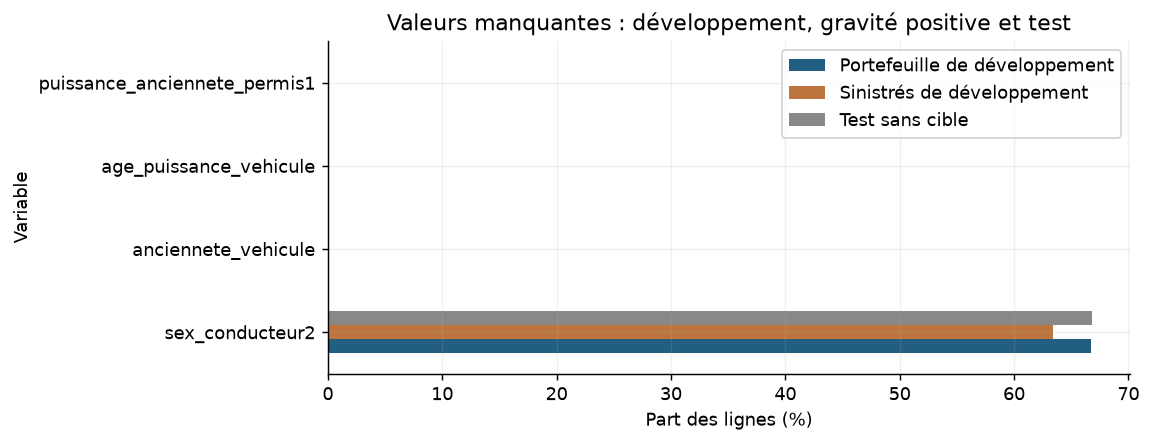

,jeu,sans_second_conducteur,sexe_absent_sans_second,âge_zéro_sans_second,permis_zéro_sans_second,sexe_manquant_si_présent
0,développement,26670,26670,26670,26670,0
1,sinistrés de développement,1493,1493,1493,1493,0
2,test,33408,33408,33408,33408,0


**Lecture :** 1 ancienneté(s) véhicule manquante(s) dans le développement. Le tableau conditionnel permet de reconnaître les absences structurelles du second conducteur. Pour la suite, conserver son indicateur de présence et traiter âge / permis comme sans objet lorsqu’il est absent ; ne pas interpréter ces zéros comme un conducteur âgé de zéro an.

In [4]:
missing_rows = []
for col in train.columns:
    row = {'variable': col, 'n_dev': int(dev_portfolio[col].isna().sum()),
           'pct_dev': 100 * dev_portfolio[col].isna().mean(),
           'n_gravité': int(gravite[col].isna().sum()),
           'pct_gravité': 100 * gravite[col].isna().mean(),
           'n_test': int(test[col].isna().sum()) if col in test else np.nan,
           'pct_test': 100 * test[col].isna().mean() if col in test else np.nan}
    missing_rows.append(row)
missing = pd.DataFrame(missing_rows)
missing.to_csv(REPORTS / '03_valeurs_manquantes.csv', index=False)
visible_missing = missing.loc[missing[['pct_dev', 'pct_gravité', 'pct_test']].gt(0).any(axis=1)]
display(visible_missing)
if len(visible_missing):
    fig, ax = plt.subplots(figsize=(9, 3.5))
    visible_missing.set_index('variable')[['pct_dev', 'pct_gravité', 'pct_test']].plot.barh(
        ax=ax, color=[PRIMARY, SECONDARY, '#888888'])
    ax.set(title='Valeurs manquantes : développement, gravité positive et test',
           xlabel='Part des lignes (%)', ylabel='Variable')
    ax.legend(['Portefeuille de développement', 'Sinistrés de développement', 'Test sans cible'])
    figure(fig, '01_valeurs_manquantes')

absence_rows = []
for name, frame in [('développement', dev_portfolio), ('sinistrés de développement', gravite), ('test', test)]:
    absent = frame['conducteur2'].eq('No')
    present = frame['conducteur2'].eq('Yes')
    absence_rows.append({
        'jeu': name, 'sans_second_conducteur': int(absent.sum()),
        'sexe_absent_sans_second': int((frame['sex_conducteur2'].isna() & absent).sum()),
        'âge_zéro_sans_second': int((frame['age_conducteur2'].eq(0) & absent).sum()),
        'permis_zéro_sans_second': int((frame['anciennete_permis2'].eq(0) & absent).sum()),
        'sexe_manquant_si_présent': int((frame['sex_conducteur2'].isna() & present).sum()),
    })
table(pd.DataFrame(absence_rows), '04_absence_second_conducteur')
vehicle_missing = int(dev_portfolio['anciennete_vehicule'].isna().sum())
note(f'**Lecture :** {vehicle_missing} ancienneté(s) véhicule manquante(s) dans le développement. '
     'Le tableau conditionnel permet de reconnaître les absences structurelles du second conducteur. '
     'Pour la suite, conserver son indicateur de présence et traiter âge / permis comme sans objet '
     'lorsqu’il est absent ; ne pas interpréter ces zéros comme un conducteur âgé de zéro an.')

### 1.3 Répartition des variables quantitatives et qualitatives

Les statistiques sont données sur le portefeuille et sur les sinistrés. Pour la
visualisation, chaque variable conserve ses unités déclarées. Les axes des graphiques
ne sont pas tronqués : une pointe ou une valeur éloignée reste visible. Les modalités
rares sont décrites par leurs effectifs ; un faible effectif chez les sinistrés peut
rendre leur coût moyen très instable.

,variable,count,mean,std,min,1%,25%,50%,75%,99%,max,population
0,bonus,"39,964.000",0.538,0.099,0.500,0.500,0.500,0.500,0.500,0.950,2.160,portefeuille développement
1,duree_contrat,"39,964.000",11.094,8.563,1.000,1.000,4.000,9.000,17.000,31.000,41.000,portefeuille développement
2,anciennete_info,"39,964.000",2.733,2.354,1.000,1.000,1.000,2.000,3.000,12.000,25.000,portefeuille développement
3,age_conducteur1,"39,964.000",54.647,14.834,19.000,24.000,43.000,54.000,65.000,86.000,101.000,portefeuille développement
4,age_conducteur2,"39,964.000",15.585,23.986,0.000,0.000,0.000,0.000,34.000,78.000,99.000,portefeuille développement
5,anciennete_permis1,"39,964.000",32.428,13.424,1.000,4.000,22.000,32.000,42.000,61.000,111.000,portefeuille développement
6,anciennete_permis2,"39,964.000",9.133,17.025,0.000,0.000,0.000,0.000,14.000,59.000,111.000,portefeuille développement
7,anciennete_vehicule,"39,963.000",9.543,7.019,1.000,1.000,4.000,8.000,13.000,33.000,64.000,portefeuille développement
8,cylindre_vehicule,"39,964.000","1,648.200",464.669,0.000,602.000,"1,360.000","1,587.000","1,910.000","2,993.000","6,997.000",portefeuille développement
9,din_vehicule,"39,964.000",91.542,34.510,15.000,30.000,68.000,87.000,109.000,210.000,486.000,portefeuille développement


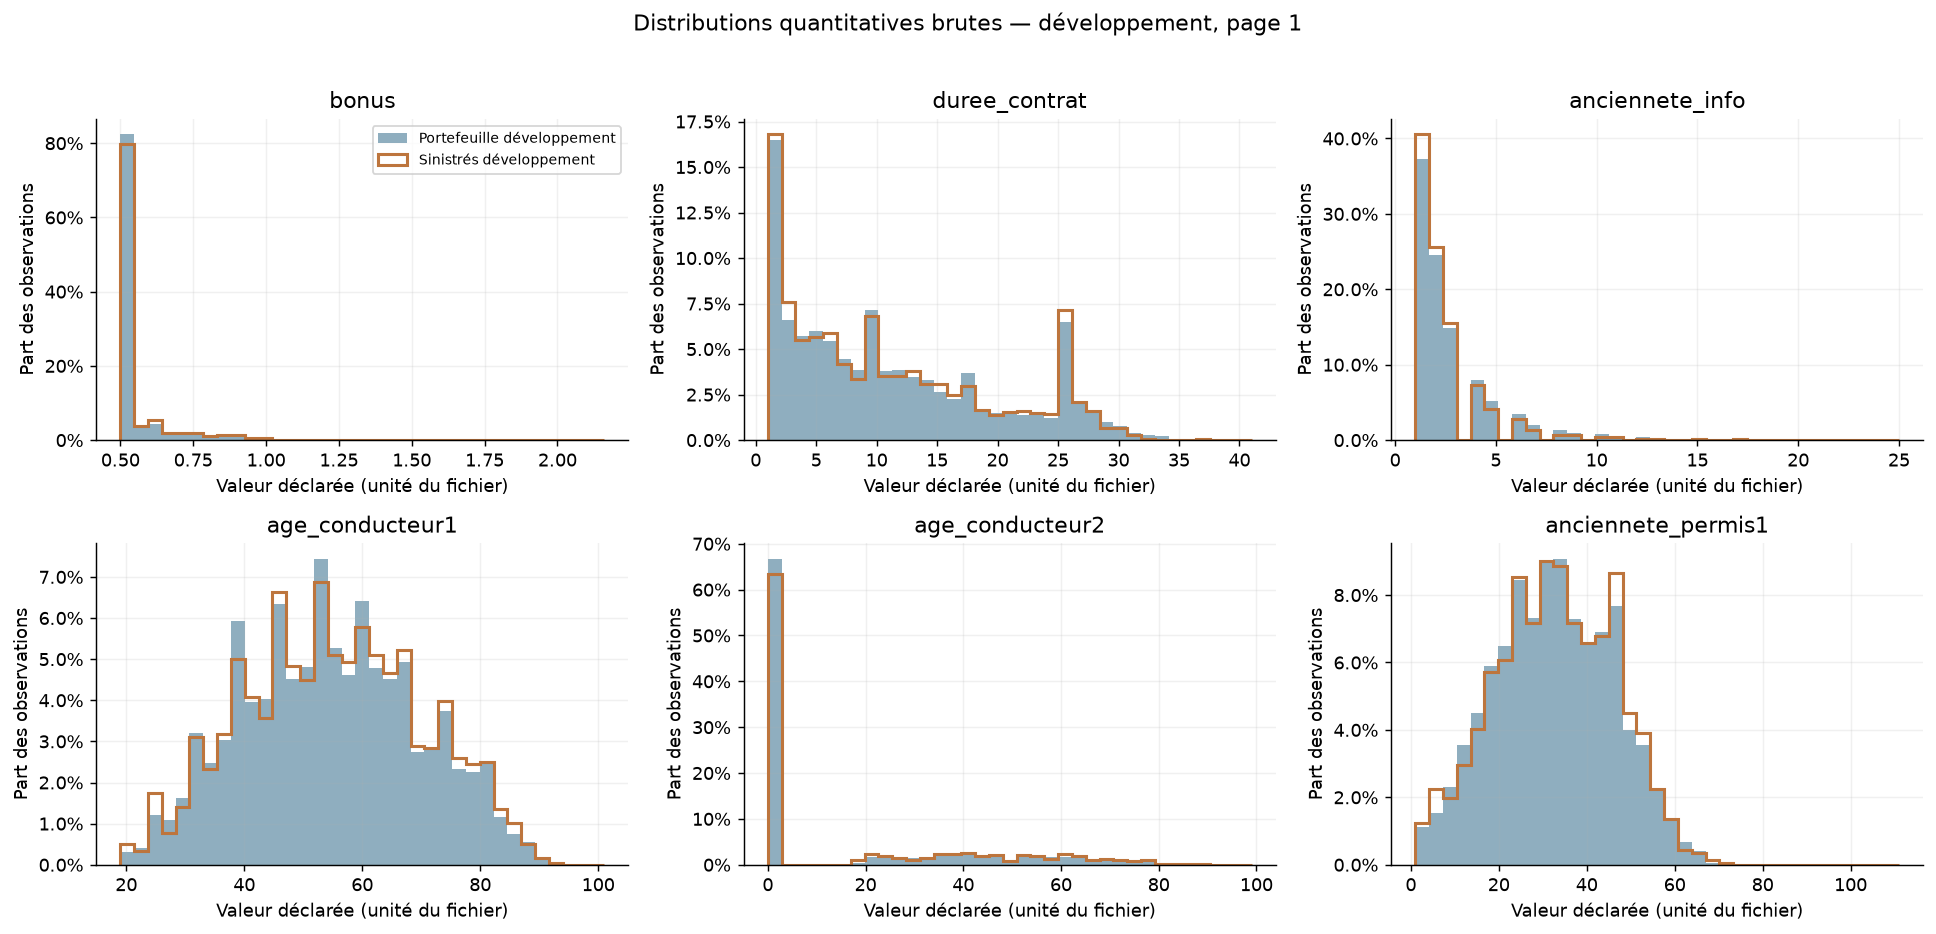

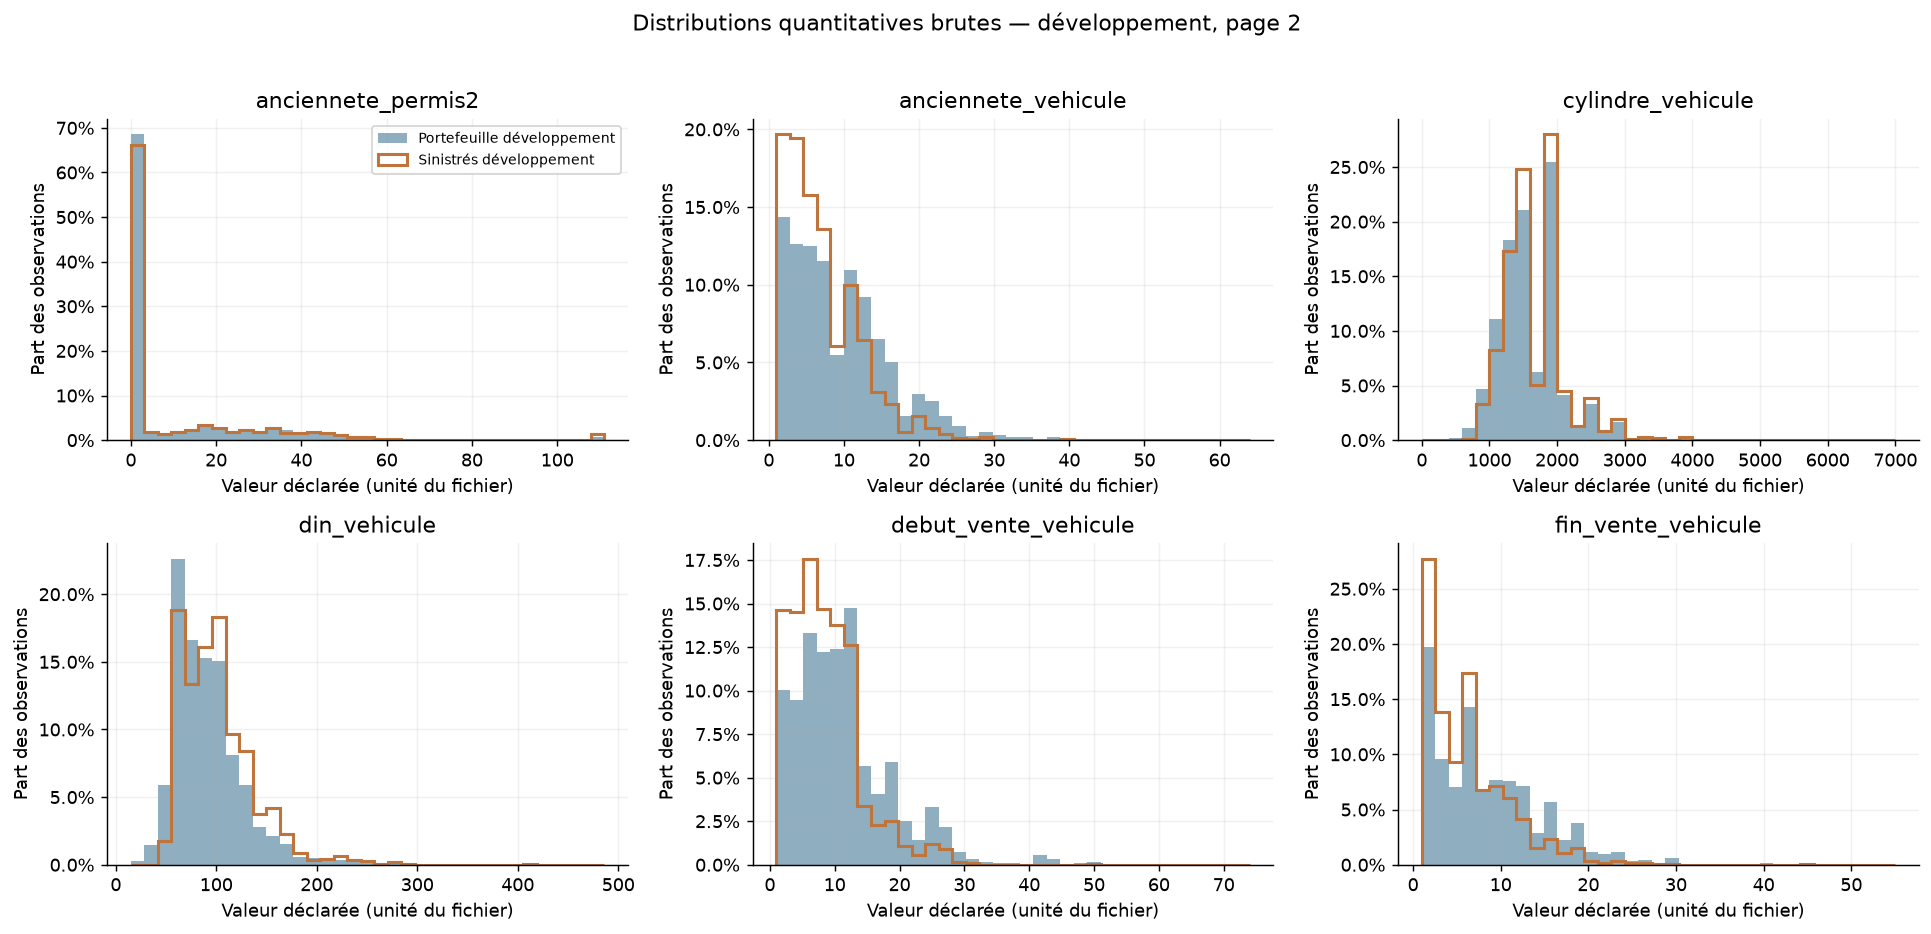

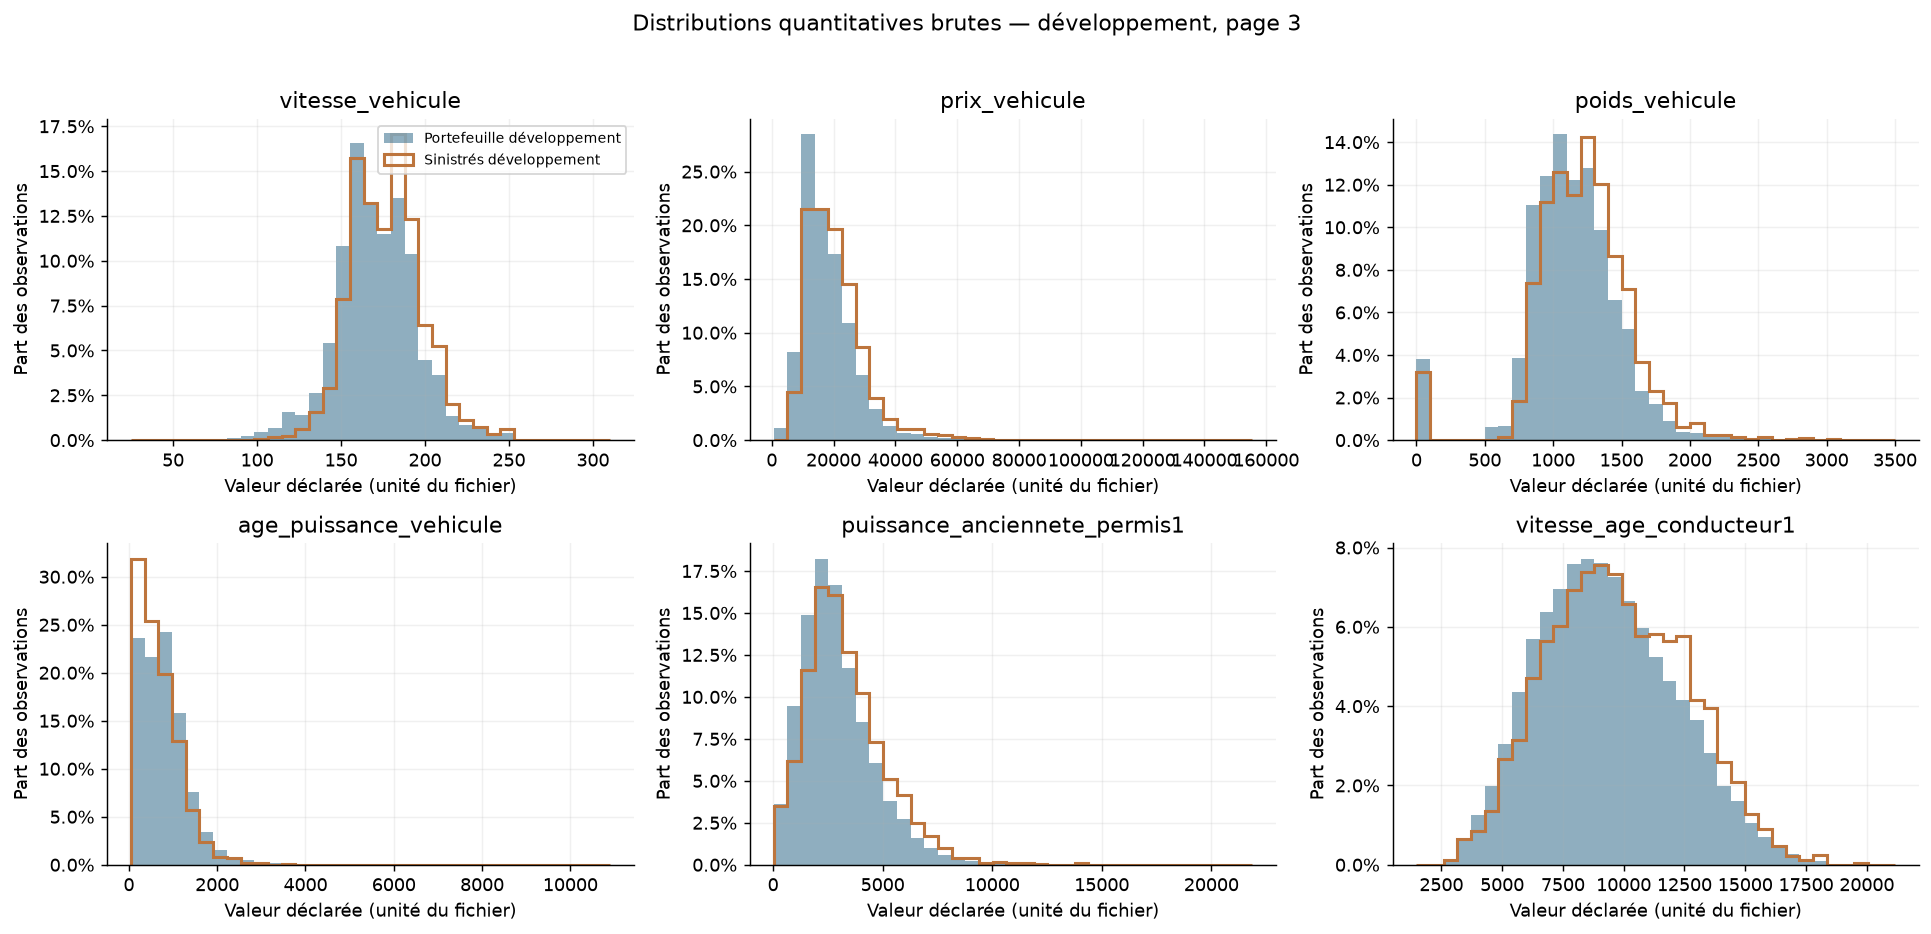

In [5]:
num_summary = pd.concat([
    frame[numeric].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
        .rename_axis('variable').reset_index().assign(population=label)
    for label, frame in [('portefeuille développement', dev_portfolio),
                         ('sinistrés développement', gravite)]
], ignore_index=True)
table(num_summary, '05_description_quantitative')

for page, start in enumerate(range(0, len(numeric), 6), 1):
    columns = numeric[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    for ax, col in zip(axes.flat, columns):
        bins = np.histogram_bin_edges(dev_portfolio[col].dropna(), bins=35)
        ax.hist(dev_portfolio[col].dropna(), bins=bins, weights=np.full(
            dev_portfolio[col].notna().sum(), 1 / dev_portfolio[col].notna().sum()),
            color=PRIMARY, alpha=0.5, label='Portefeuille développement')
        ax.hist(gravite[col].dropna(), bins=bins, weights=np.full(
            gravite[col].notna().sum(), 1 / gravite[col].notna().sum()),
            histtype='step', color=SECONDARY, linewidth=1.7, label='Sinistrés développement')
        ax.set(title=col, xlabel='Valeur déclarée (unité du fichier)', ylabel='Part des observations')
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    for ax in list(axes.flat)[len(columns):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle(f'Distributions quantitatives brutes — développement, page {page}', y=1.02)
    figure(fig, f'02_quantitatives_{page}')

,variable,modalités_portefeuille,modalités_gravité,modalité_dominante,part_dominante_pct,modalités_avec_moins_de_10_sinistres,part_sinistres_dans_modalités_rares_pct,modalités_portefeuille_sans_sinistre
0,type_contrat,4,4,Maxi,64.751,0,0.000,0
1,freq_paiement,4,4,Yearly,38.054,0,0.000,0
2,paiement,2,2,No,95.786,0,0.000,0
3,utilisation,4,4,WorkPrivate,65.934,1,0.127,0
4,conducteur2,2,2,No,66.735,0,0.000,0
5,essence_vehicule,3,3,Diesel,54.834,1,0.255,0
6,marque_vehicule,84,45,RENAULT,26.656,24,3.523,39
7,modele_vehicule,841,322,CLIO,7.277,268,28.820,519
8,type_vehicule,2,2,Tourism,90.039,0,0.000,0
9,departement,96,95,59,4.504,18,4.542,1


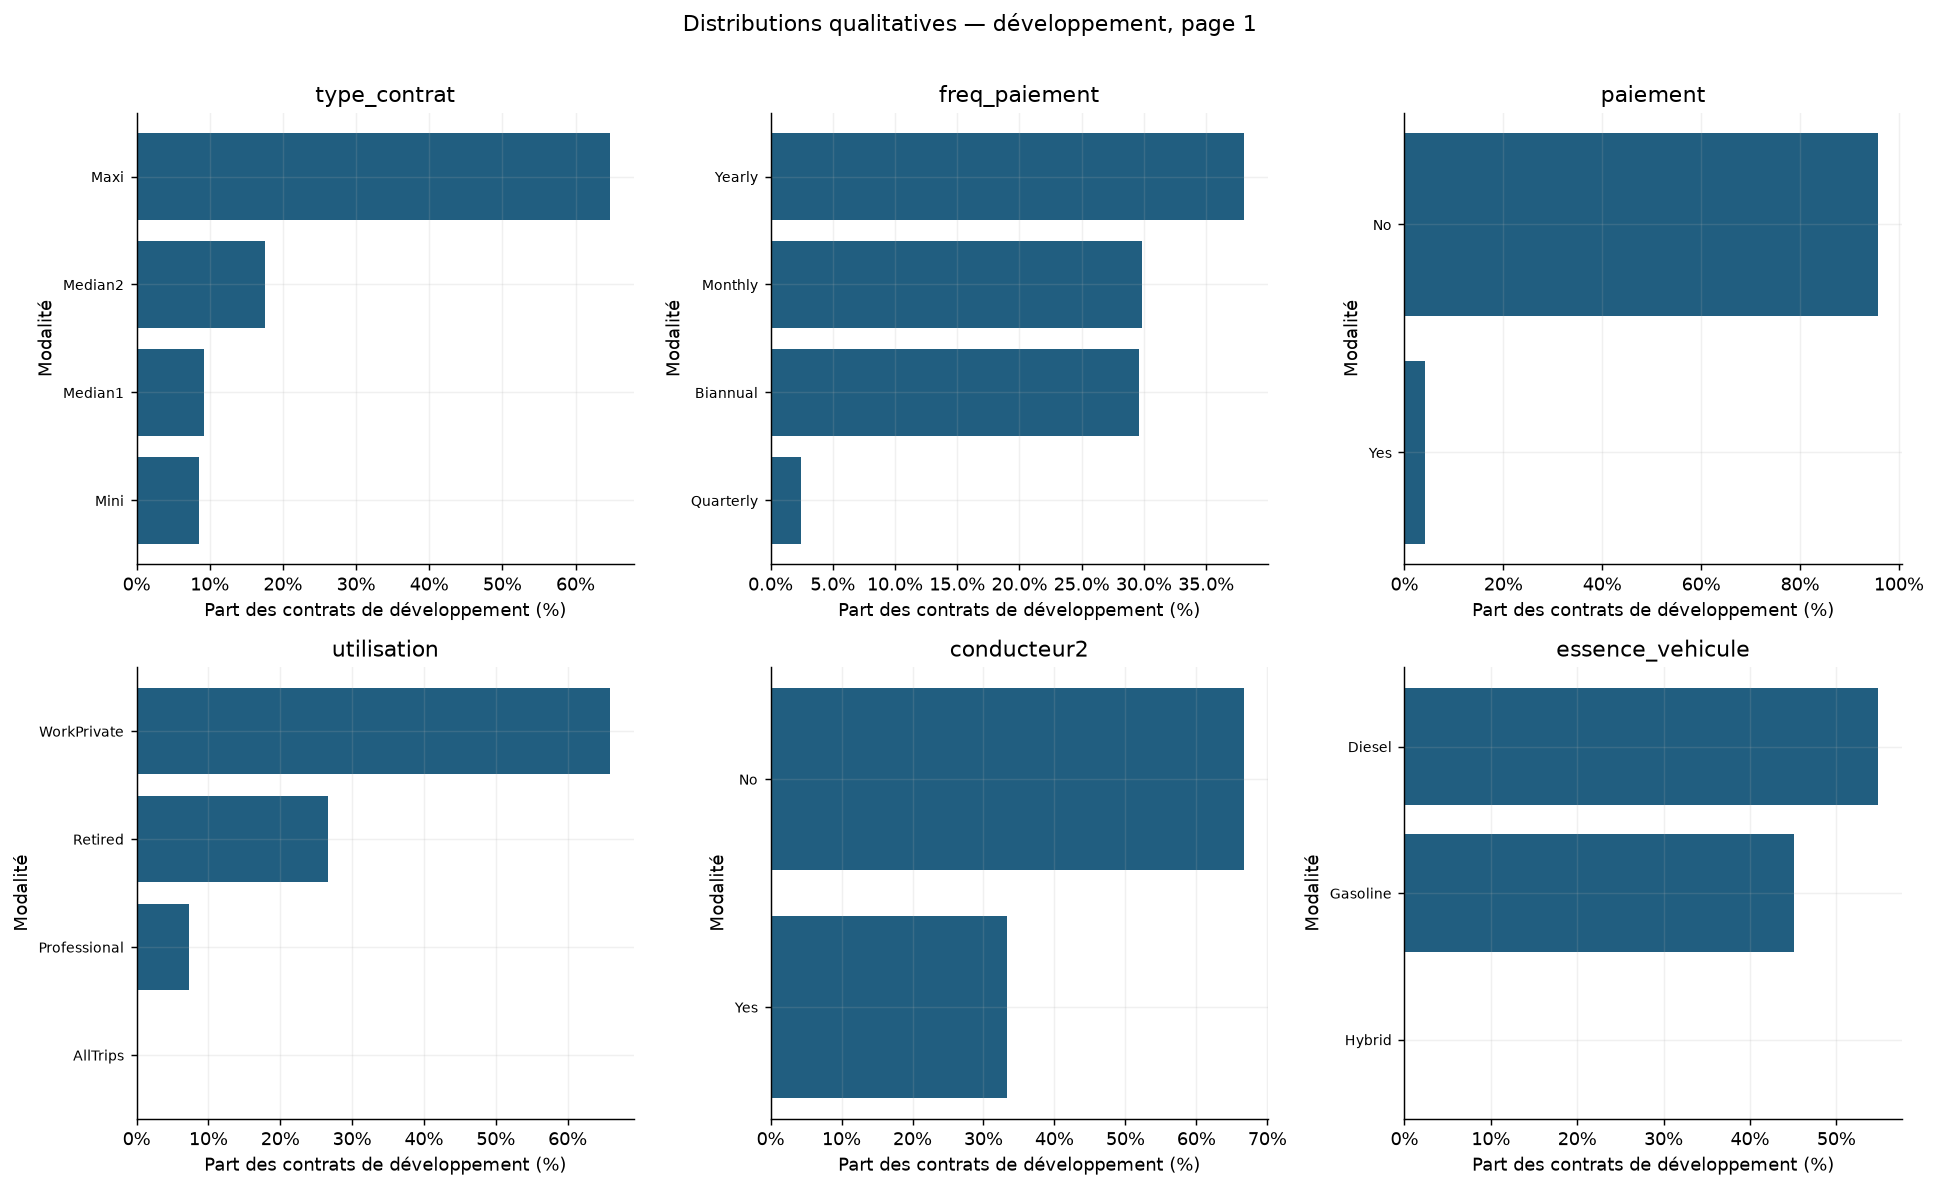

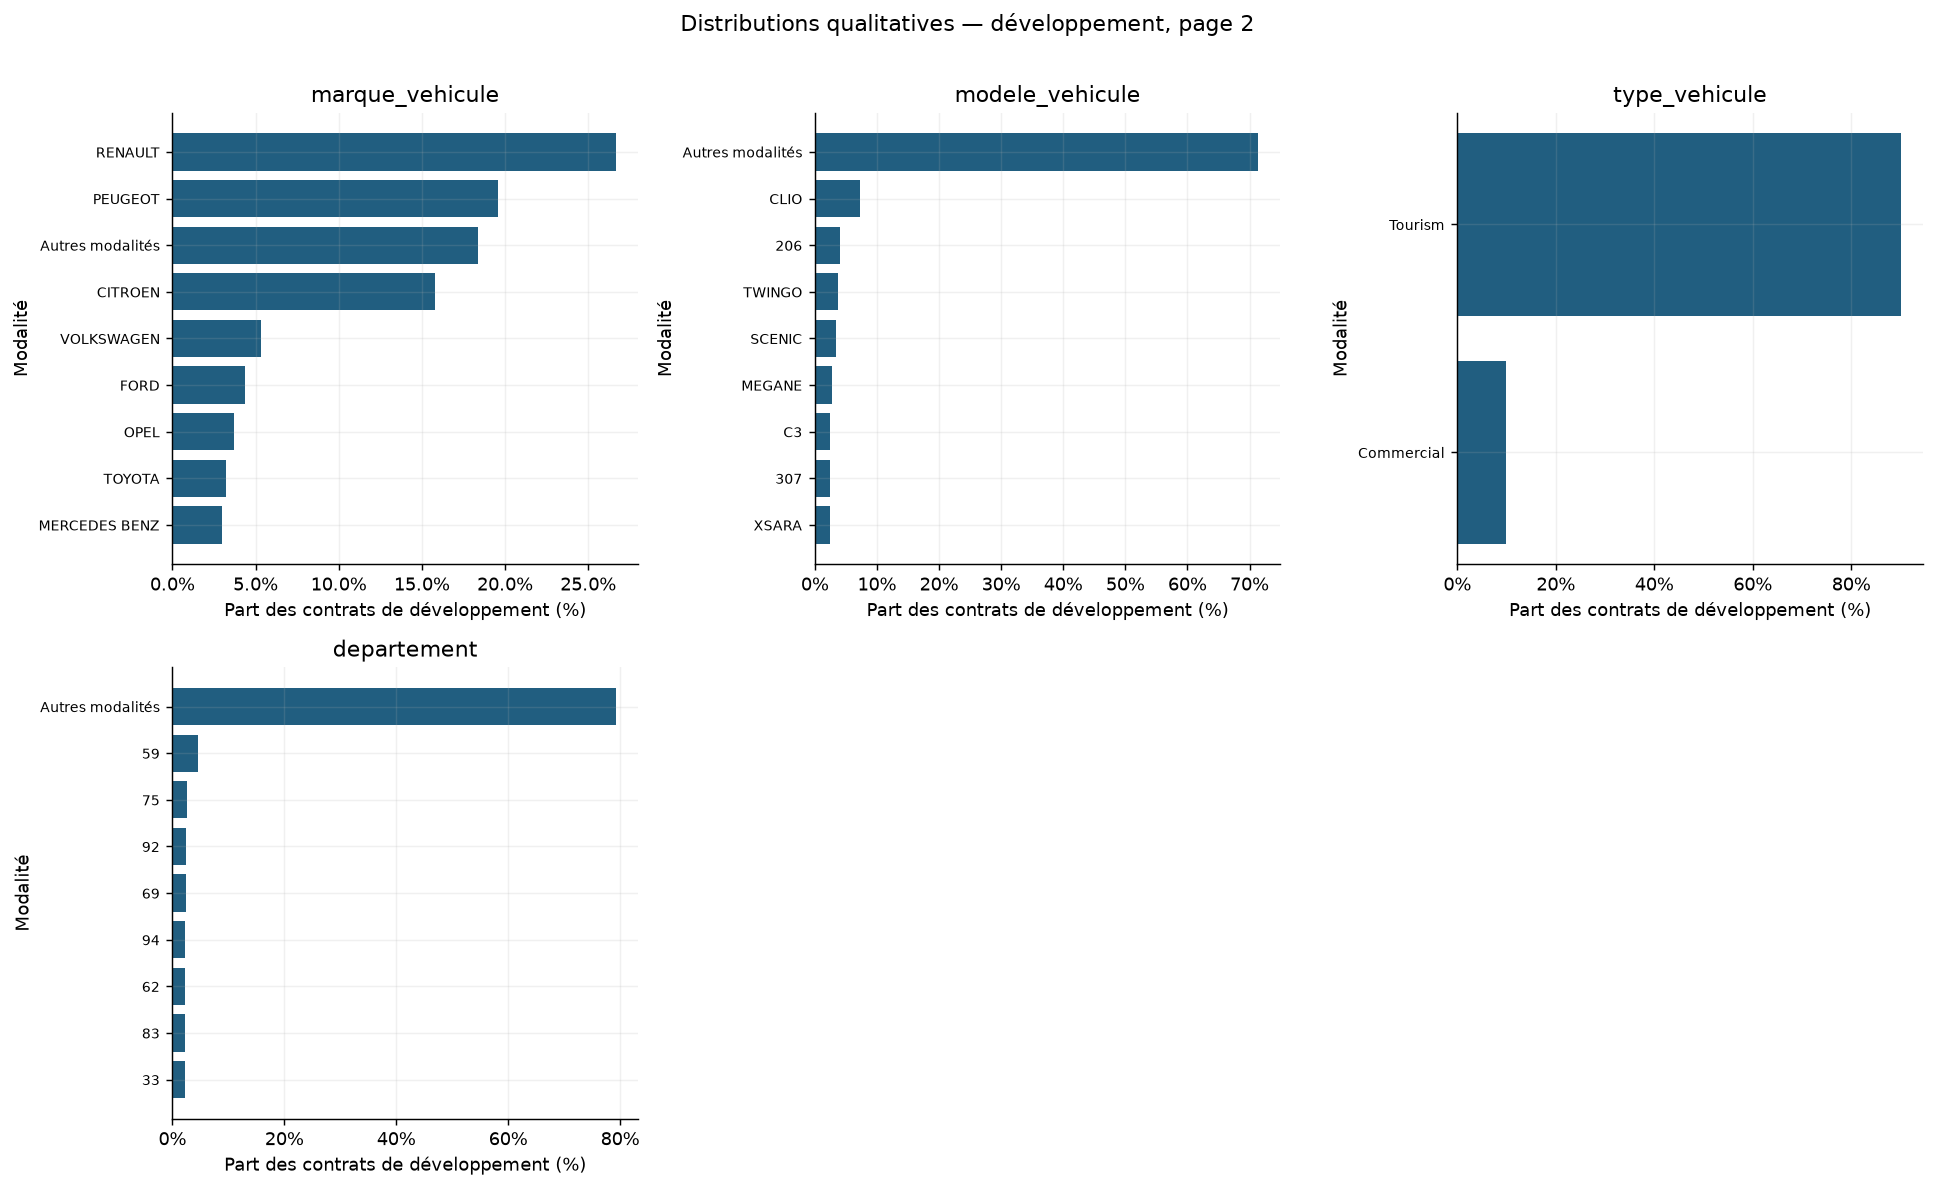

**Lecture :** les modèles automobiles et codes géographiques peuvent être très fragmentés. Les regroupements éventuels devront être appris sur les seuls sous-trains de modélisation. Le CSV des modalités conserve les effectifs complets, même lorsque le graphique regroupe les autres valeurs.

In [6]:
cat_rows, cat_counts = [], []
for col in categorical:
    total = dev_portfolio[col].fillna('⟨manquant⟩').astype(str).value_counts()
    pos = gravite[col].fillna('⟨manquant⟩').astype(str).value_counts()
    cat_rows.append({
        'variable': col, 'modalités_portefeuille': len(total), 'modalités_gravité': len(pos),
        'modalité_dominante': total.index[0], 'part_dominante_pct': 100 * total.iloc[0] / len(dev_portfolio),
        'modalités_avec_moins_de_10_sinistres': int(pos.lt(10).sum()),
        'part_sinistres_dans_modalités_rares_pct': 100 * pos[pos.lt(10)].sum() / len(gravite),
        'modalités_portefeuille_sans_sinistre': int((~total.index.isin(pos.index)).sum()),
    })
    cat_counts.append(pd.DataFrame({'variable': col, 'modalité': total.index,
        'contrats_dev': total.to_numpy(), 'sinistrés_dev': pos.reindex(total.index, fill_value=0).to_numpy()}))
cat_summary = pd.DataFrame(cat_rows)
table(cat_summary, '06_description_qualitative')
pd.concat(cat_counts, ignore_index=True).to_csv(REPORTS / '07_effectifs_modalites.csv', index=False)
for page, start in enumerate(range(0, len(categorical), 6), 1):
    columns = categorical[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    for ax, col in zip(axes.flat, columns):
        counts = dev_portfolio[col].fillna('⟨manquant⟩').astype(str).value_counts()
        keep = counts.head(8)
        if len(counts) > 8:
            keep = pd.concat([keep, pd.Series({'Autres modalités': counts.iloc[8:].sum()})])
        keep = (keep / len(dev_portfolio)).sort_values()
        ax.barh(keep.index, keep, color=PRIMARY)
        ax.set(title=col, xlabel='Part des contrats de développement (%)', ylabel='Modalité')
        ax.tick_params(axis='y', labelsize=8)
        ax.xaxis.set_major_formatter(PercentFormatter(1))
    for ax in list(axes.flat)[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(f'Distributions qualitatives — développement, page {page}', y=1.01)
    figure(fig, f'03_qualitatives_{page}')
note('**Lecture :** les modèles automobiles et codes géographiques peuvent être très fragmentés. '
     'Les regroupements éventuels devront être appris sur les seuls sous-trains de modélisation. '
     'Le CSV des modalités conserve les effectifs complets, même lorsque le graphique regroupe les autres valeurs.')

### 1.4 Valeurs aberrantes, codes suspects et cohérence métier

Deux diagnostics sont distingués. Une incohérence de domaine (par exemple un poids
nul) appelle une vérification de codage ; une valeur éloignée des quartiles peut
simplement être rare. La règle IQR ci-dessous est un **repère descriptif**, pas une
règle de suppression. Les lignes ne sont ni corrigées ni supprimées ici.

L'ancienneté de permis `111` est signalée comme code suspect sans prétendre en
connaître le sens. L'âge à l'obtention du permis inférieur à 16 est un repère à
documenter, sans conclure automatiquement à une impossibilité réglementaire.

In [7]:
def anomaly_masks(frame):
    present = frame['conducteur2'].eq('Yes')
    absent = frame['conducteur2'].eq('No')
    return {
        'Poids non positif': frame['poids_vehicule'].le(0),
        'Cylindrée non positive': frame['cylindre_vehicule'].le(0),
        'Prix non positif': frame['prix_vehicule'].le(0),
        'Puissance non positive': frame['din_vehicule'].le(0),
        'Âge principal non positif': frame['age_conducteur1'].le(0),
        'Permis principal = 111': frame['anciennete_permis1'].eq(111),
        'Permis principal supérieur à âge': frame['anciennete_permis1'].gt(frame['age_conducteur1']),
        'Âge obtention permis principal < 16 (à documenter)': (
            frame['age_conducteur1'] - frame['anciennete_permis1']).lt(16),
        'Permis secondaire = 111, conducteur présent': frame['anciennete_permis2'].eq(111) & present,
        'Permis secondaire supérieur à âge, présent': frame['anciennete_permis2'].gt(frame['age_conducteur2']) & present,
        'Âge secondaire non positif, conducteur présent': frame['age_conducteur2'].le(0) & present,
        'Âge secondaire non nul, conducteur absent': frame['age_conducteur2'].ne(0) & absent,
        'Permis secondaire non nul, conducteur absent': frame['anciennete_permis2'].ne(0) & absent,
        'Ancienneté véhicule négative': frame['anciennete_vehicule'].lt(0),
        'Fin vente supérieure à début (sens des champs à confirmer)': (
            frame['fin_vente_vehicule'].gt(frame['debut_vente_vehicule'])),
        'Code géographique autre que 5 caractères': frame['code_postal'].str.len().ne(5).fillna(False),
    }

anomalies = []
for population, frame in [('portefeuille développement', dev_portfolio),
                           ('sinistrés développement', gravite), ('test', test)]:
    for rule, mask in anomaly_masks(frame).items():
        anomalies.append({'population': population, 'contrôle': rule,
                          'effectif': int(mask.sum()), 'part_pct': 100 * mask.mean()})
anomalies = pd.DataFrame(anomalies)
table(anomalies.pivot(index='contrôle', columns='population', values='effectif').reset_index(),
      '08_anomalies_effectifs')
anomalies.to_csv(REPORTS / '08_anomalies_detail.csv', index=False)

iqr_rows = []
for col in numeric:
    s = dev_portfolio[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = int(((s < low) | (s > high)).sum()) if iqr > 0 else np.nan
    iqr_rows.append({'variable': col, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                     'borne_basse': low if iqr > 0 else np.nan,
                     'borne_haute': high if iqr > 0 else np.nan,
                     'hors_bornes': n,
                     'part_hors_bornes_pct': 100 * n / len(s) if iqr > 0 else np.nan,
                     'lecture': 'repère descriptif' if iqr > 0 else 'IQR nul : règle non appliquée'})
table(pd.DataFrame(iqr_rows), '09_reperes_iqr')
note('**Décisions proposées pour l’étape suivante :** vérifier les zéros techniques et les codes de permis ; '
     'représenter les codes invalides par des manquants avec indicateur si cette interprétation est confirmée. '
     'Conserver les gros sinistres, les véhicules chers et les âges élevés tant qu’aucune erreur n’est démontrée. '
     'Les contrôles peuvent se chevaucher : leurs effectifs ne s’additionnent pas.')

population,contrôle,portefeuille développement,sinistrés développement,test
0,Ancienneté véhicule négative,0,0,0
1,Code géographique autre que 5 caractères,0,0,0
2,Cylindrée non positive,3,0,2
3,Fin vente supérieure à début (sens des champs ...,0,0,0
4,Permis principal = 111,10,0,13
5,Permis principal supérieur à âge,11,0,14
6,"Permis secondaire = 111, conducteur présent",310,34,371
7,"Permis secondaire non nul, conducteur absent",0,0,0
8,"Permis secondaire supérieur à âge, présent",310,34,371
9,Poids non positif,1515,75,1861


,variable,Q1,Q3,IQR,borne_basse,borne_haute,hors_bornes,part_hors_bornes_pct,lecture
0,bonus,0.500,0.500,0.000,NaN,NaN,NaN,NaN,IQR nul : règle non appliquée
1,duree_contrat,4.000,17.000,13.000,-15.500,36.500,25.000,0.063,repère descriptif
2,anciennete_info,1.000,3.000,2.000,-2.000,6.000,"2,752.000",6.886,repère descriptif
3,age_conducteur1,43.000,65.000,22.000,10.000,98.000,5.000,0.013,repère descriptif
4,age_conducteur2,0.000,34.000,34.000,-51.000,85.000,59.000,0.148,repère descriptif
5,anciennete_permis1,22.000,42.000,20.000,-8.000,72.000,18.000,0.045,repère descriptif
6,anciennete_permis2,0.000,14.000,14.000,-21.000,35.000,"3,708.000",9.278,repère descriptif
7,anciennete_vehicule,4.000,13.000,9.000,-9.500,26.500,902.000,2.257,repère descriptif
8,cylindre_vehicule,"1,360.000","1,910.000",550.000,535.000,"2,735.000","1,120.000",2.803,repère descriptif
9,din_vehicule,68.000,109.000,41.000,6.500,170.500,"1,040.000",2.602,repère descriptif


**Décisions proposées pour l’étape suivante :** vérifier les zéros techniques et les codes de permis ; représenter les codes invalides par des manquants avec indicateur si cette interprétation est confirmée. Conserver les gros sinistres, les véhicules chers et les âges élevés tant qu’aucune erreur n’est démontrée. Les contrôles peuvent se chevaucher : leurs effectifs ne s’additionnent pas.

### 1.5 Doublons et dépendance entre contrats

Un client avec plusieurs contrats n'est pas un doublon à supprimer. On distingue
les identifiants répétés, les lignes identiques et les profils identiques hors
identifiants. La séparation des clients reste nécessaire pour les futurs scores.

In [8]:
checks = []
for name, frame in [('portefeuille développement', dev_portfolio), ('sinistrés développement', gravite)]:
    counts = frame.groupby('id_client').size()
    checks.append({
        'population': name, 'contrats': len(frame), 'clients_distincts': len(counts),
        'clients_multicontrats': int(counts.gt(1).sum()),
        'contrats_de_clients_multicontrats': int(counts[counts.gt(1)].sum()),
        'max_contrats_par_client': int(counts.max()),
        'doublons_lignes_complètes': int(frame.duplicated().sum()),
        'id_contrat_répétés': int(frame['id_contrat'].duplicated().sum()),
        'doublons_hors_identifiants': int(frame.drop(columns=IDS).duplicated().sum()),
        'profils_candidats_identiques': int(frame[FEATURES].duplicated().sum()),
    })
duplicates = pd.DataFrame(checks)
table(duplicates, '10_doublons_clients')
assert dev_portfolio['id_contrat'].is_unique, 'Contrats répétés à documenter.'
note('**Lecture :** deux contrats aux mêmes caractéristiques peuvent être légitimes. '
     'Aucune suppression n’est décidée à partir des seules ressemblances. '
     'La séparation développement / réserve ne partage aucun client ; '
     'la validation croisée devra garder cette même contrainte.')

,population,contrats,clients_distincts,clients_multicontrats,contrats_de_clients_multicontrats,max_contrats_par_client,doublons_lignes_complètes,id_contrat_répétés,doublons_hors_identifiants,profils_candidats_identiques
0,portefeuille développement,39964,36628,3094,6430,5,0,0,0,1
1,sinistrés développement,2356,2338,18,36,2,0,0,0,0


**Lecture :** deux contrats aux mêmes caractéristiques peuvent être légitimes. Aucune suppression n’est décidée à partir des seules ressemblances. La séparation développement / réserve ne partage aucun client ; la validation croisée devra garder cette même contrainte.

## 2. Description de la cible de gravité

### 2.1 Définition et statistiques des montants positifs

Le contrôle initial confirme que le nombre déclaré vaut 0 ou 1 et que sa positivité
coïncide avec celle du montant. Dans ce jeu, un contrat positif représente donc un
sinistre observé. `nombre_sinistres` n'entre jamais parmi les prédicteurs : il décrit
l'événement observé que l'on ne connaît pas au moment de prédire.

La cible est continue et positive : il n'y a pas de classes de classification à
rééquilibrer. Les nombreux contrats à coût nul expliquent la sélection de la
population ; ils ne doivent pas tirer la moyenne de gravité vers zéro.

,statistique,valeur
0,count,"2,356.000"
1,mean,"1,767.305"
2,std,"1,461.633"
3,min,600.600
4,1%,609.877
5,10%,697.890
6,25%,951.877
7,50%,"1,236.000"
8,75%,"2,195.278"
9,90%,"3,337.055"


,montant_euros,effectif,part_sinistres_pct
0,"1,236.000",268,11.375
1,"1,010.410",103,4.372
2,"2,683.760",39,1.655
3,618.000,24,1.019
4,"1,442.870",21,0.891
5,"1,240.890",17,0.722
6,"2,453.280",12,0.509
7,"2,323.950",9,0.382
8,"3,288.460",5,0.212
9,"3,766.820",5,0.212


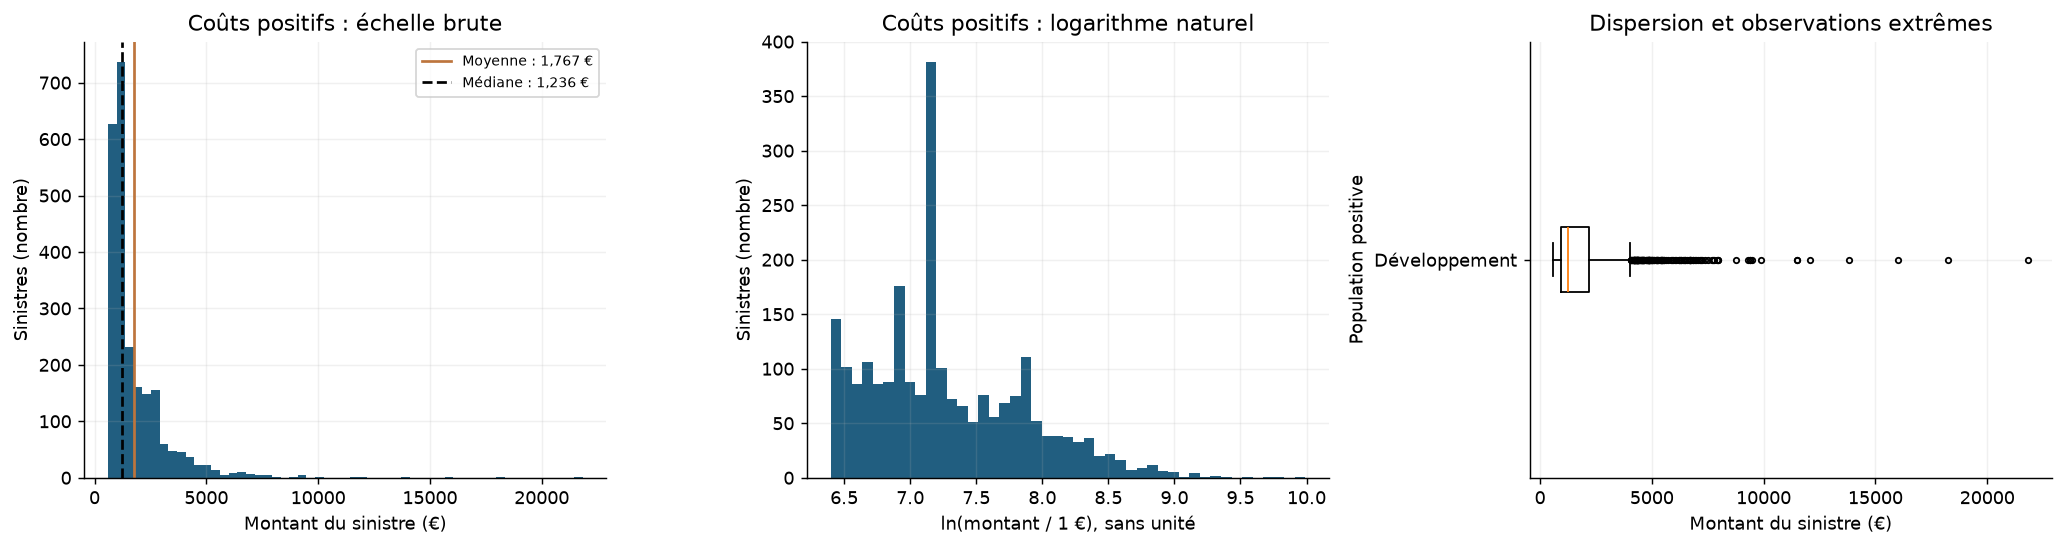

**Lecture :** moyenne **1,767.31 €**, médiane **1,236.00 €**, 99e centile **7,109.23 €**, maximum **21,826.96 €**. L’asymétrie est de 4.14. Les répétitions de montants sont réelles dans le fichier ; elles peuvent refléter des conventions d’indemnisation ou d’autres mécanismes, mais leur origine ne peut pas être établie ici. Un montant identique n’est pas un doublon de contrat.

In [9]:
target_summary = y.describe(percentiles=[0.01, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
target_summary.loc['asymétrie'] = y.skew()
target_summary.loc['coefficient_variation'] = y.std() / y.mean()
table(target_summary.rename_axis('statistique').reset_index(name='valeur'), '11_statistiques_cible')
repeated = y.value_counts().head(10).rename_axis('montant_euros').reset_index(name='effectif')
repeated['part_sinistres_pct'] = 100 * repeated['effectif'] / len(y)
table(repeated, '12_montants_repetes')

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
axes[0].hist(y, bins=55, color=PRIMARY)
axes[0].axvline(y.mean(), color=SECONDARY, label=f'Moyenne : {y.mean():,.0f} €')
axes[0].axvline(y.median(), color='black', ls='--', label=f'Médiane : {y.median():,.0f} €')
axes[0].set(title='Coûts positifs : échelle brute', xlabel='Montant du sinistre (€)', ylabel='Sinistres (nombre)')
axes[0].legend(fontsize=8)
axes[1].hist(np.log(y), bins=45, color=PRIMARY)
axes[1].set(title='Coûts positifs : logarithme naturel',
            xlabel='ln(montant / 1 €), sans unité', ylabel='Sinistres (nombre)')
axes[2].boxplot(y.to_numpy(), orientation='horizontal', flierprops={'markersize': 3})
axes[2].set(title='Dispersion et observations extrêmes', xlabel='Montant du sinistre (€)', ylabel='Population positive')
axes[2].set_yticks([1], ['Développement'])
figure(fig, '04_distribution_cible')
note(f'**Lecture :** moyenne **{y.mean():,.2f} €**, médiane **{y.median():,.2f} €**, '
     f'99e centile **{y.quantile(.99):,.2f} €**, maximum **{y.max():,.2f} €**. '
     f'L’asymétrie est de {y.skew():.2f}. Les répétitions de montants sont réelles dans le fichier ; '
     'elles peuvent refléter des conventions d’indemnisation ou d’autres mécanismes, '
     'mais leur origine ne peut pas être établie ici. Un montant identique n’est pas un doublon de contrat.')

### 2.2 Concentration du coût et poids des extrêmes

Les quantiles décrivent la position des observations ; les parts de coût indiquent
leur poids économique. La part de somme des carrés des montants décrit leur poids
potentiel sur un critère quadratique ; **ce n'est pas la part d'une erreur de modèle**,
puisqu'aucun modèle n'a été ajusté.

,quantile,seuil_euros,sinistres,part_sinistres_pct,part_coût_pct,part_carrés_montants_pct
0,0.900,"3,337.055",236,10.017,28.717,58.799
1,0.950,"4,347.745",118,5.008,17.909,44.864
2,0.990,"7,109.233",24,1.019,5.876,22.828


,tranche,effectif,coût_total_euros,part_sinistres_pct,part_coût_pct
0,0–<1 000,636,"484,879.690",26.995,11.645
1,1 000–<1 500,830,"1,004,013.030",35.229,24.113
2,1 500–<2 000,236,"410,204.950",10.017,9.852
3,2 000–<3 000,369,"913,751.170",15.662,21.945
4,3 000–<5 000,211,"810,162.180",8.956,19.457
5,≥5 000,74,"540,759.850",3.141,12.987


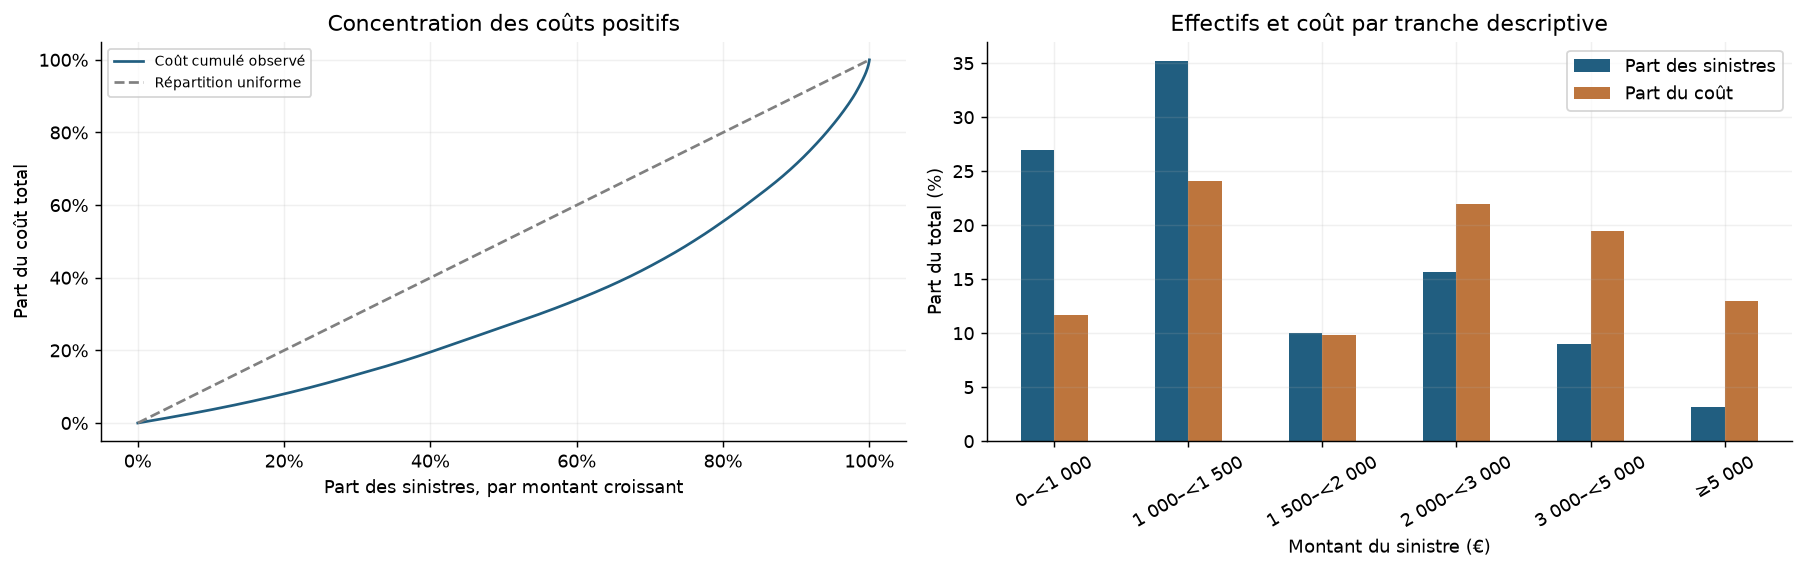

**Lecture :** au-dessus du 99e centile, 24 sinistres concentrent 5.9 % du coût et 22.8 % de la somme des carrés des montants. Ces observations sont conservées. Les tranches ci-dessus servent uniquement à décrire la distribution ; elles ne définissent pas des modèles par tranches.

In [10]:
tail_rows = []
for quantile in [0.90, 0.95, 0.99]:
    threshold = y.quantile(quantile)
    mask = y.ge(threshold)
    tail_rows.append({'quantile': quantile, 'seuil_euros': threshold, 'sinistres': int(mask.sum()),
                      'part_sinistres_pct': 100 * mask.mean(),
                      'part_coût_pct': 100 * y[mask].sum() / y.sum(),
                      'part_carrés_montants_pct': 100 * y[mask].pow(2).sum() / y.pow(2).sum()})
tail = pd.DataFrame(tail_rows)
table(tail, '13_concentration_cible')

bands = pd.cut(y, bins=[0, 1000, 1500, 2000, 3000, 5000, np.inf],
               labels=['0–<1 000', '1 000–<1 500', '1 500–<2 000',
                       '2 000–<3 000', '3 000–<5 000', '≥5 000'], right=False)
band_summary = pd.DataFrame({'tranche': bands, 'montant': y}).groupby('tranche', observed=False).agg(
    effectif=('montant', 'size'), coût_total_euros=('montant', 'sum'))
band_summary['part_sinistres_pct'] = 100 * band_summary['effectif'] / len(y)
band_summary['part_coût_pct'] = 100 * band_summary['coût_total_euros'] / y.sum()
table(band_summary.reset_index(), '14_tranches_descriptives_cible')
assert band_summary['effectif'].sum() == len(y)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sorted_y = np.sort(y)
axes[0].plot(np.r_[0, np.arange(1, len(y) + 1) / len(y)],
             np.r_[0, sorted_y.cumsum() / sorted_y.sum()], color=PRIMARY, label='Coût cumulé observé')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Répartition uniforme')
axes[0].set(title='Concentration des coûts positifs',
            xlabel='Part des sinistres, par montant croissant', ylabel='Part du coût total')
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].legend(fontsize=8)
band_summary[['part_sinistres_pct', 'part_coût_pct']].plot.bar(ax=axes[1], color=[PRIMARY, SECONDARY])
axes[1].set(title='Effectifs et coût par tranche descriptive', xlabel='Montant du sinistre (€)', ylabel='Part du total (%)')
axes[1].legend(['Part des sinistres', 'Part du coût'])
axes[1].tick_params(axis='x', rotation=30)
figure(fig, '05_concentration_cible')
q99 = tail.iloc[-1]
note(f'**Lecture :** au-dessus du 99e centile, {int(q99.sinistres)} sinistres '
     f'concentrent {q99["part_coût_pct"]:.1f} % du coût et '
     f'{q99["part_carrés_montants_pct"]:.1f} % de la somme des carrés des montants. '
     'Ces observations sont conservées. Les tranches ci-dessus servent uniquement à décrire la distribution ; '
     'elles ne définissent pas des modèles par tranches.')

## 3. Pertinence des données pour expliquer la gravité

### 3.1 Coût conditionnel selon chaque variable candidate

Pour chaque variable, on calcule le coût moyen et médian **chez les sinistrés**,
le nombre de sinistres et l'écart-type. Les variables numériques ayant plus de
10 valeurs sont regroupées par quantiles de leurs valeurs chez les sinistrés ;
les autres conservent leurs valeurs distinctes. Les manquants restent un groupe.

Les tables conservent toutes les modalités. Les graphiques montrent au plus huit
groupes par variable, choisis par effectif de sinistres ; les autres groupes ne
sont pas fusionnés silencieusement dans leurs moyennes. Un groupe de moins de
30 sinistres est signalé comme fragile. Ce seuil est un repère de lecture, pas
un critère automatique de sélection. Les moyennes sont descriptives et ne
démontrent ni causalité ni effet ajusté des autres variables.

,variable,groupe,sinistres,gravité_moyenne_euros,gravité_médiane_euros,erreur_standard_descriptive_euros,effectif_fragile_moins_30
2,type_contrat,Maxi,1948,"1,836.212","1,295.820",32.587,False
3,type_contrat,Median1,115,"1,564.391","1,236.000",212.055,False
4,type_contrat,Median2,236,"1,369.293","1,236.000",57.580,False
5,type_contrat,Mini,57,"1,469.692","1,236.000",233.274,False
24,utilisation,AllTrips,3,"1,402.173","1,336.410",253.998,True
25,utilisation,Professional,233,"1,951.324","1,240.890",116.095,False
26,utilisation,Retired,647,"1,674.625","1,236.000",43.648,False
27,utilisation,WorkPrivate,1473,"1,779.649","1,236.000",40.130,False
76,essence_vehicule,Diesel,1460,"1,761.222","1,236.000",37.905,False
77,essence_vehicule,Gasoline,890,"1,782.788","1,236.330",49.846,False


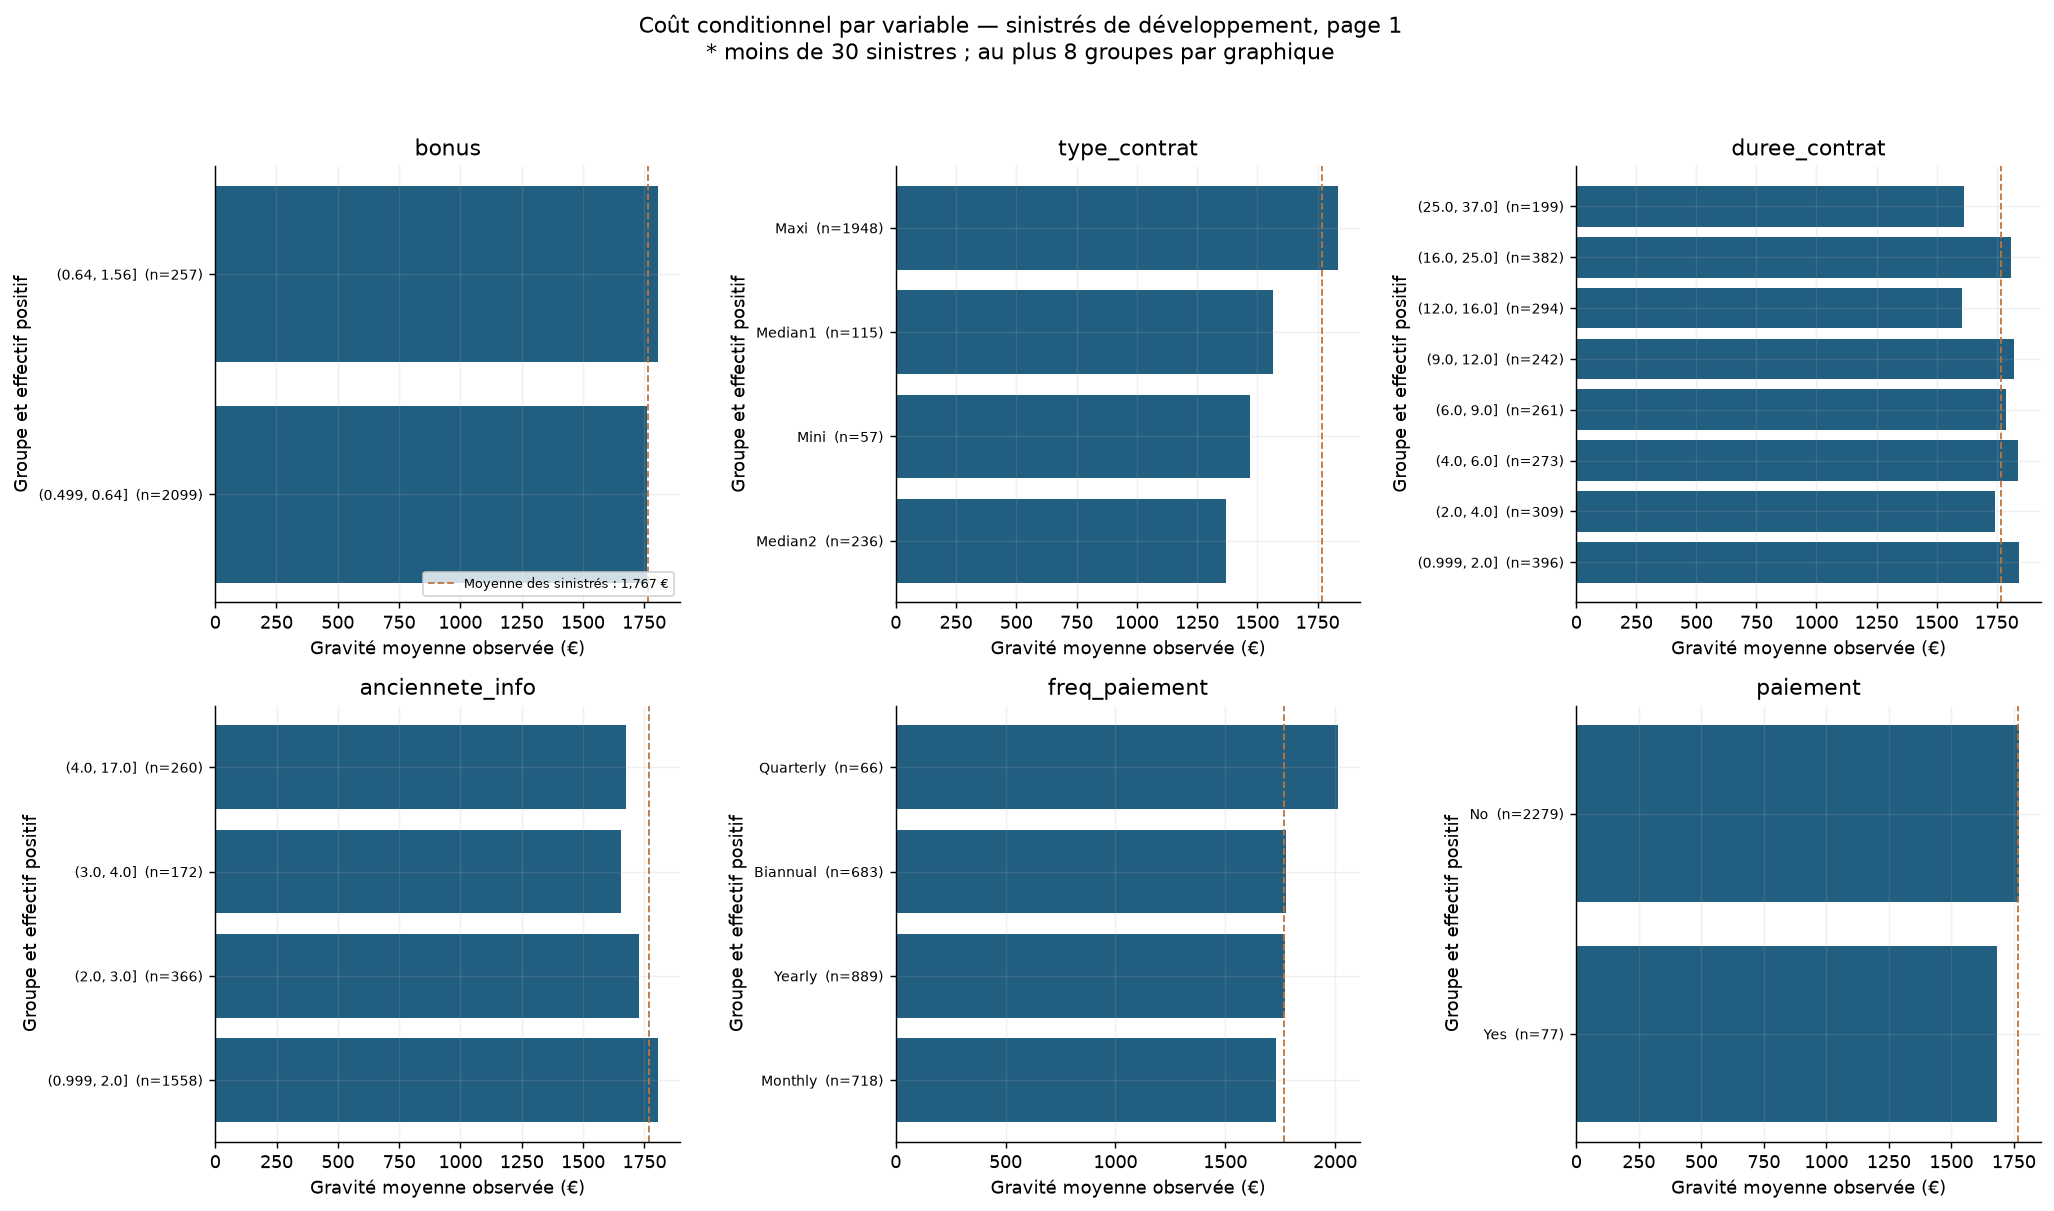

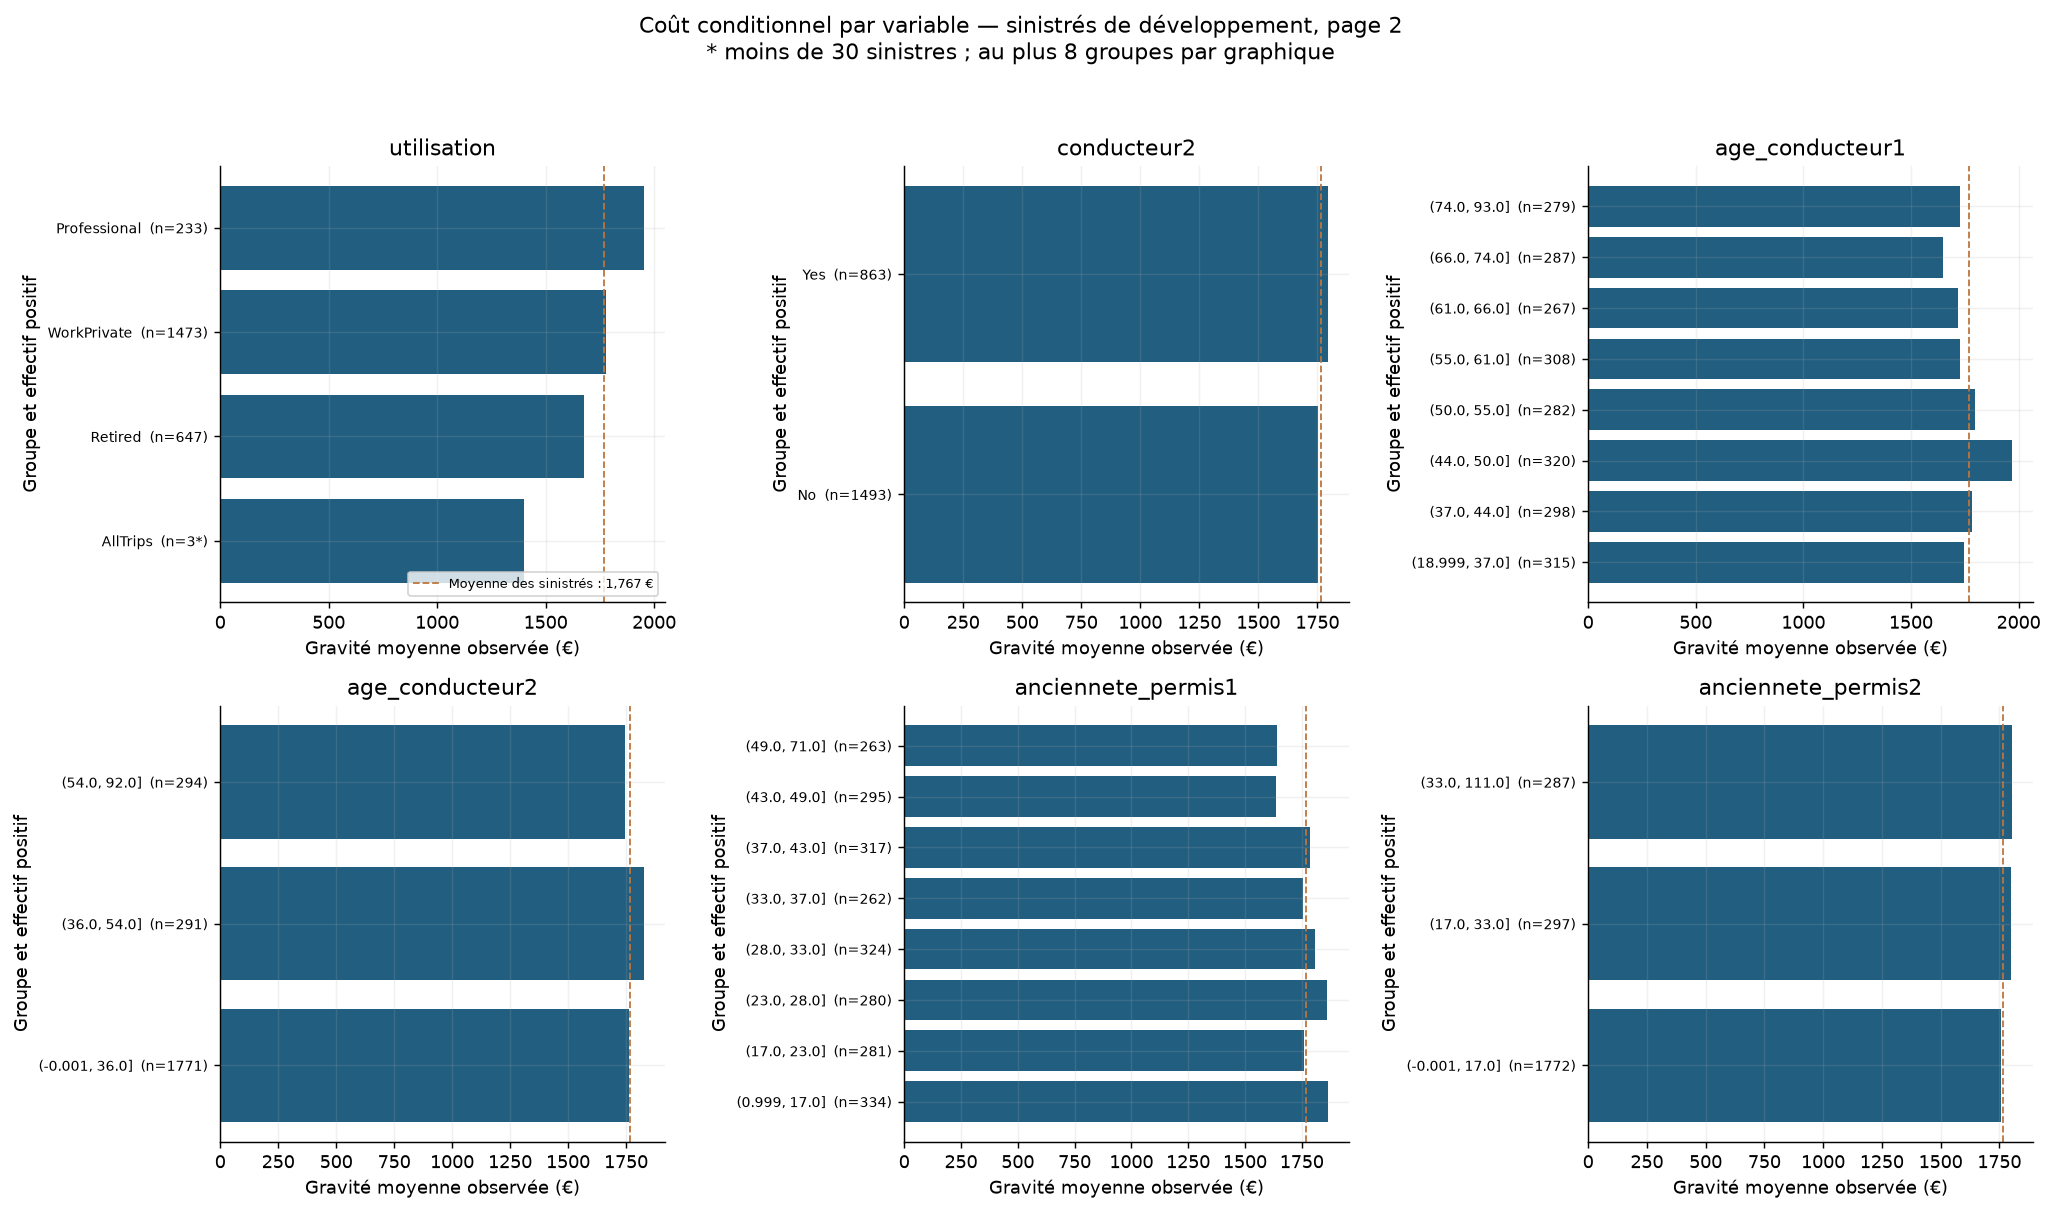

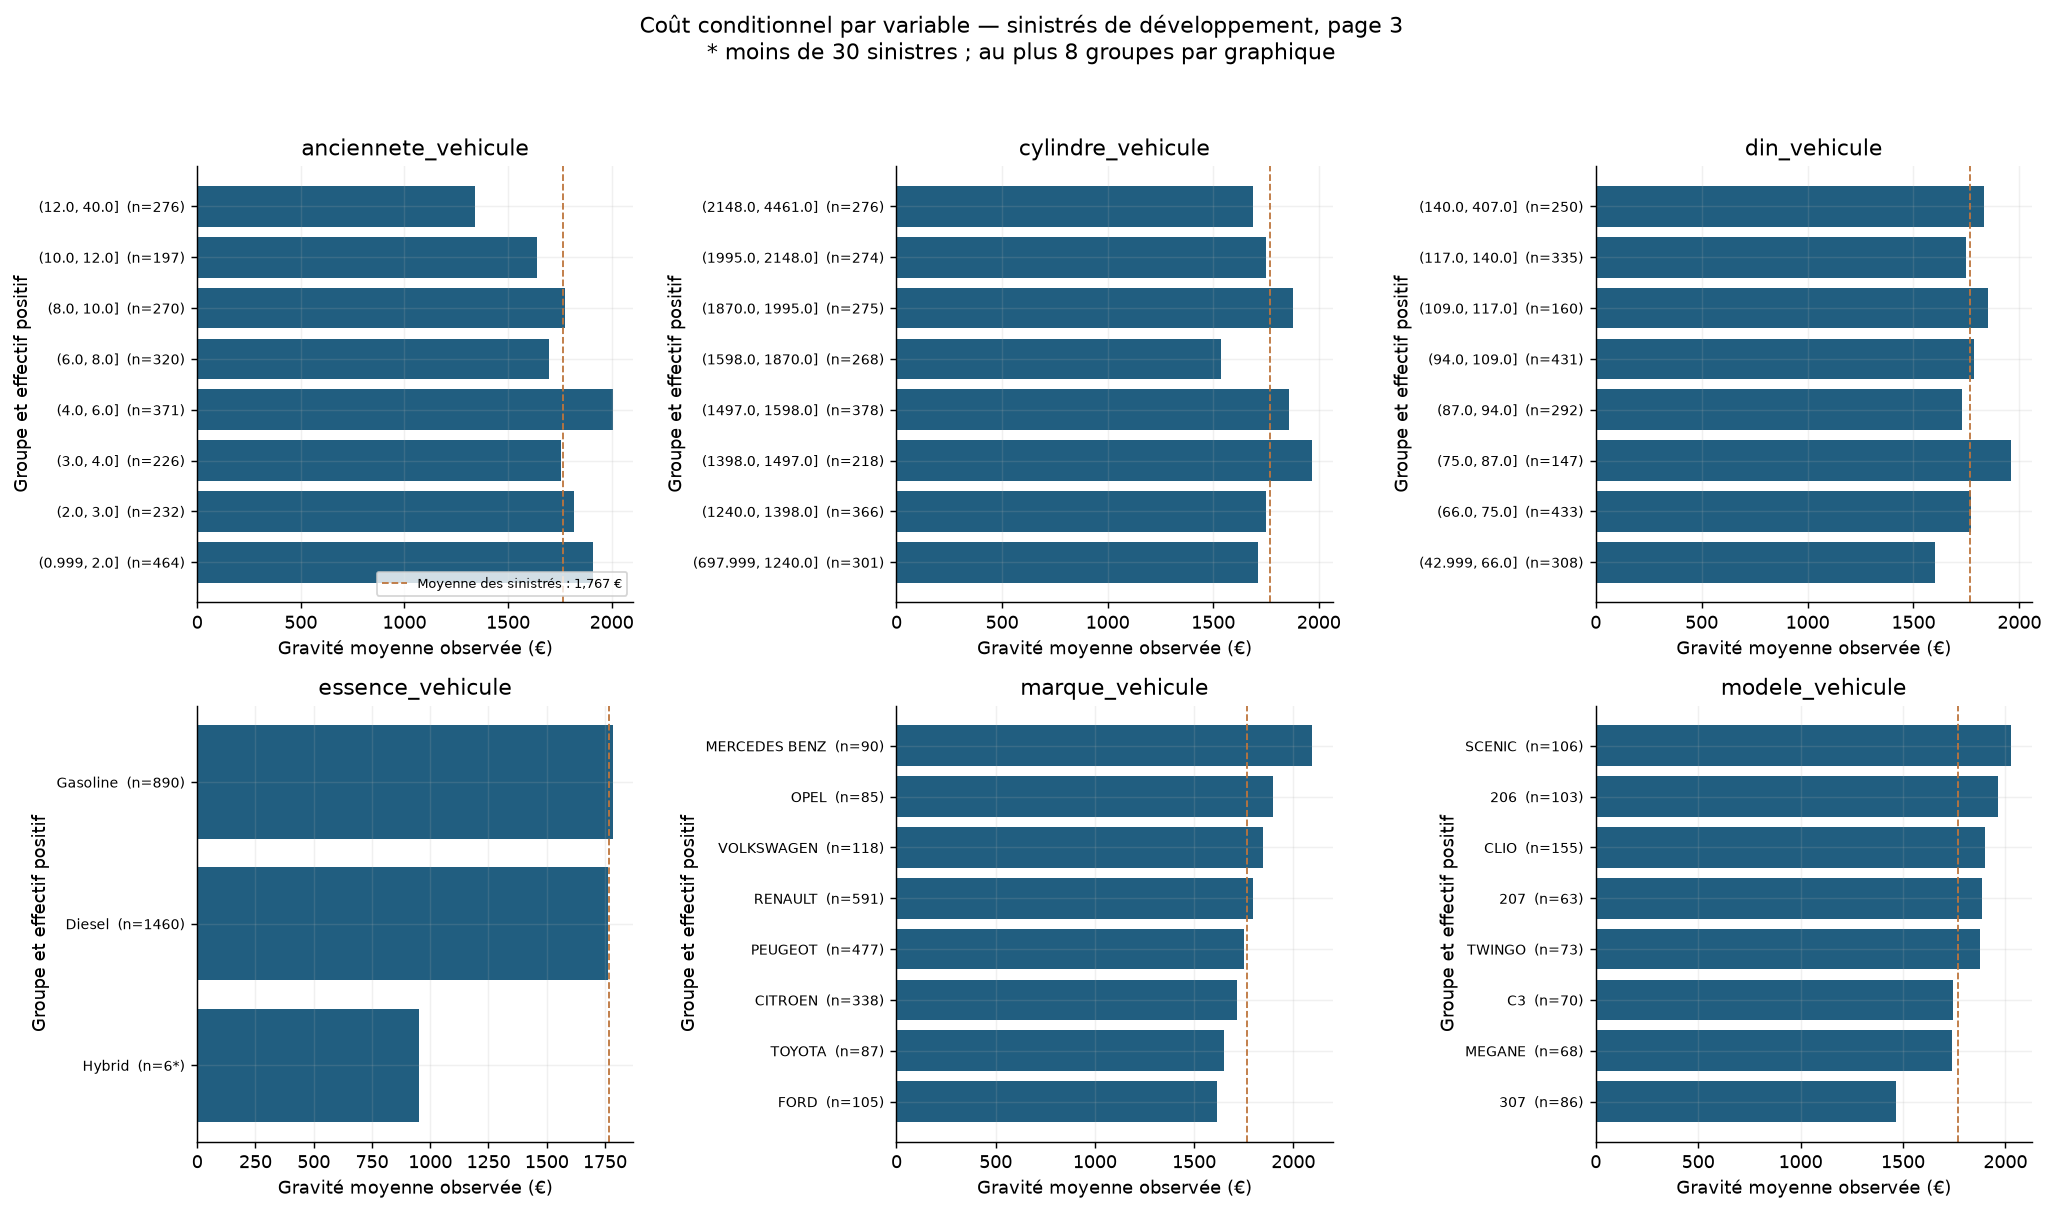

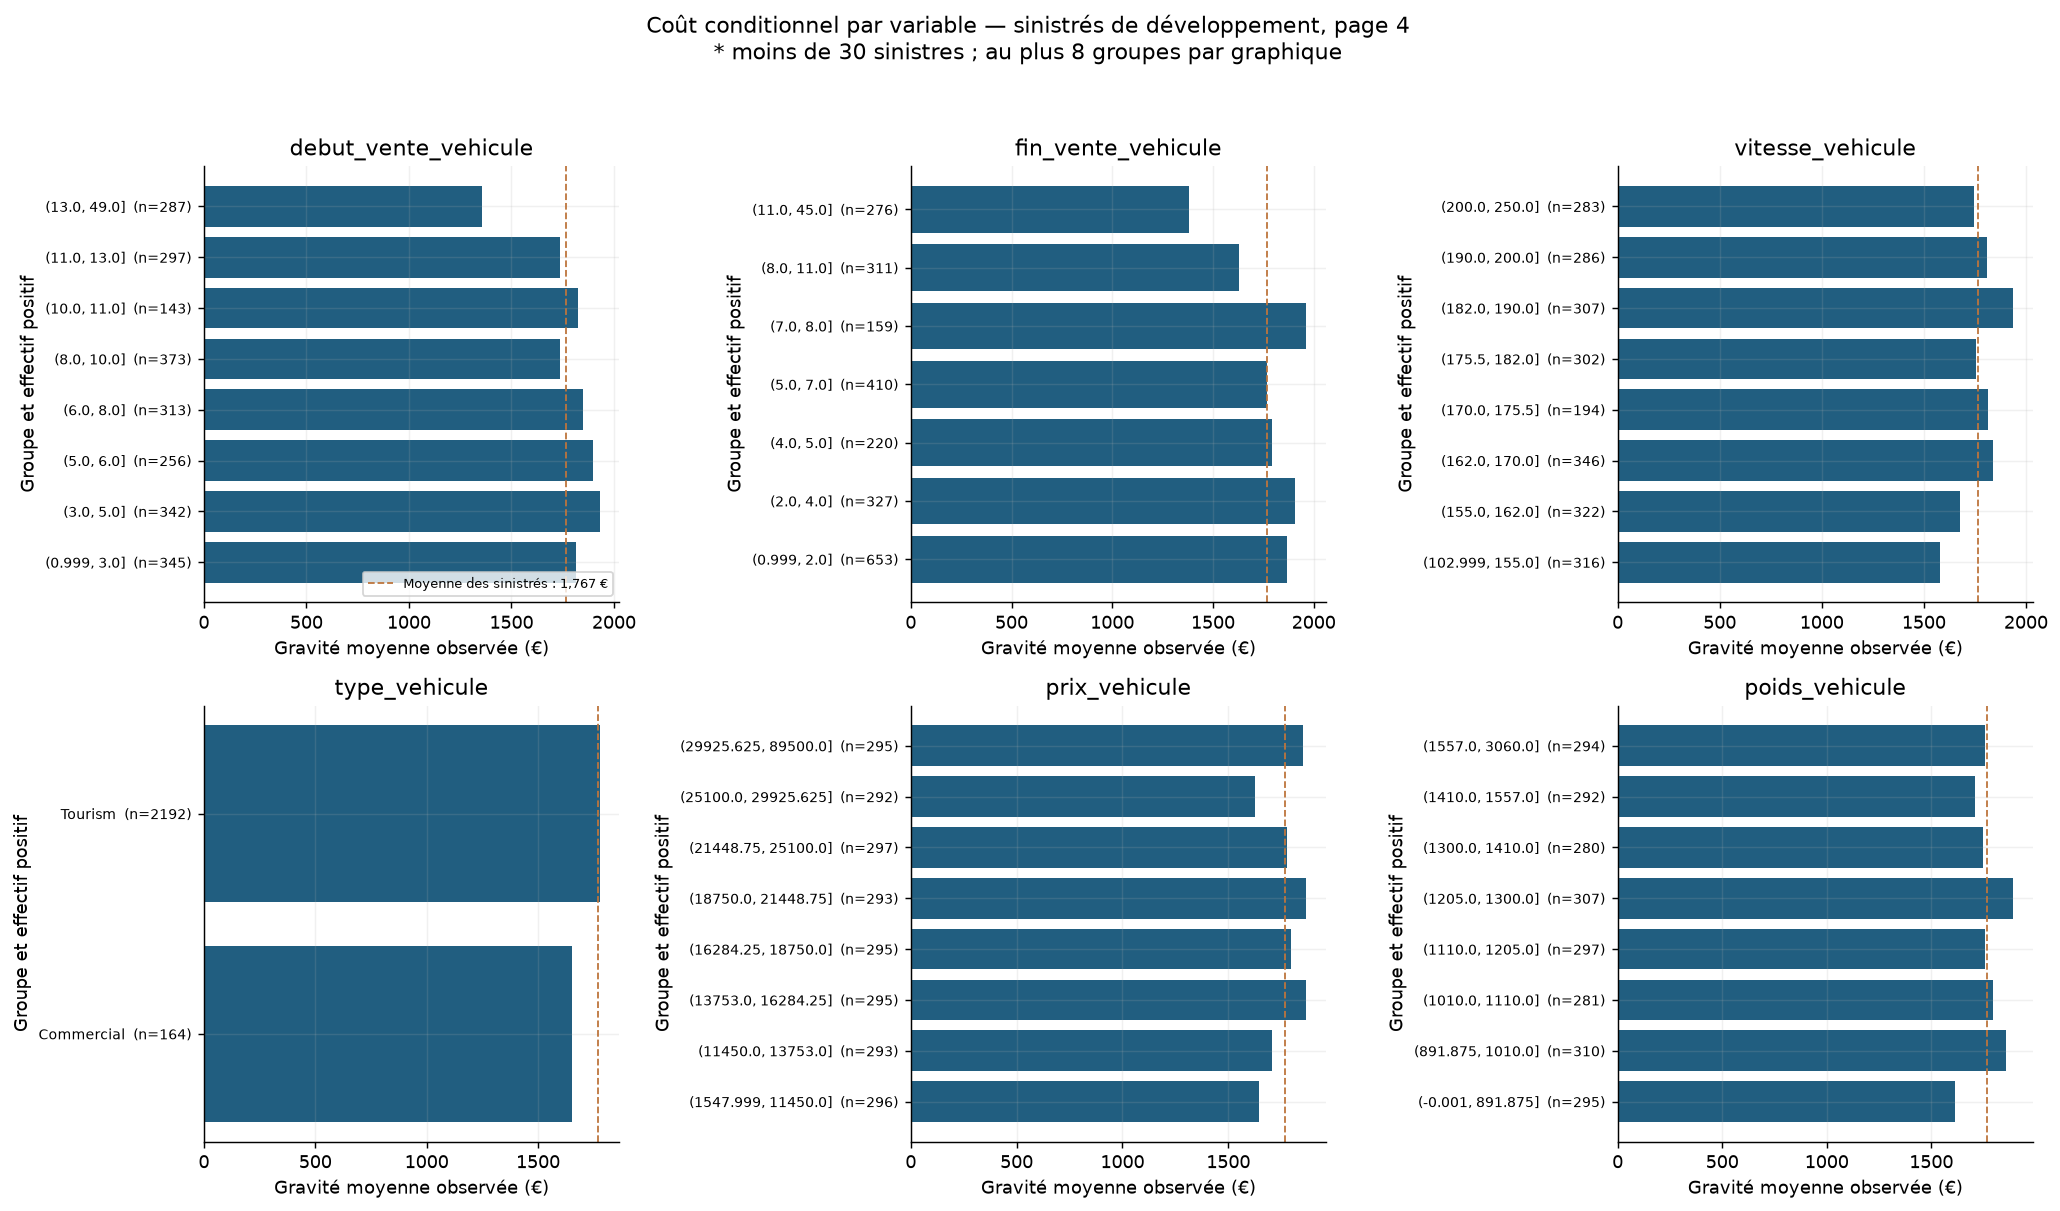

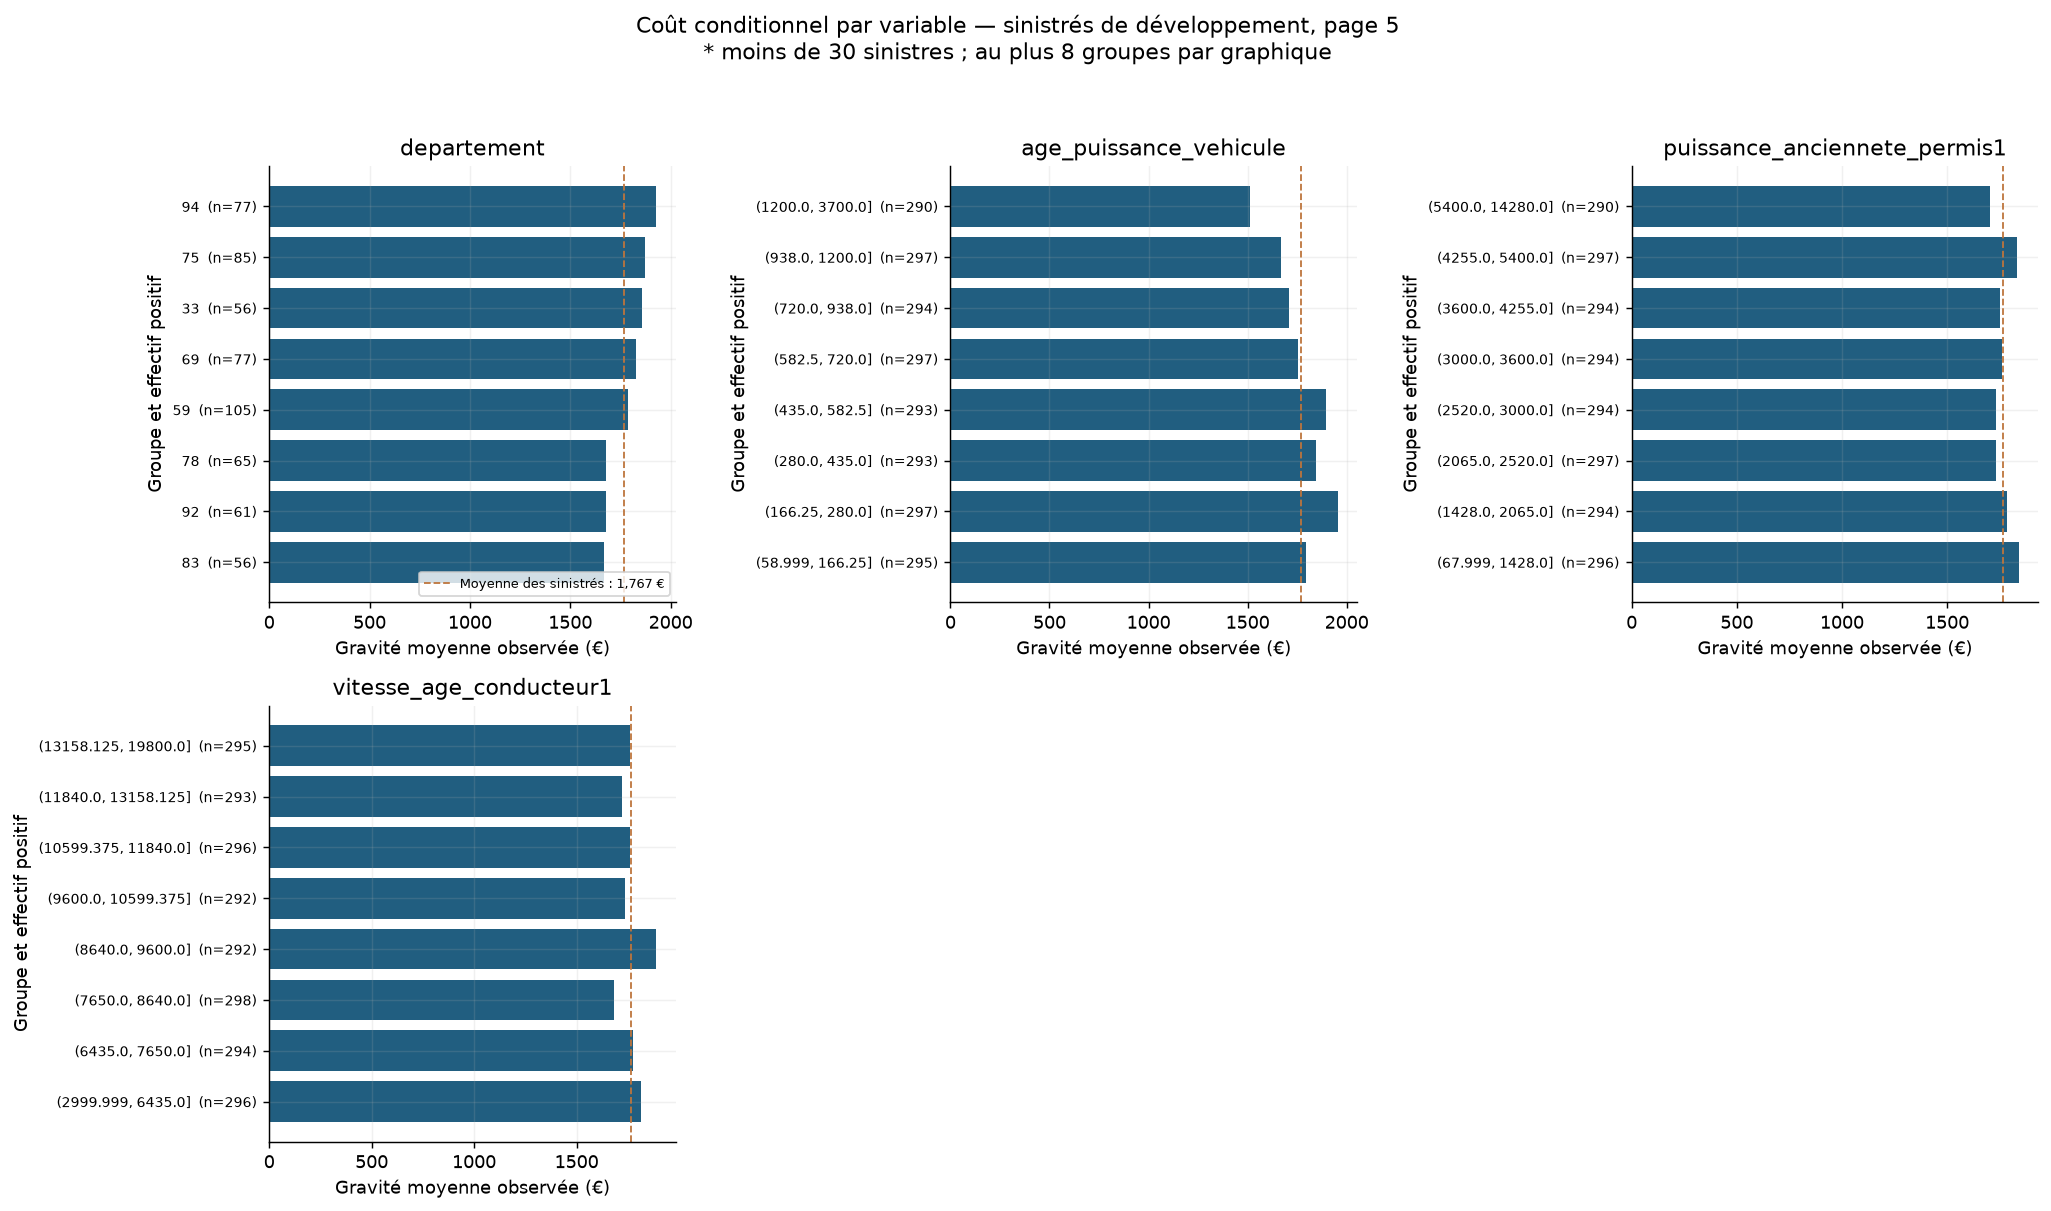

**Lecture :** comparer les niveaux de couverture avec leurs effectifs ; ne pas interpréter un coût moyen extrême porté par quelques sinistres comme un signal établi. L’erreur standard est seulement descriptive : elle ne corrige ni les dépendances clients ni les comparaisons multiples et n’est pas affichée comme intervalle de confiance.

In [11]:
relations = []
for col in FEATURES:
    s = gravite[col]
    if col in numeric and s.nunique() > 10:
        raw_groups = pd.qcut(s, q=8, duplicates='drop')
        # Préserver l’ordre numérique des intervalles dans les graphiques.
        labels = [str(interval) for interval in raw_groups.cat.categories]
        group = raw_groups.astype('string').fillna('⟨manquant⟩')
        order = {label: i for i, label in enumerate(labels)}
    else:
        group = s.astype('string').fillna('⟨manquant⟩')
        labels = sorted(group.unique().tolist())
        order = {label: i for i, label in enumerate(labels)}
    frame = pd.DataFrame({'groupe': group, 'montant': y})
    tab = frame.groupby('groupe', observed=True).agg(
        sinistres=('montant', 'size'), gravité_moyenne_euros=('montant', 'mean'),
        gravité_médiane_euros=('montant', 'median'), écart_type_euros=('montant', 'std'))
    tab['erreur_standard_descriptive_euros'] = tab['écart_type_euros'] / np.sqrt(tab['sinistres'])
    tab['ordre_groupe'] = [order.get(str(g), len(order)) for g in tab.index]
    tab['effectif_fragile_moins_30'] = tab['sinistres'].lt(30)
    tab = tab.reset_index()
    tab.insert(0, 'variable', col)
    relations.append(tab)
relations = pd.concat(relations, ignore_index=True)
relations.to_csv(REPORTS / '15_relations_toutes_variables_gravite.csv', index=False)
assert set(relations['variable']) == set(FEATURES)
assert relations.groupby('variable')['sinistres'].sum().eq(len(gravite)).all()
display(relations.loc[relations['variable'].isin(['type_contrat', 'utilisation', 'essence_vehicule'])]
        .drop(columns=['ordre_groupe', 'écart_type_euros']))

for page, start in enumerate(range(0, len(FEATURES), 6), 1):
    columns = FEATURES[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    for ax, col in zip(axes.flat, columns):
        t = relations.loc[relations['variable'].eq(col)].nlargest(8, 'sinistres').copy()
        if col in numeric:
            t = t.sort_values('ordre_groupe')
        else:
            t = t.sort_values('gravité_moyenne_euros')
        ax.barh(range(len(t)), t['gravité_moyenne_euros'], color=PRIMARY)
        ax.set_yticks(range(len(t)), [f'{str(g)[:30]}  (n={n}{"*" if n < 30 else ""})'
                                     for g, n in zip(t['groupe'], t['sinistres'])], fontsize=8)
        ax.axvline(y.mean(), color=SECONDARY, ls='--', lw=1,
                   label=f'Moyenne des sinistrés : {y.mean():,.0f} €')
        ax.set(title=col, xlabel='Gravité moyenne observée (€)', ylabel='Groupe et effectif positif')
    for ax in list(axes.flat)[len(columns):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=7, loc='lower right')
    fig.suptitle(f'Coût conditionnel par variable — sinistrés de développement, page {page}\n'
                 '* moins de 30 sinistres ; au plus 8 groupes par graphique', y=1.03)
    figure(fig, f'06_relations_gravite_{page}')
note('**Lecture :** comparer les niveaux de couverture avec leurs effectifs ; '
     'ne pas interpréter un coût moyen extrême porté par quelques sinistres comme un signal établi. '
     'L’erreur standard est seulement descriptive : elle ne corrige ni les dépendances clients '
     'ni les comparaisons multiples et n’est pas affichée comme intervalle de confiance.')

### 3.2 Corrélations numériques et redondances

La corrélation de Spearman mesure une association monotone. Elle est calculée sur
les variables brutes des sinistrés ; les codes suspects et les zéros structurels
peuvent donc l'affecter. Une corrélation proche de zéro n'exclut ni une relation
non linéaire ni une interaction. Une forte corrélation entre prédicteurs appelle
une comparaison ultérieure, pas une suppression immédiate.

Pearson est présenté en complément pour les associations linéaires. Les catégories
sont examinées par leurs coûts moyens et leurs effectifs, sans transformer leurs
étiquettes en numéros arbitraires ; le département est détaillé en section 5.1.

La **section 5.5** présente aussi les associations après préparation pour toutes les
entrées du modèle, y compris le département, toutes les interactions créées et
tous les indicateurs de manquant.

,variable,spearman_gravité,pearson_gravité,paires_non_manquantes
0,age_puissance_vehicule,-0.079,-0.083,2356
1,anciennete_vehicule,-0.075,-0.107,2356
2,fin_vente_vehicule,-0.068,-0.100,2356
3,debut_vente_vehicule,-0.059,-0.091,2356
4,cylindre_vehicule,-0.047,-0.017,2356
5,poids_vehicule,-0.035,0.010,2356
6,prix_vehicule,-0.031,0.022,2356
7,din_vehicule,-0.020,0.026,2356
8,puissance_anciennete_permis1,-0.018,-0.021,2356
9,duree_contrat,-0.017,-0.034,2356


,variable_1,variable_2,spearman
2,age_conducteur2,anciennete_permis2,0.984
5,anciennete_vehicule,debut_vente_vehicule,0.934
0,age_conducteur1,anciennete_permis1,0.924
13,debut_vente_vehicule,fin_vente_vehicule,0.916
1,age_conducteur1,vitesse_age_conducteur1,0.913
7,anciennete_vehicule,age_puissance_vehicule,0.906
6,anciennete_vehicule,fin_vente_vehicule,0.903
11,din_vehicule,prix_vehicule,0.878
4,anciennete_permis1,vitesse_age_conducteur1,0.855
17,puissance_anciennete_permis1,vitesse_age_conducteur1,0.828


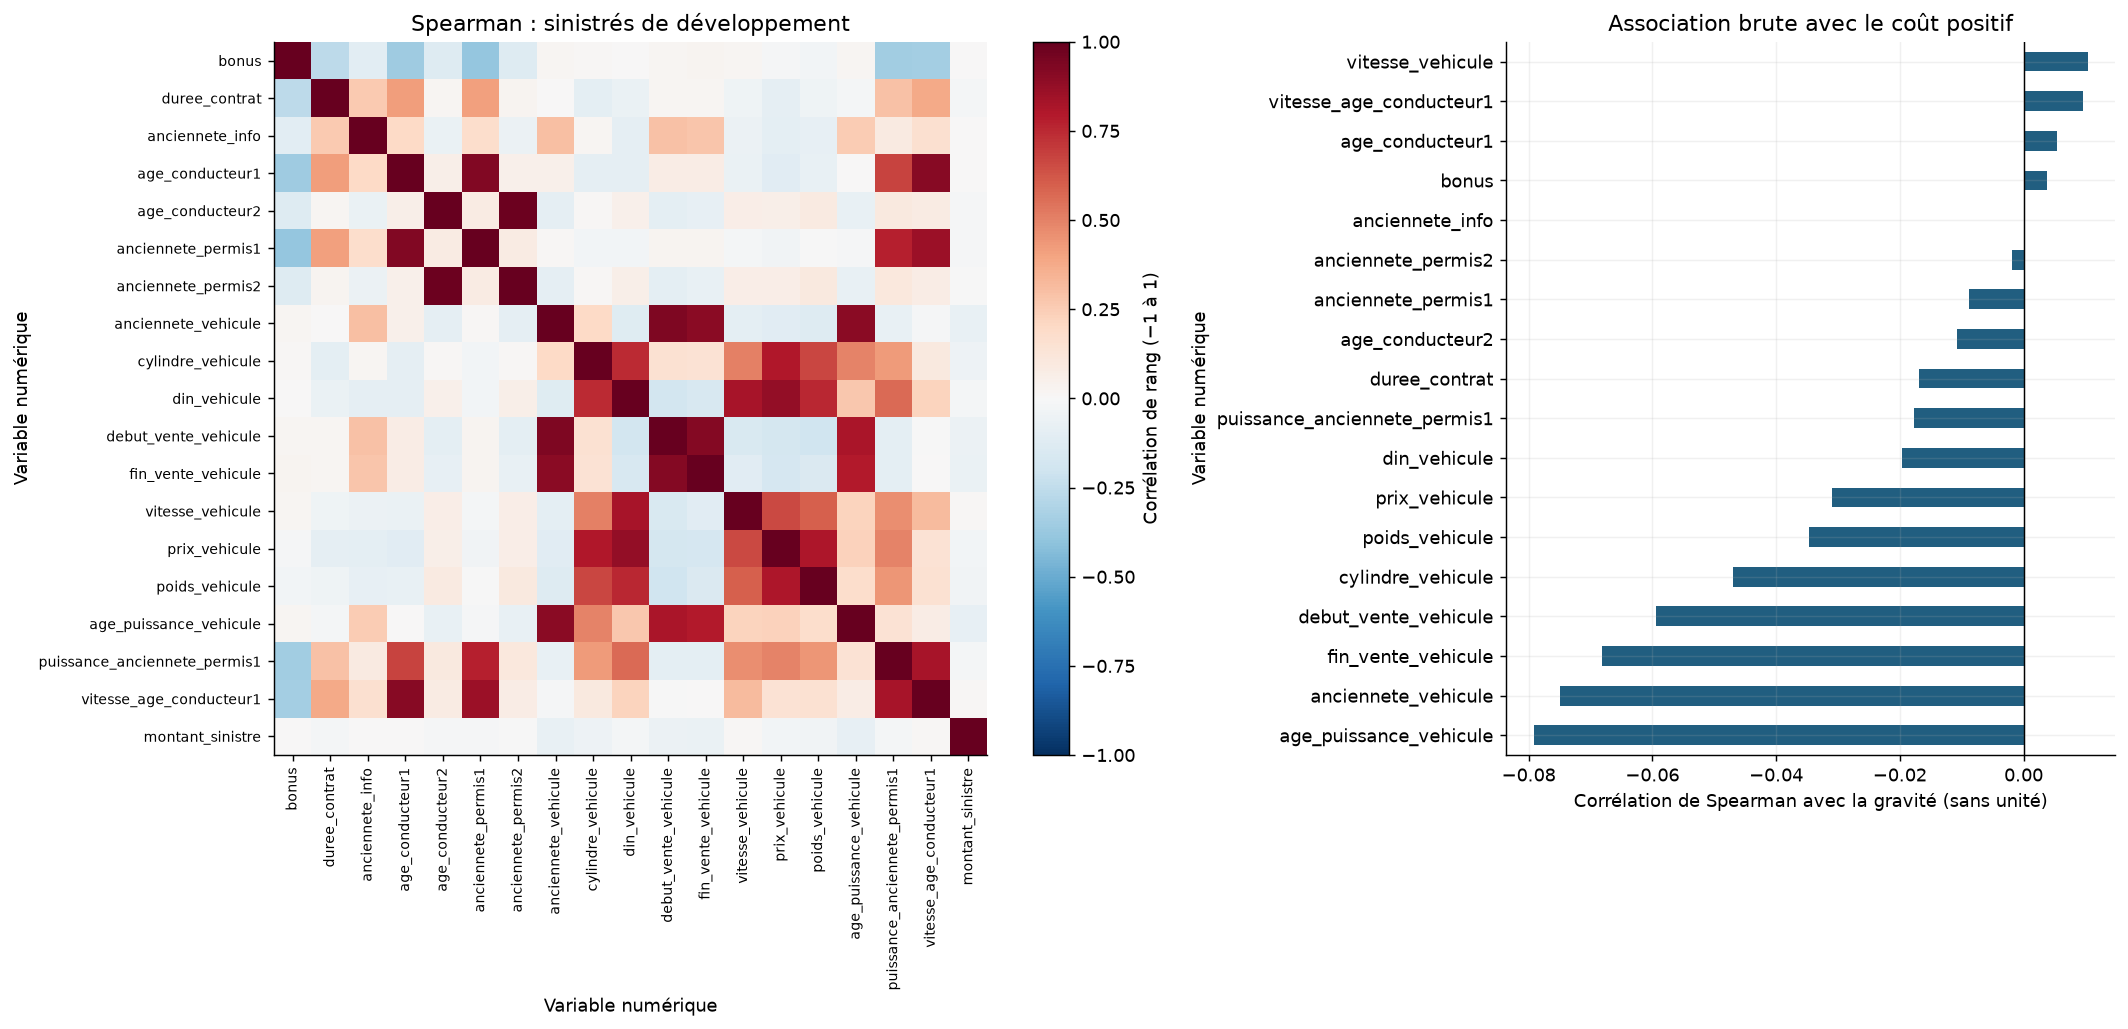

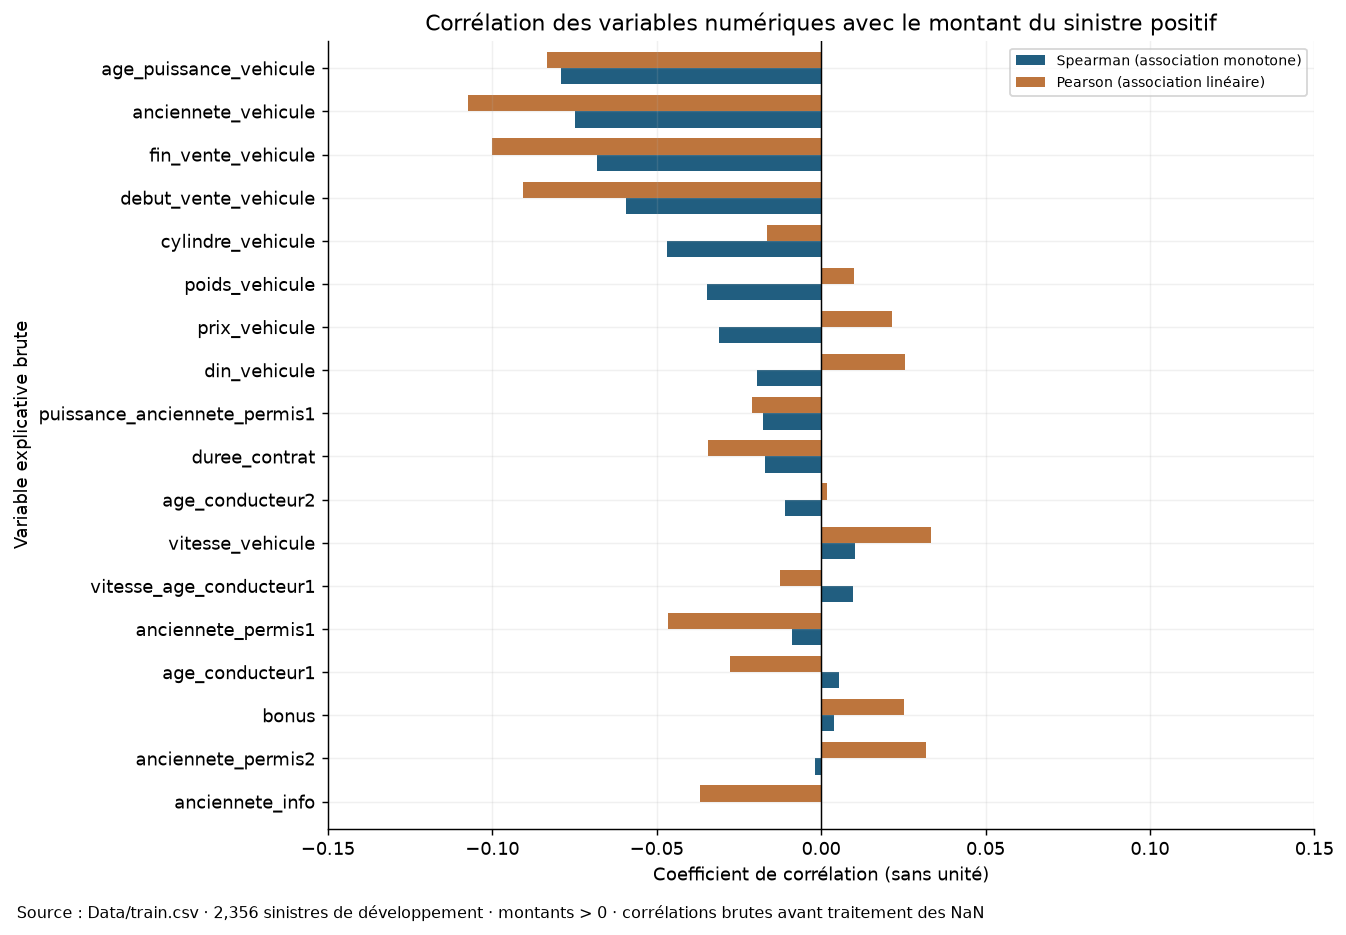

**Lecture :** la plus forte association monotone brute avec la cible est celle de `age_puissance_vehicule` (ρ = -0.079). Les associations individuelles restent faibles dans ces données ; elles ne justifient pas une sélection définitive des variables. Les blocs techniques et les anciennetés devront être comparés en validation par client.

In [12]:
corr = gravite[numeric + [TARGET]].corr(method='spearman')
target_corr = corr[TARGET].drop(TARGET).rename('spearman_gravité').sort_values(key=abs, ascending=False)
pearson = gravite[numeric + [TARGET]].corr(method='pearson')[TARGET].drop(TARGET)
correlations_cible = target_corr.to_frame().join(pearson.rename('pearson_gravité'))
correlations_cible['paires_non_manquantes'] = [gravite[[col, TARGET]].dropna().shape[0]
                                           for col in correlations_cible.index]
table(correlations_cible.rename_axis('variable').reset_index(), '16_correlations_cible')
corr.rename_axis('variable').reset_index().to_csv(REPORTS / '17_matrice_spearman.csv', index=False)
pairs = []
for i, left in enumerate(numeric):
    for right in numeric[i + 1:]:
        rho = corr.loc[left, right]
        if pd.notna(rho) and abs(rho) >= 0.70:
            pairs.append({'variable_1': left, 'variable_2': right, 'spearman': rho})
redundancy = pd.DataFrame(pairs, columns=['variable_1', 'variable_2', 'spearman'])
if len(redundancy):
    redundancy = redundancy.sort_values('spearman', key=abs, ascending=False)
table(redundancy, '18_redondances_fortes')

fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={'width_ratios': [1.5, 1]})
im = axes[0].imshow(corr.to_numpy(), vmin=-1, vmax=1, cmap='RdBu_r')
axes[0].set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
axes[0].set_yticks(range(len(corr)), corr.index, fontsize=8)
axes[0].set(title='Spearman : sinistrés de développement', xlabel='Variable numérique', ylabel='Variable numérique')
axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=.046, label='Corrélation de rang (−1 à 1)')
target_corr.sort_values().plot.barh(ax=axes[1], color=PRIMARY)
axes[1].set(title='Association brute avec le coût positif',
            xlabel='Corrélation de Spearman avec la gravité (sans unité)', ylabel='Variable numérique')
axes[1].axvline(0, color='black', lw=.8)
figure(fig, '07_correlations')

fig, ax = plt.subplots(figsize=(10.5, 7))
plot_corr = correlations_cible[['spearman_gravité', 'pearson_gravité']].iloc[::-1]
plot_corr.plot.barh(ax=ax, color=[PRIMARY, SECONDARY], width=.75)
ax.set(title='Corrélation des variables numériques avec le montant du sinistre positif',
       xlabel='Coefficient de corrélation (sans unité)', ylabel='Variable explicative brute')
ax.axvline(0, color='black', lw=.8)
bound = max(0.15, np.nanmax(np.abs(plot_corr.to_numpy())) * 1.25)
ax.set_xlim(-bound, bound)
ax.legend(handles=list(ax.containers),
          labels=['Spearman (association monotone)', 'Pearson (association linéaire)'], fontsize=8)
fig.text(.02, -.015, f'Source : Data/train.csv · {len(gravite):,} sinistres de développement · '
                     'montants > 0 · corrélations brutes avant traitement des NaN', fontsize=9)
figure(fig, '10_correlations_cible')
note(f'**Lecture :** la plus forte association monotone brute avec la cible est celle de '
     f'`{target_corr.index[0]}` (ρ = {target_corr.iloc[0]:.3f}). '
     'Les associations individuelles restent faibles dans ces données ; '
     'elles ne justifient pas une sélection définitive des variables. '
     'Les blocs techniques et les anciennetés devront être comparés en validation par client.')

### 3.3 Modalités rares et compatibilité avec le test

Le modèle de gravité sera ajusté sur les **sinistrés**. Une catégorie présente dans
le portefeuille peut donc rester inconnue de son échantillon d'ajustement. On mesure
deux couvertures : modalités du test absentes du portefeuille de développement,
et modalités du test absentes des seuls sinistrés.

Les comparaisons numériques ci-dessous portent uniquement sur les entrées. L'écart
de médiane rapporté à l'IQR du portefeuille de développement est un repère descriptif ;
il ne mesure ni une dérive temporelle démontrée ni une performance prédictive.

,variable,modalités_dev,modalités_gravité,modalités_test,modalités_test_absentes_dev,part_test_absente_dev_pct,modalités_test_absentes_gravité,part_test_absente_gravité_pct
0,type_contrat,4,4,4,0,0.000,0,0.000
1,freq_paiement,4,4,4,0,0.000,0,0.000
2,paiement,2,2,2,0,0.000,0,0.000
3,utilisation,4,4,4,0,0.000,0,0.000
4,conducteur2,2,2,2,0,0.000,0,0.000
5,essence_vehicule,3,3,3,0,0.000,0,0.000
6,marque_vehicule,84,45,88,14,0.044,43,0.496
7,modele_vehicule,841,322,894,160,0.520,576,7.936
8,type_vehicule,2,2,2,0,0.000,0,0.000
9,departement,96,95,96,0,0.000,1,0.026


,variable,médiane_dev,médiane_test,Q01_dev,Q01_test,Q99_dev,Q99_test,écart_médianes_sur_IQR_dev,part_test_hors_min_max_dev_pct
0,bonus,0.500,0.500,0.500,0.500,0.950,0.950,NaN,0.000
1,duree_contrat,9.000,9.000,1.000,1.000,31.000,31.000,0.000,0.000
2,anciennete_info,2.000,2.000,1.000,1.000,12.000,12.000,0.000,0.000
3,age_conducteur1,54.000,54.000,24.000,24.000,86.000,86.000,0.000,0.002
4,age_conducteur2,0.000,0.000,0.000,0.000,78.000,78.000,0.000,0.000
5,anciennete_permis1,32.000,33.000,4.000,4.000,61.000,61.000,0.050,0.000
6,anciennete_permis2,0.000,0.000,0.000,0.000,59.000,57.010,0.000,0.000
7,anciennete_vehicule,8.000,8.000,1.000,1.000,33.000,33.000,0.000,0.002
8,cylindre_vehicule,"1,587.000","1,587.000",602.000,602.000,"2,993.000","2,987.000",0.000,0.000
9,din_vehicule,87.000,87.000,30.000,30.000,210.000,207.000,0.000,0.012


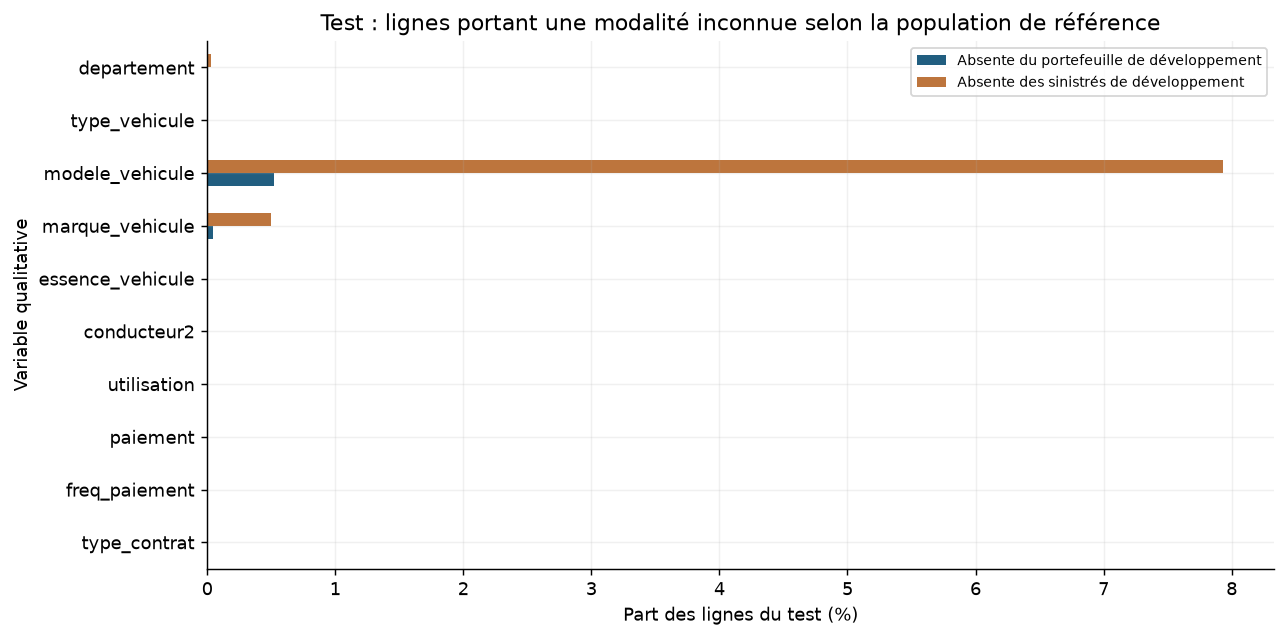

**Conséquence :** prévoir un encodage qui accepte des modalités inconnues. Les regroupements de marque / modèle ou de géographie sont des hypothèses à tester sur le train ; la cible du test est indisponible. Le département remplace le code fin ; aucun code ordinal ni coût moyen par département n’est injecté dans les entrées.

In [13]:
coverage_rows = []
for col in categorical:
    test_s = test[col].astype('string').fillna('⟨manquant⟩')
    dev_s = dev_portfolio[col].astype('string').fillna('⟨manquant⟩')
    positive_s = gravite[col].astype('string').fillna('⟨manquant⟩')
    unseen_portfolio = ~test_s.isin(dev_s.unique())
    unseen_severity = ~test_s.isin(positive_s.unique())
    coverage_rows.append({
        'variable': col, 'modalités_dev': dev_s.nunique(), 'modalités_gravité': positive_s.nunique(),
        'modalités_test': test_s.nunique(),
        'modalités_test_absentes_dev': test_s[unseen_portfolio].nunique(),
        'part_test_absente_dev_pct': 100 * unseen_portfolio.mean(),
        'modalités_test_absentes_gravité': test_s[unseen_severity].nunique(),
        'part_test_absente_gravité_pct': 100 * unseen_severity.mean(),
    })
coverage = pd.DataFrame(coverage_rows)
table(coverage, '19_couverture_categories_test')

shift_rows = []
for col in numeric:
    ref, future = dev_portfolio[col].dropna(), test[col].dropna()
    iqr = ref.quantile(.75) - ref.quantile(.25)
    shift_rows.append({'variable': col, 'médiane_dev': ref.median(), 'médiane_test': future.median(),
                       'Q01_dev': ref.quantile(.01), 'Q01_test': future.quantile(.01),
                       'Q99_dev': ref.quantile(.99), 'Q99_test': future.quantile(.99),
                       'écart_médianes_sur_IQR_dev': (future.median() - ref.median()) / iqr if iqr > 0 else np.nan,
                       'part_test_hors_min_max_dev_pct': 100 * ((future < ref.min()) | (future > ref.max())).mean()})
shift = pd.DataFrame(shift_rows)
table(shift, '20_comparaison_numerique_test')

fig, ax = plt.subplots(figsize=(10, 5))
coverage.set_index('variable')[['part_test_absente_dev_pct', 'part_test_absente_gravité_pct']].plot.barh(
    ax=ax, color=[PRIMARY, SECONDARY])
ax.set(title='Test : lignes portant une modalité inconnue selon la population de référence',
       xlabel='Part des lignes du test (%)', ylabel='Variable qualitative')
ax.legend(['Absente du portefeuille de développement', 'Absente des sinistrés de développement'], fontsize=8)
figure(fig, '08_modalites_inconnues_test')
note('**Conséquence :** prévoir un encodage qui accepte des modalités inconnues. '
     'Les regroupements de marque / modèle ou de géographie sont des hypothèses à tester '
     'sur le train ; la cible du test est indisponible. '
     'Le département remplace le code fin ; aucun code ordinal ni coût moyen par département n’est injecté dans les entrées.')

### 3.4 Cohérence métier et décisions à préparer

La pertinence repose sur la disponibilité à la prédiction, la qualité et une
hypothèse métier vérifiable. Les associations ci-dessus sont exploratoires ;
elles ne démontrent pas qu'une variable améliore un futur modèle. Les choix
d'imputation, de regroupement et de sélection seront ajustés uniquement dans
les sous-trains, puis comparés sur les mêmes plis par client.

In [14]:
decisions = pd.DataFrame([
    {'bloc': 'Identifiants et ordre', 'variables': ', '.join(IDS),
     'constat': 'Identité / ordre technique ; trois identifiants absents du test.',
     'suite': 'Exclure des entrées ; garder id_client pour les découpages.'},
    {'bloc': 'Informations de sinistre', 'variables': ', '.join(TARGETS),
     'constat': 'Informations observées après le sinistre.',
     'suite': 'Montant positif comme cible ; nombre uniquement comme contrôle du filtre.'},
    {'bloc': 'Sexe des conducteurs', 'variables': ', '.join(SEXES),
     'constat': 'Exclusion déjà retenue dans le projet.',
     'suite': 'Conserver cette convention pour le nouveau modèle.'},
    {'bloc': 'Couverture et usage', 'variables': 'type_contrat, utilisation',
     'constat': 'Différences descriptives de coût ; certains groupes peu représentés.',
     'suite': 'Candidats ; comparer leur apport en validation, sans conclusion causale.'},
    {'bloc': 'Véhicule', 'variables': 'prix, ancienneté, puissance, poids, cylindrée, vitesse, âge × puissance',
     'constat': 'Mesures techniques partiellement redondantes ; zéros suspects.',
     'suite': 'Croisements âge véhicule × puissance, puissance × permis1 et vitesse × âge conducteur1 ; comparer leur apport en validation.'},
    {'bloc': 'Identité automobile', 'variables': 'marque_vehicule, modele_vehicule',
     'constat': 'Fragmentation et modalités inconnues chez les sinistrés.',
     'suite': 'Tester regroupements sans utiliser les moyennes globales de la cible.'},
    {'bloc': 'Conducteurs', 'variables': 'âges, anciennetés permis, conducteur2',
     'constat': 'Zéros structurels et codes suspects ; effets bruts faibles.',
     'suite': 'Séparer absence et inconnue ; conserver un indicateur de présence.'},
    {'bloc': 'Géographie', 'variables': 'code_postal → departement',
     'constat': 'Nombreuses modalités ; définition de codification à confirmer.',
     'suite': 'Remplacer le code fin par departement, catégorie nominale ; aucun coût externe ajouté.'},
    {'bloc': 'Gestion du contrat', 'variables': 'bonus, durées, paiement et périodicité',
     'constat': 'Définitions / unités partiellement documentées.',
     'suite': 'Confirmer leur disponibilité avant sinistre ; ne pas inventer une exposition.'},
    {'bloc': 'Coûts extrêmes', 'variables': 'montant_sinistre positif',
     'constat': 'Queue à droite et concentration du coût.',
     'suite': 'Conserver ; analyser ensuite les erreurs sur les grands montants.'},
])
table(decisions, '21_decisions_pour_traitement')

,bloc,variables,constat,suite
0,Identifiants et ordre,"index, id_client, id_vehicule, id_contrat",Identité / ordre technique ; trois identifiant...,Exclure des entrées ; garder id_client pour le...
1,Informations de sinistre,"nombre_sinistres, montant_sinistre",Informations observées après le sinistre.,Montant positif comme cible ; nombre uniquemen...
2,Sexe des conducteurs,"sex_conducteur1, sex_conducteur2",Exclusion déjà retenue dans le projet.,Conserver cette convention pour le nouveau mod...
3,Couverture et usage,"type_contrat, utilisation",Différences descriptives de coût ; certains gr...,Candidats ; comparer leur apport en validation...
4,Véhicule,"prix, ancienneté, puissance, poids, cylindrée,...",Mesures techniques partiellement redondantes ;...,"Croisements âge véhicule × puissance, puissanc..."
5,Identité automobile,"marque_vehicule, modele_vehicule",Fragmentation et modalités inconnues chez les ...,Tester regroupements sans utiliser les moyenne...
6,Conducteurs,"âges, anciennetés permis, conducteur2",Zéros structurels et codes suspects ; effets b...,Séparer absence et inconnue ; conserver un ind...
7,Géographie,code_postal → departement,Nombreuses modalités ; définition de codificat...,"Remplacer le code fin par departement, catégor..."
8,Gestion du contrat,"bonus, durées, paiement et périodicité",Définitions / unités partiellement documentées.,Confirmer leur disponibilité avant sinistre ; ...
9,Coûts extrêmes,montant_sinistre positif,Queue à droite et concentration du coût.,Conserver ; analyser ensuite les erreurs sur l...


## 4. Synthèse de l'analyse et prochaine étape

Les constats ci-dessous sont calculés automatiquement pour rester cohérents lors
d'une réexécution. La section suivante réalise le **traitement des NaN** et matérialise le **80/20**.
Le département est la seule variable géographique candidate. Les encodages propres
au futur modèle et leur comparaison en validation viendront ensuite.

In [15]:
contract = relations.loc[relations['variable'].eq('type_contrat')]
largest_unknown = coverage.sort_values('part_test_absente_gravité_pct', ascending=False).iloc[0]
facts = {
    'objectif': 'E[montant_sinistre | montant_sinistre > 0, X]',
    'contrats_developpement': len(dev_portfolio),
    'sinistres_positifs_developpement': len(gravite),
    'clients_sinistres_developpement': int(gravite['id_client'].nunique()),
    'moyenne_euros': float(y.mean()), 'mediane_euros': float(y.median()),
    'maximum_euros': float(y.max()), 'quantile_99_euros': float(y.quantile(.99)),
    'part_cout_au_dessus_q99_pct': float(q99['part_coût_pct']),
    'variables_candidates': len(FEATURES),
    'interaction_age_puissance': 'anciennete_vehicule * din_vehicule',
    'interactions': {name: ' * '.join(sources) for name, sources in INTERACTION_SOURCES.items()},
    'variable_plus_forte_correlation_brute': str(target_corr.index[0]),
    'plus_forte_correlation_brute': float(target_corr.iloc[0]),
    'poids_non_positifs_developpement': int(dev_portfolio['poids_vehicule'].le(0).sum()),
}
(REPORTS / 'synthese.json').write_text(json.dumps(facts, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
note(f"""**Résultats à retenir pour notre modèle de gravité**

- **Population :** {len(gravite):,} coûts positifs chez {gravite['id_client'].nunique():,} clients
  de développement ; les coûts nuls sont exclus de la cible conditionnelle.
- **Cible :** moyenne {y.mean():,.2f} €, médiane {y.median():,.2f} € et maximum {y.max():,.2f} €.
  Les {int(q99['sinistres'])} sinistres à partir du 99e centile représentent
  {q99['part_coût_pct']:.1f} % du coût.
- **Qualité :** {facts['poids_non_positifs_developpement']:,} poids non positifs dans le développement ;
  vérifier aussi les codes de permis et les absences structurelles du second conducteur.
- **Signal descriptif :** les couvertures ont des coûts moyens différents, mais aussi des effectifs
  différents ; les corrélations numériques brutes sont faibles
  (plus grand |ρ| = {abs(target_corr.iloc[0]):.3f}).
- **Généralisation :** `{largest_unknown['variable']}` présente le plus de lignes de test portant
  une modalité absente des sinistrés de développement
  ({largest_unknown['part_test_absente_gravité_pct']:.1f} %). Prévoir un encodage robuste à ces cas.
- **Choix à ce stade :** conserver les montants extrêmes, exclure identifiants et informations futures,
  documenter les ambiguïtés et mesurer ensuite les traitements sur les mêmes plis par client.

Cette analyse ne fournit pas encore de performance de modèle ni de sélection définitive de variables.
""")

coverage_roadmap = pd.DataFrame([
    {'volet_roadmap': 'Description des données', 'point': 'Types et signification des variables', 'section': '1.1'},
    {'volet_roadmap': 'Description des données', 'point': 'Valeurs manquantes et structurelles', 'section': '1.2'},
    {'volet_roadmap': 'Description des données', 'point': 'Répartition des valeurs', 'section': '1.3'},
    {'volet_roadmap': 'Description des données', 'point': 'Valeurs aberrantes et cohérence', 'section': '1.4'},
    {'volet_roadmap': 'Description des données', 'point': 'Doublons et indépendance clients', 'section': '1.5'},
    {'volet_roadmap': 'Description de la cible', 'point': 'Définition, distribution continue positive', 'section': '2.1'},
    {'volet_roadmap': 'Description de la cible', 'point': 'Extrêmes et concentration', 'section': '2.2'},
    {'volet_roadmap': 'Pertinence des données', 'point': 'Relations avec la gravité', 'section': '3.1'},
    {'volet_roadmap': 'Pertinence des données', 'point': 'Redondances, rareté et test', 'section': '3.2–3.3'},
    {'volet_roadmap': 'Pertinence des données', 'point': 'Cohérence métier et décisions proposées', 'section': '3.4'},
])
table(coverage_roadmap, '22_couverture_roadmap')

**Résultats à retenir pour notre modèle de gravité**

- **Population :** 2,356 coûts positifs chez 2,338 clients
  de développement ; les coûts nuls sont exclus de la cible conditionnelle.
- **Cible :** moyenne 1,767.31 €, médiane 1,236.00 € et maximum 21,826.96 €.
  Les 24 sinistres à partir du 99e centile représentent
  5.9 % du coût.
- **Qualité :** 1,515 poids non positifs dans le développement ;
  vérifier aussi les codes de permis et les absences structurelles du second conducteur.
- **Signal descriptif :** les couvertures ont des coûts moyens différents, mais aussi des effectifs
  différents ; les corrélations numériques brutes sont faibles
  (plus grand |ρ| = 0.079).
- **Généralisation :** `modele_vehicule` présente le plus de lignes de test portant
  une modalité absente des sinistrés de développement
  (7.9 %). Prévoir un encodage robuste à ces cas.
- **Choix à ce stade :** conserver les montants extrêmes, exclure identifiants et informations futures,
  documenter les ambiguïtés et mesurer ensuite les traitements sur les mêmes plis par client.

Cette analyse ne fournit pas encore de performance de modèle ni de sélection définitive de variables.


,volet_roadmap,point,section
0,Description des données,Types et signification des variables,1.1
1,Description des données,Valeurs manquantes et structurelles,1.2
2,Description des données,Répartition des valeurs,1.3
3,Description des données,Valeurs aberrantes et cohérence,1.4
4,Description des données,Doublons et indépendance clients,1.5
5,Description de la cible,"Définition, distribution continue positive",2.1
6,Description de la cible,Extrêmes et concentration,2.2
7,Pertinence des données,Relations avec la gravité,3.1
8,Pertinence des données,"Redondances, rareté et test",3.2–3.3
9,Pertinence des données,Cohérence métier et décisions proposées,3.4


## 5. Traitement des données : département, découpage 80/20, NaN et interaction

### 5.1 Nouvelle variable géographique : `departement`

Nous utilisons **seulement le département** comme information géographique.
`code_postal` reste disponible dans les données brutes pour la traçabilité, mais
est retiré des variables candidates. `departement` est une **catégorie**, pas une
grandeur numérique : le département 75 n'est pas « plus grand » que le 13.

La variable a été créée dès le chargement, sans utiliser les montants :

- deux premiers caractères pour les départements métropolitains (`01`, `13`, `75`…) ;
- conservation des codes `2A` et `2B` observés dans les fichiers ;
- trois caractères pour les départements d'outre-mer `971`, `972`, `973`, `974`, `976` ;
- code absent, invalide ou `20xxx` ambigu : valeur manquante, traitée explicitement ensuite.

Les fichiers locaux ne présentent ici que des départements métropolitains. Les
préfixes alphabétiques montrent que le champ nommé `code_postal` contient notamment
des codes de type communal ; on évite de lui appliquer une conversion en entier.

**Hypothèse à examiner :** les coûts peuvent varier géographiquement. Le montant
indemnisé ne mesure toutefois pas uniquement un prix de réparation : couverture,
véhicules et nature des sinistres peuvent différer. Les écarts départementaux
ci-dessous ne prouvent donc pas un effet causal du coût local des réparations.

,code_source,departement
0,01001,01
1,13055,13
2,75101,75
3,2A004,2A
4,2B150,2B


,population,départements_distincts,départements_manquants
0,portefeuille développement,96,0
1,sinistrés développement,95,0
2,test,96,0


,departement,contrats_dev,sinistres,gravité_moyenne_euros,gravité_médiane_euros,écart_type_euros,effectif_fragile_moins_30
0,01,445,21,"1,842.075","1,283.110","1,342.889",True
1,02,215,10,"1,627.555","1,236.000",832.744,True
2,03,277,14,"1,421.451","1,174.035",902.888,True
3,04,87,4,"1,354.920","1,231.050",408.323,True
4,05,132,11,"1,210.774",994.290,685.381,True
...,...,...,...,...,...,...,...
91,91,725,52,"2,052.645","1,236.000","1,871.588",False
92,92,955,61,"1,679.408","1,392.680",939.494,False
93,93,605,51,"2,109.590","1,236.000","2,059.823",False
94,94,902,77,"1,929.313","1,428.700","1,538.769",False


,variable,indicateur,valeur,sinistres,groupes_positifs
0,departement,eta_carré_descriptif,0.032,2356,95


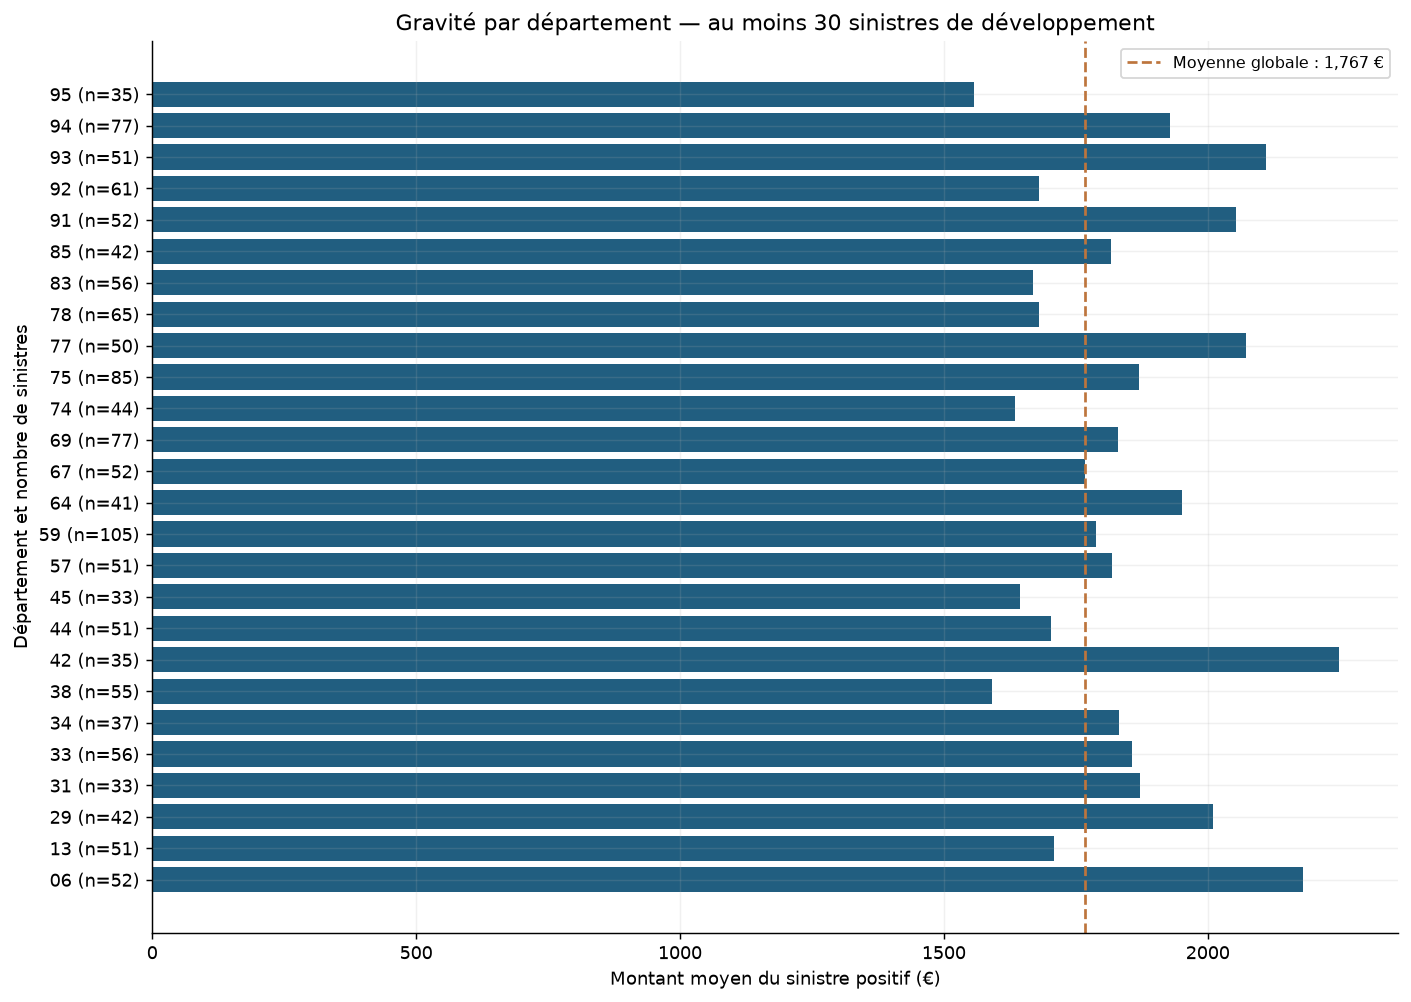

**Association département / coût positif : η² = 0.032.** Cet indicateur compare les moyennes d’une catégorie à une cible continue ; il n’a pas de signe et augmente mécaniquement avec le nombre de groupes. Il décrit cet échantillon, sans mesurer un gain de prédiction hors échantillon. Une corrélation de Pearson sur le numéro du département n’aurait pas de sens. Les départements sous le seuil de 30 sinistres restent dans le CSV et dans les données ; ils sont seulement écartés de ce graphique pour éviter une lecture trompeuse.

In [16]:
geo_examples = pd.DataFrame({'code_source': ['01001', '13055', '75101', '2A004', '2B150']})
geo_examples['departement'] = extraire_departement(geo_examples['code_source'])
display(geo_examples)
geography_summary = []
for label, frame in [('portefeuille développement', dev_portfolio),
                     ('sinistrés développement', gravite), ('test', test)]:
    geography_summary.append({'population': label, 'départements_distincts': frame['departement'].nunique(),
                               'départements_manquants': int(frame['departement'].isna().sum())})
table(pd.DataFrame(geography_summary), '23_creation_departement')

dep_counts = dev_portfolio.groupby('departement', dropna=False).size().rename('contrats_dev')
dep_stats = gravite.groupby('departement', dropna=False)[TARGET].agg(
    sinistres='size', gravité_moyenne_euros='mean', gravité_médiane_euros='median', écart_type_euros='std')
department_stats = dep_counts.to_frame().join(dep_stats)
department_stats['sinistres'] = department_stats['sinistres'].fillna(0).astype(int)
department_stats['effectif_fragile_moins_30'] = department_stats['sinistres'].lt(30)
department_stats = department_stats.reset_index()
department_stats.to_csv(REPORTS / '24_gravite_par_departement.csv', index=False)
display(department_stats)

between_ss = (dep_stats['sinistres'] * (dep_stats['gravité_moyenne_euros'] - y.mean()).pow(2)).sum()
eta_squared = float(between_ss / (y - y.mean()).pow(2).sum())
table(pd.DataFrame([{'variable': 'departement', 'indicateur': 'eta_carré_descriptif',
                     'valeur': eta_squared, 'sinistres': len(y),
                     'groupes_positifs': len(dep_stats)}]), '25_association_departement_gravite')

eligible = department_stats.loc[department_stats['sinistres'].ge(30)].sort_values('departement')
if len(eligible):
    fig, ax = plt.subplots(figsize=(11, max(5, 0.30 * len(eligible))))
    ax.barh(range(len(eligible)), eligible['gravité_moyenne_euros'], color=PRIMARY)
    ax.set_yticks(range(len(eligible)), [f'{d} (n={n})' for d, n in
                                       zip(eligible['departement'], eligible['sinistres'])])
    ax.axvline(y.mean(), color=SECONDARY, ls='--', label=f'Moyenne globale : {y.mean():,.0f} €')
    ax.set(title='Gravité par département — au moins 30 sinistres de développement',
           xlabel='Montant moyen du sinistre positif (€)', ylabel='Département et nombre de sinistres')
    ax.legend(fontsize=9)
    figure(fig, '09_gravite_departement')
note(f'**Association département / coût positif : η² = {eta_squared:.3f}.** '
     'Cet indicateur compare les moyennes d’une catégorie à une cible continue ; '
     'il n’a pas de signe et augmente mécaniquement avec le nombre de groupes. '
     'Il décrit cet échantillon, sans mesurer un gain de prédiction hors échantillon. '
     'Une corrélation de Pearson sur le numéro du département n’aurait pas de sens. '
     'Les départements sous le seuil de 30 sinistres restent dans le CSV et dans les données ; '
     'ils sont seulement écartés de ce graphique pour éviter une lecture trompeuse.')

### 5.2 Matérialiser le 80/20 et isoler la population de gravité

On réutilise les indices définis au début : `GroupShuffleSplit(test_size=0.20,
random_state=2026)` avec `id_client` comme groupe, sur le portefeuille complet.
Ensuite, dans chaque jeu, seuls les montants strictement positifs sont retenus.
Un même client ne peut pas se trouver des deux côtés.

Le 80/20 porte sur les clients du portefeuille. Les proportions de lignes et de
sinistres peuvent s'en écarter légèrement. Le nombre de sinistres de validation
est affiché pour documenter le découpage ; leurs coûts ne sont pas analysés ici.
Le fichier de test de la compétition reste un troisième jeu, sans cible.

In [17]:
train_gravite = train.iloc[dev_idx].loc[lambda df: df[TARGET].gt(0)].copy()
validation_gravite = train.iloc[reserved_idx].loc[lambda df: df[TARGET].gt(0)].copy()
assert set(train_gravite['id_client']).isdisjoint(set(validation_gravite['id_client']))
assert len(train_gravite) == len(gravite)
assert len(train_gravite) + len(validation_gravite) == int(train[TARGET].gt(0).sum())

total_positives = len(train_gravite) + len(validation_gravite)
split_summary = pd.DataFrame([
    {'jeu': 'apprentissage 80 %', 'contrats_portefeuille': len(dev_idx),
     'clients_portefeuille': train.iloc[dev_idx]['id_client'].nunique(),
     'sinistres_positifs': len(train_gravite), 'part_sinistres_pct': 100 * len(train_gravite) / total_positives},
    {'jeu': 'validation 20 %', 'contrats_portefeuille': len(reserved_idx),
     'clients_portefeuille': train.iloc[reserved_idx]['id_client'].nunique(),
     'sinistres_positifs': len(validation_gravite), 'part_sinistres_pct': 100 * len(validation_gravite) / total_positives},
])
table(split_summary, '26_decoupage_80_20')
print('Clients communs entre apprentissage et validation : 0')

Clients communs entre apprentissage et validation : 0


,jeu,contrats_portefeuille,clients_portefeuille,sinistres_positifs,part_sinistres_pct
0,apprentissage 80 %,39964,36628,2356,80.768
1,validation 20 %,10036,9157,561,19.232


### 5.3 Traitement des NaN appris uniquement sur l'apprentissage

Le traitement réutilisable se trouve dans `preparation_gravite.py` :

1. Recalculer `departement` depuis sa source ; ne conserver que les variables
   candidates, sans identifiants, sexe, cible ni code géographique détaillé.
2. Remplacer par NaN les poids / cylindrées / puissances / vitesses et âges principaux
   non positifs, ainsi que les anciennetés de
   permis négatives, égales à 111 ou supérieures à l'âge. Ce choix conservateur
   de traitement des codes suspects est explicite et devra être évalué ensuite.
3. Représenter l'âge et le permis du second conducteur absent par des NaN
   structurels. Conserver `conducteur2` et un indicateur de manquant pour chaque
   variable numérique afin de ne pas perdre cette information.
4. **Apprendre la médiane de chaque variable numérique source sur les seuls sinistres
   d'apprentissage**, puis appliquer les mêmes valeurs à la validation et au test.
   Les manquants catégoriels reçoivent `__MANQUANT__`. Si une variable numérique
   est entièrement manquante à l'ajustement, le repli documenté est 0 avec son
   indicateur de manquant ; les éventuels cas sont listés.

5. Recalculer chaque interaction à partir de ses deux sources **après leur imputation**,
   en conservant un indicateur si une source était absente ou invalide.

Les catégories restent textuelles, dont `departement` : l'encodage dépendra du
modèle choisi. Ce traitement retire les NaN sans imposer d'ordre aux catégories.
En validation croisée ultérieure, il faudra **réajuster une nouvelle instance**
de cette préparation à l'intérieur de chaque sous-train.

In [18]:
import joblib
from sklearn.base import clone

preparation = PreparationGravite()
X_train = preparation.fit_transform(train_gravite)
X_validation = preparation.transform(validation_gravite)
X_test = preparation.transform(test)
y_train = train_gravite[TARGET].copy()
y_validation = validation_gravite[TARGET].copy()

clean_train = preparation._clean(train_gravite)
clean_validation = preparation._clean(validation_gravite)
clean_test = preparation._clean(test)
imputation_rows = []
for col in MODEL_FEATURES:
    imputation_rows.append({
        'variable': col,
        'stratégie': ('produit des deux sources après imputation' if col in DERIVED_NUMERIC_FEATURES
                      else 'médiane des sinistrés apprentissage' if col in NUMERIC_FEATURES
                      else 'modalité __MANQUANT__'),
        'remplacement': (' × '.join(INTERACTION_SOURCES[col]) + ' imputés' if col in DERIVED_NUMERIC_FEATURES
                         else str(preparation.medians_[col]) if col in NUMERIC_FEATURES else '__MANQUANT__'),
        'NaN_apprentissage_avant': int(clean_train[col].isna().sum()),
        'NaN_validation_avant': int(clean_validation[col].isna().sum()),
        'NaN_test_avant': int(clean_test[col].isna().sum()),
        'NaN_apprentissage_après': int(X_train[col].isna().sum()),
        'NaN_validation_après': int(X_validation[col].isna().sum()),
        'NaN_test_après': int(X_test[col].isna().sum()),
    })
imputation_report = pd.DataFrame(imputation_rows)
table(imputation_report, '27_traitement_nan')
table(pd.DataFrame([
    {'jeu': label, 'lignes': len(frame), 'variables_après_traitement': frame.shape[1],
     'NaN_restants': int(frame.isna().sum().sum())}
    for label, frame in [('apprentissage gravité', X_train),
                         ('validation gravité', X_validation), ('test sans cible', X_test)]
]), '28_jeux_prepares')
print('Variables entièrement manquantes à l’apprentissage :', preparation.empty_numeric_features_)
note('**Lecture :** les NaN avant imputation incluent les absences structurelles et les codes suspects '
     'convertis explicitement en manquants. Les médianes ne dépendent ni de la validation ni du test. '
     'Les valeurs imputées chez un conducteur secondaire absent ne représentent pas un âge réel ; '
     'son absence reste indiquée par `conducteur2` et les indicateurs dédiés.')

Variables entièrement manquantes à l’apprentissage : []


,variable,stratégie,remplacement,NaN_apprentissage_avant,NaN_validation_avant,NaN_test_avant,NaN_apprentissage_après,NaN_validation_après,NaN_test_après
0,bonus,médiane des sinistrés apprentissage,0.5,0,0,0,0,0,0
1,duree_contrat,médiane des sinistrés apprentissage,9.0,0,0,0,0,0,0
2,anciennete_info,médiane des sinistrés apprentissage,2.0,0,0,0,0,0,0
3,age_conducteur1,médiane des sinistrés apprentissage,55.0,0,0,0,0,0,0
4,age_conducteur2,médiane des sinistrés apprentissage,45.0,1493,369,33408,0,0,0
5,anciennete_permis1,médiane des sinistrés apprentissage,33.0,0,0,14,0,0,0
6,anciennete_permis2,médiane des sinistrés apprentissage,25.0,1527,375,33779,0,0,0
7,anciennete_vehicule,médiane des sinistrés apprentissage,6.0,0,0,0,0,0,0
8,cylindre_vehicule,médiane des sinistrés apprentissage,1598.0,0,0,2,0,0,0
9,din_vehicule,médiane des sinistrés apprentissage,94.0,0,0,0,0,0,0


,jeu,lignes,variables_après_traitement,NaN_restants
0,apprentissage gravité,2356,46,0
1,validation gravité,561,46,0
2,test sans cible,50000,46,0


**Lecture :** les NaN avant imputation incluent les absences structurelles et les codes suspects convertis explicitement en manquants. Les médianes ne dépendent ni de la validation ni du test. Les valeurs imputées chez un conducteur secondaire absent ne représentent pas un âge réel ; son absence reste indiquée par `conducteur2` et les indicateurs dédiés.

In [19]:
# Vérifications fonctionnelles de la préparation, sans entraîner de modèle prédictif.
for frame in [X_train, X_validation, X_test]:
    assert not frame.isna().any().any()
    assert np.isfinite(frame.select_dtypes(include='number').to_numpy()).all()
    assert list(frame.columns) == list(X_train.columns)
    assert set(frame.columns).isdisjoint(IDS + SEXES + TARGETS + ['code_postal'])
    assert 'departement' in frame.columns
    assert set(DERIVED_NUMERIC_FEATURES).issubset(frame.columns)
    for name, (left, right) in INTERACTION_SOURCES.items():
        np.testing.assert_allclose(frame[name], frame[left] * frame[right])
assert preparation.n_samples_fit_ == len(train_gravite)
pd.testing.assert_series_equal(preparation.medians_, clean_train[list(NUMERIC_FEATURES)].median().fillna(0.0))
# Les cibles, même ajoutées ou modifiées, n’influencent pas les entrées préparées.
probe = validation_gravite.head(8).copy()
expected = preparation.transform(probe)
probe[TARGET] = -999999
probe['nombre_sinistres'] = 999
pd.testing.assert_frame_equal(expected, preparation.transform(probe))
# Un département inconnu devient une catégorie manquante, sans erreur ni ordre numérique.
geo_probe = pd.Series(['01001', '2A004', '2B150', '97105', '97411', '97601', '20000', None, 'invalide'])
assert extraire_departement(geo_probe).fillna('NA').tolist() == [
    '01', '2A', '2B', '971', '974', '976', 'NA', 'NA', 'NA']
probe['code_postal'] = None
assert preparation.transform(probe)['departement'].eq('__MANQUANT__').all()
assert not hasattr(clone(preparation), 'medians_'), 'Chaque pli doit repartir sans médiane apprise.'
# L'interaction est reconstruite depuis les entrées imputées même si une source manque.
missing_probe = validation_gravite.head(3).copy()
missing_probe['anciennete_vehicule'] = np.nan
missing_probe['din_vehicule'] = np.nan
missing_result = preparation.transform(missing_probe)
assert missing_result[f'{INTERACTION_FEATURE}__manquant'].eq(1).all()
assert not missing_result[INTERACTION_FEATURE].isna().any()
np.testing.assert_allclose(missing_result[INTERACTION_FEATURE],
                           preparation.medians_['anciennete_vehicule'] * preparation.medians_['din_vehicule'])

PREPARED = HERE / 'prepared'
PREPARED.mkdir(exist_ok=True)
for name, frame, raw, target in [
    ('train_gravite', X_train, train_gravite, y_train),
    ('validation_gravite', X_validation, validation_gravite, y_validation),
    ('test', X_test, test, None),
]:
    export = frame.copy()
    export.insert(0, 'index', raw['index'].to_numpy())
    if target is not None:
        export[TARGET] = target.to_numpy()
    export.to_csv(PREPARED / f'{name}.csv', index=False)

roles = train[['index', 'id_client']].copy()
roles['jeu'] = np.where(roles.index.isin(dev_idx), 'apprentissage', 'validation')
roles.to_csv(PREPARED / 'decoupage_clients.csv', index=False)
joblib.dump(preparation, PREPARED / 'preparation_gravite.joblib')
reloaded = joblib.load(PREPARED / 'preparation_gravite.joblib')
pd.testing.assert_frame_equal(X_validation, reloaded.transform(validation_gravite))
preparation_parameters = {
    'n_sinistres_apprentissage': len(train_gravite),
    'n_sinistres_validation': len(validation_gravite),
    'medians_apprentissage': {c: float(v) for c, v in preparation.medians_.items()},
    'variables_entierement_manquantes': preparation.empty_numeric_features_,
    'variables_preparees': preparation.get_feature_names_out().tolist(),
    'geographie': 'departement uniquement, catégorie textuelle ; code_postal exclu',
    'interactions': {name: {'sources': list(pair), 'calcul': 'produit après imputation des sources'}
                     for name, pair in INTERACTION_SOURCES.items()},
    'interaction_age_puissance': {'variable': INTERACTION_FEATURE,
                                 'formule': 'anciennete_vehicule * din_vehicule',
                                 'calcul': 'après imputation des deux sources'},
    'fichiers_locaux': ['train_gravite.csv', 'validation_gravite.csv', 'test.csv',
                        'decoupage_clients.csv', 'preparation_gravite.joblib'],
}
(REPORTS / 'preparation.json').write_text(json.dumps(preparation_parameters, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
note(f'**Préparation terminée :** {len(X_train):,} sinistres d’apprentissage, '
     f'{len(X_validation):,} sinistres de validation et {len(X_test):,} lignes de test ; '
     f'{X_train.shape[1]} variables après ajout des indicateurs et **aucun NaN restant**. '
     'Les jeux et la préparation ajustée sont dans `prepared/`, exclu du suivi Git. '
     'Les tableaux et graphiques agrégés sont conservés dans `reports/`.')

**Préparation terminée :** 2,356 sinistres d’apprentissage, 561 sinistres de validation et 50,000 lignes de test ; 46 variables après ajout des indicateurs et **aucun NaN restant**. Les jeux et la préparation ajustée sont dans `prepared/`, exclu du suivi Git. Les tableaux et graphiques agrégés sont conservés dans `reports/`.

### 5.4 Nouvelle variable : interaction entre âge et puissance du véhicule

On crée une variable quantitative appelée **`age_puissance_vehicule`** :

\[
\text{age\_puissance\_vehicule}
= \text{anciennete\_vehicule}\times\text{din\_vehicule}.
\]

Cette interaction propose au futur modèle un effet combiné de l'ancienneté et de
la puissance. Par exemple, un véhicule d'ancienneté 5 et de puissance DIN 100 a
une valeur de **500**. Ce produit n'est pas un coût estimé ni une règle de
dépréciation. Les deux variables d'origine restent dans les entrées.

Dans l'analyse exploratoire, une source absente ou invalide rend l'interaction
manquante. Dans les jeux préparés, le produit est recalculé **après l'imputation
des deux sources**, à partir des médianes du seul apprentissage si nécessaire.
Un indicateur `age_puissance_vehicule__manquant` conserve cette information.

La distribution, les corrélations et les coûts par groupe de cette variable
figurent aussi dans les sections 1.3, 3.1 et 3.2. Le tableau ci-dessous compare
ses associations avec celles des deux sources, sur les **seuls sinistres
positifs d'apprentissage**. Son apport prédictif devra être mesuré en validation :
une interaction ne crée pas d'information supplémentaire.

In [20]:
age_power_comparison = correlations_cible.loc[
    ['anciennete_vehicule', 'din_vehicule', INTERACTION_FEATURE]
].rename_axis('variable').reset_index()
table(age_power_comparison, '29_comparaison_age_puissance')

interaction_stats = gravite[INTERACTION_FEATURE].describe().rename_axis('statistique').reset_index(name='valeur')
table(interaction_stats, '30_distribution_age_puissance')
new_rho = correlations_cible.loc[INTERACTION_FEATURE, 'spearman_gravité']
note(f'**Interaction ajoutée aux trois jeux préparés.** '
     f'Corrélation de Spearman brute avec le montant positif : **{new_rho:.3f}**, '
     f'sur {int(correlations_cible.loc[INTERACTION_FEATURE, "paires_non_manquantes"]):,} sinistres d’apprentissage. '
     'Ce résultat descriptif ne suffit pas à démontrer un gain pour le futur modèle.')

,variable,spearman_gravité,pearson_gravité,paires_non_manquantes
0,anciennete_vehicule,-0.075,-0.107,2356
1,din_vehicule,-0.020,0.026,2356
2,age_puissance_vehicule,-0.079,-0.083,2356


,statistique,valeur
0,count,"2,356.000"
1,mean,667.065
2,std,480.435
3,min,59.000
4,25%,280.000
5,50%,582.500
6,75%,938.000
7,max,"3,700.000"


**Interaction ajoutée aux trois jeux préparés.** Corrélation de Spearman brute avec le montant positif : **-0.079**, sur 2,356 sinistres d’apprentissage. Ce résultat descriptif ne suffit pas à démontrer un gain pour le futur modèle.

### 5.5 Associations avec le montant : toutes les variables préparées et créées

Cette synthèse couvre **chaque colonne de `X_train`**, dont `departement`,
les trois interactions (âge véhicule × puissance, puissance × permis principal et
vitesse × âge du conducteur principal) et tous les indicateurs `__manquant`. Elle utilise
uniquement les sinistres positifs d'apprentissage et leur `montant_sinistre`.
Elle complète les corrélations brutes de la section 3.2 : ici les NaN ont été traités.

- **Quantitatives et indicateurs binaires :** corrélations de Pearson et Spearman
  avec le montant du sinistre. Une colonne constante n'a pas de corrélation
  définie et est signalée comme telle, sans la remplacer par une corrélation nulle.
- **Catégories, dont le département :** rapport de corrélation **η²**, calculé
  à partir des différences de coût moyen entre modalités. Il n'a pas de signe ;
  un numéro de département n'est jamais traité comme une grandeur ordonnée.

Les coefficients Pearson / Spearman et η² mesurent des associations différentes
et ne constituent pas un classement commun. η² peut être artificiellement élevé
pour des catégories très fragmentées, notamment le modèle du véhicule. Ces
résultats descriptifs ne remplacent pas une mesure de l'apport en validation.
Les coefficients non applicables sont laissés vides dans le CSV.

,variable,origine,type,sinistres,valeurs_distinctes,pearson,spearman,eta_carré,statut
0,bonus,variable source,quantitative / binaire,2356,41,0.025,0.004,NaN,calculé
1,duree_contrat,variable source,quantitative / binaire,2356,33,-0.034,-0.017,NaN,calculé
2,anciennete_info,variable source,quantitative / binaire,2356,15,-0.037,0.000,NaN,calculé
3,age_conducteur1,variable source,quantitative / binaire,2356,74,-0.028,0.005,NaN,calculé
4,age_conducteur2,variable source,quantitative / binaire,2356,73,-0.023,-0.020,NaN,calculé
5,anciennete_permis1,variable source,quantitative / binaire,2356,69,-0.047,-0.009,NaN,calculé
6,anciennete_permis2,variable source,quantitative / binaire,2356,66,-0.012,-0.001,NaN,calculé
7,anciennete_vehicule,variable source,quantitative / binaire,2356,30,-0.107,-0.075,NaN,calculé
8,cylindre_vehicule,variable source,quantitative / binaire,2356,194,-0.017,-0.047,NaN,calculé
9,din_vehicule,variable source,quantitative / binaire,2356,115,0.026,-0.020,NaN,calculé


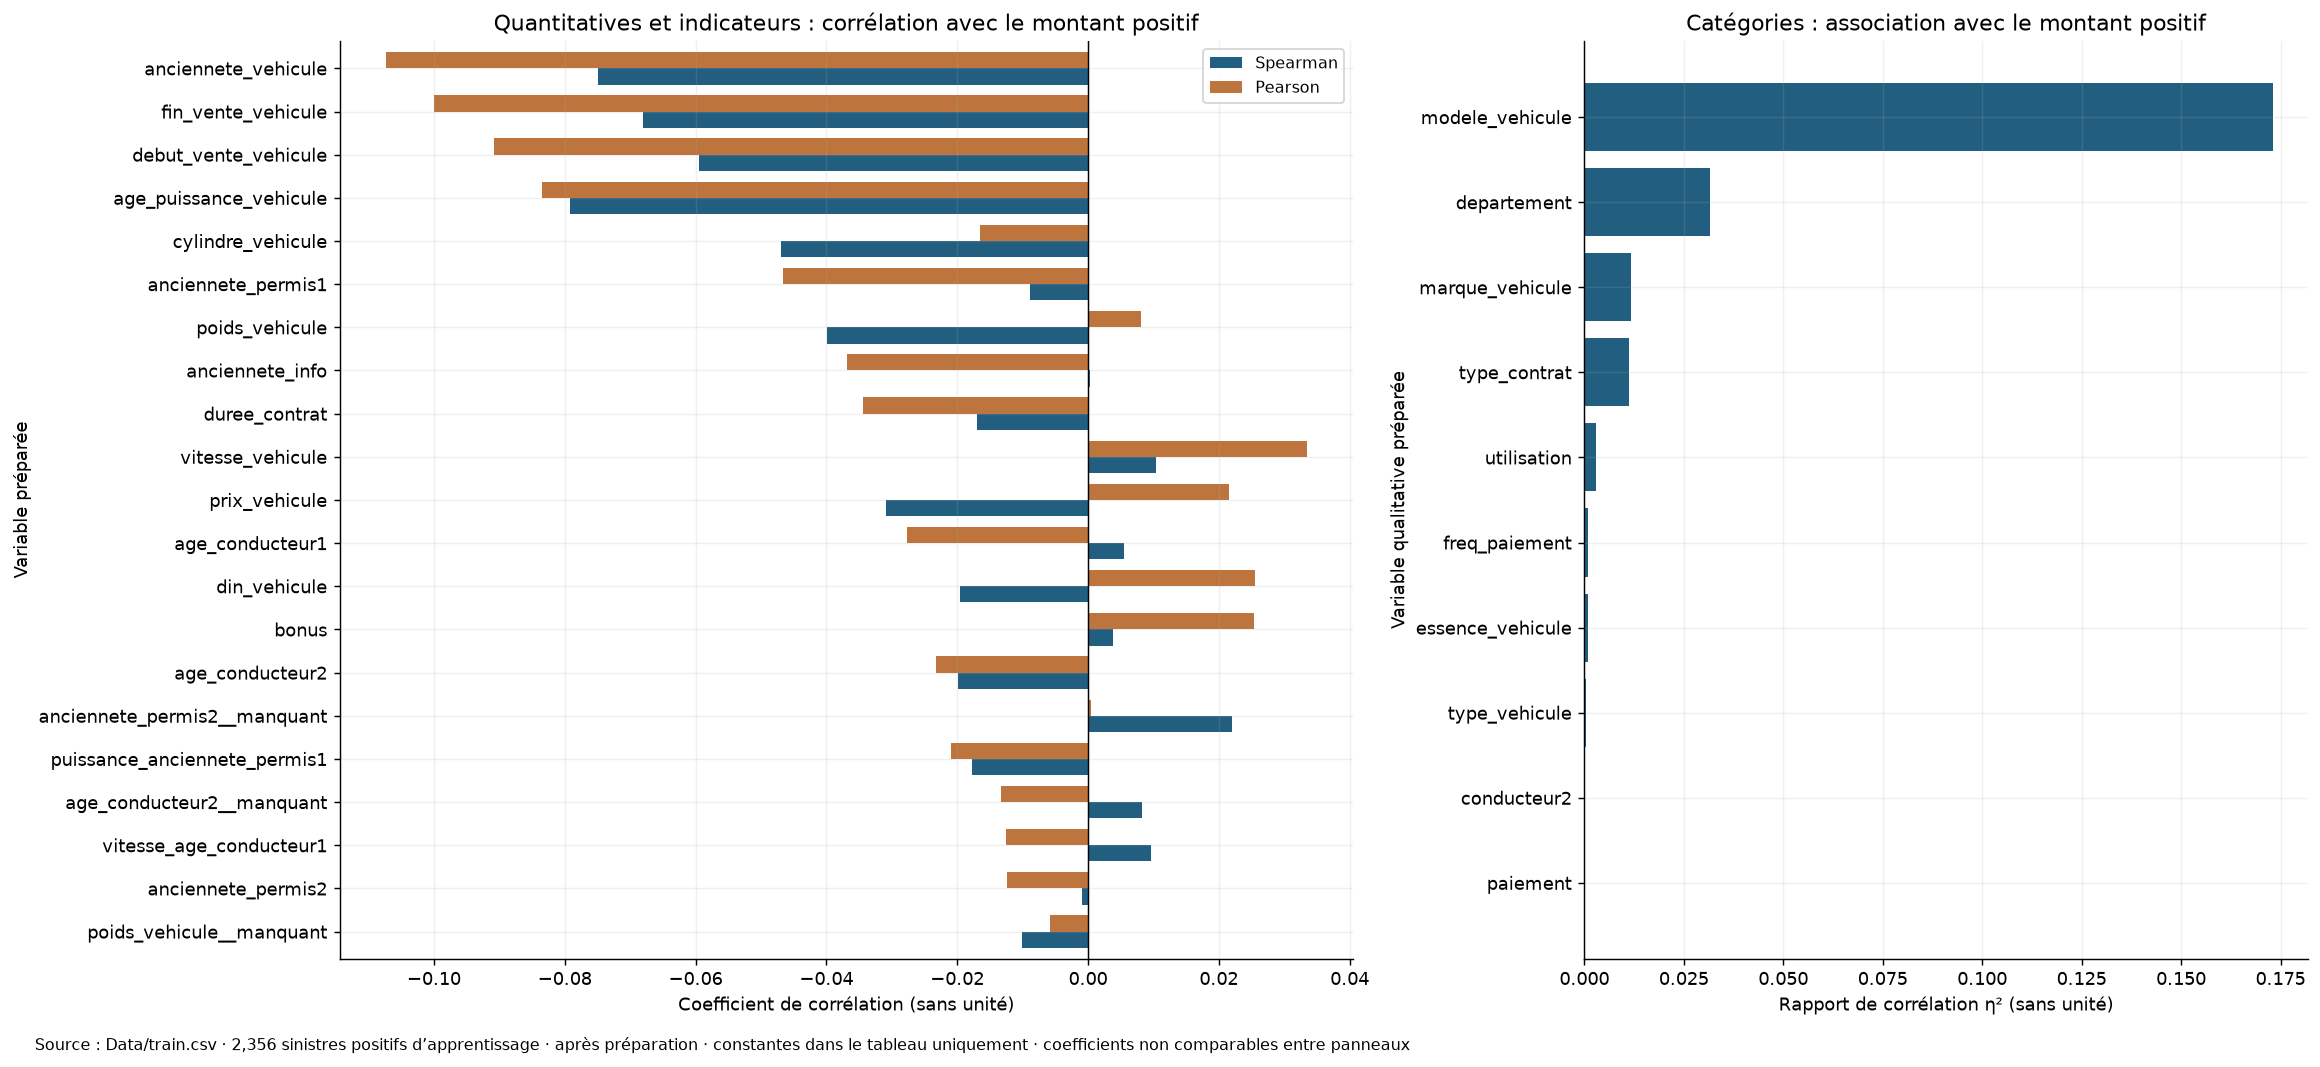

**Couverture vérifiée : 46 variables préparées**, dont 22 variables créées ou indicateurs. Les colonnes constantes restent visibles dans le tableau avec la mention « non calculable ». Aucun coût de validation ni aucun contrat sans sinistre ne participe à ces calculs.

In [21]:
all_associations = []
assert X_train.index.equals(y_train.index)
assert y_train.gt(0).all()
target_ss = (y_train - y_train.mean()).pow(2).sum()
for col in X_train.columns:
    s = X_train[col]
    quantitative = is_numeric_dtype(s)
    constant = s.nunique(dropna=True) < 2
    origin = ('interaction créée' if col in DERIVED_NUMERIC_FEATURES
              else 'département créé' if col == 'departement'
              else 'indicateur créé' if col.endswith('__manquant') else 'variable source')
    eta2 = np.nan
    if not quantitative and not constant:
        groups = pd.DataFrame({'modalité': s, 'montant': y_train}).groupby('modalité', observed=True)['montant'].agg(['size', 'mean'])
        eta2 = float((groups['size'] * (groups['mean'] - y_train.mean()).pow(2)).sum() / target_ss)
    all_associations.append({
        'variable': col, 'origine': origin,
        'type': 'quantitative / binaire' if quantitative else 'catégorielle',
        'sinistres': len(s), 'valeurs_distinctes': s.nunique(dropna=True),
        'pearson': s.corr(y_train, method='pearson') if quantitative and not constant else np.nan,
        'spearman': s.corr(y_train, method='spearman') if quantitative and not constant else np.nan,
        'eta_carré': eta2,
        'statut': 'constante : association non calculable' if constant else 'calculé',
    })
all_associations = pd.DataFrame(all_associations)
assert set(all_associations['variable']) == set(X_train.columns)
assert {'departement', *DERIVED_NUMERIC_FEATURES}.issubset(set(all_associations['variable']))
assert all_associations['sinistres'].eq(len(train_gravite)).all()
table(all_associations, '31_associations_toutes_variables_preparees')

numeric_associations = all_associations.loc[all_associations['type'].eq('quantitative / binaire')
                                           & all_associations['statut'].eq('calculé')].copy()
numeric_associations['amplitude'] = numeric_associations[['pearson', 'spearman']].abs().max(axis=1)
numeric_associations = numeric_associations.sort_values('amplitude')
category_associations = all_associations.loc[all_associations['type'].eq('catégorielle')
                                            & all_associations['statut'].eq('calculé')].sort_values('eta_carré')
fig, axes = plt.subplots(1, 2, figsize=(18, max(8, .32 * len(numeric_associations))),
                         gridspec_kw={'width_ratios': [1.4, 1]})
numeric_associations.set_index('variable')[['spearman', 'pearson']].plot.barh(
    ax=axes[0], color=[PRIMARY, SECONDARY], width=.75)
axes[0].axvline(0, color='black', lw=.8)
axes[0].set(title='Quantitatives et indicateurs : corrélation avec le montant positif',
            xlabel='Coefficient de corrélation (sans unité)', ylabel='Variable préparée')
axes[0].legend(handles=list(axes[0].containers), labels=['Spearman', 'Pearson'], fontsize=9)
axes[1].barh(category_associations['variable'], category_associations['eta_carré'], color=PRIMARY)
axes[1].set(title='Catégories : association avec le montant positif',
            xlabel='Rapport de corrélation η² (sans unité)', ylabel='Variable qualitative préparée')
fig.text(.02, -.015, f'Source : Data/train.csv · {len(y_train):,} sinistres positifs d’apprentissage · '
                     'après préparation · constantes dans le tableau uniquement · coefficients non comparables entre panneaux', fontsize=9)
figure(fig, '11_associations_toutes_variables_preparees')
note(f'**Couverture vérifiée : {len(all_associations)} variables préparées**, dont '
     f'{all_associations["origine"].ne("variable source").sum()} variables créées ou indicateurs. '
     'Les colonnes constantes restent visibles dans le tableau avec la mention « non calculable ». '
     'Aucun coût de validation ni aucun contrat sans sinistre ne participe à ces calculs.')

### 5.6 Puissance × ancienneté du permis et vitesse × âge du conducteur

La puissance est conservée seule dans **`din_vehicule`** et figure déjà dans
`age_puissance_vehicule`. On ajoute les deux croisements demandés :

\[
\text{puissance\_anciennete\_permis1}
=\text{din\_vehicule}\times\text{anciennete\_permis1}
\]

\[
\text{vitesse\_age\_conducteur1}
=\text{vitesse\_vehicule}\times\text{age\_conducteur1}.
\]

Le premier rapproche la puissance du véhicule de l'expérience déclarée du
conducteur principal. Le second utilise explicitement **l'âge du conducteur
principal**, conformément au choix retenu. `vitesse_vehicule` est une
caractéristique du véhicule ; elle ne mesure pas la vitesse réellement pratiquée
par ce conducteur.

Ces produits conservent leurs variables sources. Ils ne sont pas des scores de
risque et leur utilité reste à vérifier avec un modèle. Ils sont calculés sans
utiliser la cible. En présence de manquants, la préparation reconstitue les
produits après imputation des sources et ajoute leurs indicateurs `__manquant`.

Les codes de permis `111`, les anciennetés négatives ou supérieures à l'âge
du conducteur sont considérés comme manquants avant de construire le croisement
puissance × permis. Les mêmes règles sont appliquées à l'apprentissage, à la
validation et au test. Seul l'apprentissage détermine les médianes.

Les nouveaux croisements figurent aussi dans toutes les analyses de variables
et dans la synthèse des corrélations de la section 5.5. Le tableau suivant les
compare aux sources sur les sinistres positifs d'apprentissage, après préparation.

In [22]:
interaction_formulas = pd.DataFrame([
    {'variable_créée': name, 'source_1': pair[0], 'source_2': pair[1],
     'formule': ' × '.join(pair), 'dans_jeux_préparés': name in X_train.columns}
    for name, pair in INTERACTION_SOURCES.items()
])
table(interaction_formulas, '32_formules_interactions')
comparison_columns = ['din_vehicule', 'anciennete_vehicule', 'anciennete_permis1',
                      'vitesse_vehicule', 'age_conducteur1', *DERIVED_NUMERIC_FEATURES]
comparison = all_associations.set_index('variable').loc[
    comparison_columns, ['pearson', 'spearman', 'sinistres', 'valeurs_distinctes', 'statut']
].rename_axis('variable').reset_index()
table(comparison, '33_comparaison_interactions_conducteur')
assert set(DERIVED_NUMERIC_FEATURES).issubset(set(all_associations['variable']))
assert y_train.gt(0).all()
# Même logique si les sources sont manquantes ou si le permis est codé 111.
missing_sources = validation_gravite.head(3).copy()
missing_sources['anciennete_permis1'] = 111
missing_sources['vitesse_vehicule'] = np.nan
prepared_sources = preparation.transform(missing_sources)
for name in ['puissance_anciennete_permis1', 'vitesse_age_conducteur1']:
    left, right = INTERACTION_SOURCES[name]
    assert prepared_sources[f'{name}__manquant'].eq(1).all()
    assert not prepared_sources[name].isna().any()
    np.testing.assert_allclose(prepared_sources[name], prepared_sources[left] * prepared_sources[right])
note(f'**{len(DERIVED_NUMERIC_FEATURES)} interactions présentes dans les trois jeux préparés.** '
     f'Leurs corrélations utilisent les {len(y_train):,} sinistres positifs d’apprentissage, '
     'sans utiliser les coûts de validation. Les variables sources restent disponibles.')

,variable_créée,source_1,source_2,formule,dans_jeux_préparés
0,age_puissance_vehicule,anciennete_vehicule,din_vehicule,anciennete_vehicule × din_vehicule,True
1,puissance_anciennete_permis1,din_vehicule,anciennete_permis1,din_vehicule × anciennete_permis1,True
2,vitesse_age_conducteur1,vitesse_vehicule,age_conducteur1,vitesse_vehicule × age_conducteur1,True


,variable,pearson,spearman,sinistres,valeurs_distinctes,statut
0,din_vehicule,0.026,-0.020,2356,115,calculé
1,anciennete_vehicule,-0.107,-0.075,2356,30,calculé
2,anciennete_permis1,-0.047,-0.009,2356,69,calculé
3,vitesse_vehicule,0.033,0.010,2356,126,calculé
4,age_conducteur1,-0.028,0.005,2356,74,calculé
5,age_puissance_vehicule,-0.083,-0.079,2356,528,calculé
6,puissance_anciennete_permis1,-0.021,-0.018,2356,1051,calculé
7,vitesse_age_conducteur1,-0.013,0.010,2356,1359,calculé


**3 interactions présentes dans les trois jeux préparés.** Leurs corrélations utilisent les 2,356 sinistres positifs d’apprentissage, sans utiliser les coûts de validation. Les variables sources restent disponibles.

## 6. Choix des variables par validation croisée sur le développement

On compare des ensembles de variables cohérents pour recommander une version
simple du modèle de gravité. Les corrélations précédentes sont exploratoires ;
le critère de décision est ici la **RMSE en euros sur les prédictions hors pli**.
La MAE est présentée en complément. Les 561 sinistres de validation 20 % restent
à l'écart de la comparaison, comme le test sans cible.

**Plan fixé avant calcul :** un noyau couverture / prix / ancienneté véhicule ;
son extension au département ; l'ajout de la puissance, du permis principal,
de l'âge du conducteur puis de la vitesse ; chacun des trois croisements avec
ses sources ; tous les croisements ; toutes les sources ; toutes les variables.
Trois retraits du noyau géographique vérifient aussi la contribution du contrat,
du prix et de l'ancienneté. La moyenne du seul sous-train est la référence minimale.

**Protocole :** trois plis séparés par client dans le développement, répartissant
les sinistres par tranches de coût pour limiter les déséquilibres de queue. La
préparation est réajustée dans chaque sous-train ; les médianes, modalités rares
et encodages ne voient jamais le pli évalué. On utilise le même boosting Gamma
peu profond de scikit-learn pour tous les ensembles, avec paramètres fixes.
Ce banc d'essai n'est pas une nouvelle mesure du XGBoost historique du dépôt.

**Parcimonie :** parmi les ensembles de variables dont la RMSE hors pli est à
moins de **5 € du meilleur**, retenir celui qui compte le moins de variables
candidates, puis départager sur la RMSE. Ce seuil est un choix pratique annoncé
avant calcul, pas un intervalle de confiance. Les indicateurs de manquant des
variables sélectionnées sont conservés et comptés séparément.

Les ensembles sont comparés sur les mêmes plis, sans optimisation des
hyperparamètres ni consultation des coûts réservés. Le score utilisé pour
sélectionner les variables reste optimiste pour une évaluation finale ; il
devra ensuite être confronté au jeu de validation avec un choix figé.

In [23]:
from preparation_gravite import CATEGORICAL_FEATURES
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error
from threadpoolctl import threadpool_limits
import time

core = ['type_contrat', 'prix_vehicule', 'anciennete_vehicule']
geo_core = core + ['departement']
with_power = geo_core + ['din_vehicule']
with_experience = with_power + ['anciennete_permis1']
with_driver_age = with_experience + ['age_conducteur1']
with_speed = with_driver_age + ['vitesse_vehicule']
candidate_sets = {
    'metier_3': core,
    'metier_departement': geo_core,
    'avec_puissance': with_power,
    'avec_permis': with_experience,
    'avec_age_conducteur': with_driver_age,
    'avec_vitesse': with_speed,
    'croisement_age_puissance': with_power + ['age_puissance_vehicule'],
    'croisement_puissance_permis': with_experience + ['puissance_anciennete_permis1'],
    'croisement_vitesse_age': with_speed + ['vitesse_age_conducteur1'],
    'trois_croisements': with_speed + list(DERIVED_NUMERIC_FEATURES),
    'toutes_sources': list(NUMERIC_FEATURES) + list(CATEGORICAL_FEATURES),
    'toutes_variables': list(MODEL_FEATURES),
    'sans_contrat': [c for c in geo_core if c != 'type_contrat'],
    'sans_prix': [c for c in geo_core if c != 'prix_vehicule'],
    'sans_age_vehicule': [c for c in geo_core if c != 'anciennete_vehicule'],
}
assert all(set(columns).issubset(MODEL_FEATURES) for columns in candidate_sets.values())
assert len({tuple(sorted(cols)) for cols in candidate_sets.values()}) == len(candidate_sets)
TOLERANCE_EUROS = 5.0
comparison_parameters = dict(loss='gamma', max_iter=400, learning_rate=.03,
                             max_leaf_nodes=2, min_samples_leaf=40,
                             l2_regularization=20., early_stopping=False, random_state=SEED)
selection_raw = train_gravite.reset_index(drop=True)
selection_y = selection_raw[TARGET].to_numpy()
selection_groups = selection_raw['id_client'].to_numpy()
selection_strata = pd.qcut(pd.Series(selection_y).rank(method='first'), q=5, labels=False)
selection_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
selection_folds = list(selection_cv.split(selection_raw, selection_strata, selection_groups))

prepared_folds = []
for fold, (fit_idx, score_idx) in enumerate(selection_folds, 1):
    assert set(selection_groups[fit_idx]).isdisjoint(set(selection_groups[score_idx]))
    assert set(selection_groups[score_idx]).isdisjoint(reserved_clients)
    fold_preparation = PreparationGravite()
    fold_fit = fold_preparation.fit_transform(selection_raw.iloc[fit_idx])
    fold_score = fold_preparation.transform(selection_raw.iloc[score_idx])
    assert fold_preparation.n_samples_fit_ == len(fit_idx)
    prepared_folds.append((fold, fit_idx, score_idx, fold_fit, fold_score))

def columns_with_flags(columns):
    return list(columns) + [f'{c}__manquant' for c in columns
                            if f'{c}__manquant' in prepared_folds[0][3].columns]

def new_comparison_model():
    encoding = ColumnTransformer([
        ('num', 'passthrough', make_column_selector(dtype_include=np.number)),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=10,
                              sparse_output=False, dtype=np.float64),
         make_column_selector(dtype_exclude=np.number)),
    ])
    return Pipeline([('encodage', encoding),
                     ('gamma_boosting', HistGradientBoostingRegressor(**comparison_parameters))])

table(pd.DataFrame([{'ensemble': name, 'variables': ', '.join(columns),
                     'nb_candidates': len(columns),
                     'nb_avec_indicateurs': len(columns_with_flags(columns))}
                    for name, columns in candidate_sets.items()]), '34_plan_selection_variables')

,ensemble,variables,nb_candidates,nb_avec_indicateurs
0,metier_3,"type_contrat, prix_vehicule, anciennete_vehicule",3,5
1,metier_departement,"type_contrat, prix_vehicule, anciennete_vehicu...",4,6
2,avec_puissance,"type_contrat, prix_vehicule, anciennete_vehicu...",5,8
3,avec_permis,"type_contrat, prix_vehicule, anciennete_vehicu...",6,10
4,avec_age_conducteur,"type_contrat, prix_vehicule, anciennete_vehicu...",7,12
5,avec_vitesse,"type_contrat, prix_vehicule, anciennete_vehicu...",8,14
6,croisement_age_puissance,"type_contrat, prix_vehicule, anciennete_vehicu...",6,10
7,croisement_puissance_permis,"type_contrat, prix_vehicule, anciennete_vehicu...",7,12
8,croisement_vitesse_age,"type_contrat, prix_vehicule, anciennete_vehicu...",9,16
9,trois_croisements,"type_contrat, prix_vehicule, anciennete_vehicu...",11,20


In [24]:
selection_scores, selection_fold_scores = [], []
selection_predictions = {}
start_selection = time.monotonic()
for name, candidates in [('moyenne', []), *candidate_sets.items()]:
    predictions = np.empty(len(selection_y), dtype=float)
    training_rmse = []
    for fold, fit_idx, score_idx, fit_frame, score_frame in prepared_folds:
        if name == 'moyenne':
            mean = selection_y[fit_idx].mean()
            fold_prediction = np.full(len(score_idx), mean)
            train_prediction = np.full(len(fit_idx), mean)
        else:
            chosen_columns = columns_with_flags(candidates)
            comparison_model = new_comparison_model()
            with threadpool_limits(limits=2):
                comparison_model.fit(fit_frame[chosen_columns], selection_y[fit_idx])
                fold_prediction = comparison_model.predict(score_frame[chosen_columns])
                train_prediction = comparison_model.predict(fit_frame[chosen_columns])
        assert np.isfinite(fold_prediction).all() and (fold_prediction > 0).all()
        predictions[score_idx] = fold_prediction
        fold_rmse = float(np.sqrt(mean_squared_error(selection_y[score_idx], fold_prediction)))
        fit_rmse = float(np.sqrt(mean_squared_error(selection_y[fit_idx], train_prediction)))
        training_rmse.append(fit_rmse)
        selection_fold_scores.append({'ensemble': name, 'pli': fold, 'sinistres': len(score_idx),
                                      'rmse_euros': fold_rmse, 'rmse_apprentissage_euros': fit_rmse,
                                      'mae_euros': float(mean_absolute_error(selection_y[score_idx], fold_prediction))})
    selection_predictions[name] = predictions
    selection_scores.append({
        'ensemble': name, 'nb_variables': len(candidates),
        'nb_avec_indicateurs': len(columns_with_flags(candidates)) if candidates else 0,
        'rmse_hors_pli_euros': float(np.sqrt(mean_squared_error(selection_y, predictions))),
        'mae_hors_pli_euros': float(mean_absolute_error(selection_y, predictions)),
        'rmse_apprentissage_moyen_euros': float(np.mean(training_rmse)),
        'ecart_type_rmse_plis_euros': float(np.std([r['rmse_euros'] for r in selection_fold_scores
                                                  if r['ensemble'] == name], ddof=1)),
    })
    print(f'{name}: RMSE hors pli {selection_scores[-1]["rmse_hors_pli_euros"]:,.2f} €', flush=True)

selection_results = pd.DataFrame(selection_scores).sort_values('rmse_hors_pli_euros').reset_index(drop=True)
selection_fold_results = pd.DataFrame(selection_fold_scores)
best_rmse = selection_results.loc[selection_results['ensemble'].ne('moyenne'), 'rmse_hors_pli_euros'].min()
eligible_sets = selection_results.loc[selection_results['ensemble'].ne('moyenne')
                                     & selection_results['rmse_hors_pli_euros'].le(best_rmse + TOLERANCE_EUROS)]
recommended = eligible_sets.sort_values(['nb_variables', 'rmse_hors_pli_euros']).iloc[0]
recommended_name = recommended['ensemble']
recommended_variables = candidate_sets[recommended_name]
selection_results['ecart_au_meilleur_euros'] = selection_results['rmse_hors_pli_euros'] - best_rmse
selection_results['recommande_par_parcimonie'] = selection_results['ensemble'].eq(recommended_name)
table(selection_results, '35_selection_variables_scores')
table(selection_fold_results, '36_selection_variables_plis')
baseline_rmse = selection_results.set_index('ensemble').loc['moyenne', 'rmse_hors_pli_euros']
selection_summary = {
    'variables_recommandees': recommended_variables,
    'colonnes_avec_indicateurs': columns_with_flags(recommended_variables),
    'ensemble_recommande': recommended_name,
    'rmse_cv_recommandee_euros': float(recommended['rmse_hors_pli_euros']),
    'mae_cv_recommandee_euros': float(recommended['mae_hors_pli_euros']),
    'meilleure_rmse_cv_euros': float(best_rmse),
    'rmse_moyenne_constante_euros': float(baseline_rmse),
    'regle': 'minimum de variables parmi les ensembles à 5 euros ou moins de la meilleure RMSE hors pli',
    'tolerance_euros': TOLERANCE_EUROS,
    'modele_comparaison': 'sklearn.ensemble.HistGradientBoostingRegressor',
    'parametres': comparison_parameters, 'plis_clients': 3, 'sinistres_developpement': len(selection_y),
    'couts_validation_20_pourcent_utilises': False,
    'ensembles_comparés': candidate_sets,
}
(REPORTS / 'selection_variables.json').write_text(json.dumps(selection_summary, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print(f'Comparaison terminée en {time.monotonic() - start_selection:.1f} secondes.')

moyenne: RMSE hors pli 1,461.50 €
metier_3: RMSE hors pli 1,450.87 €
metier_departement: RMSE hors pli 1,451.17 €
avec_puissance: RMSE hors pli 1,453.29 €
avec_permis: RMSE hors pli 1,452.83 €
avec_age_conducteur: RMSE hors pli 1,452.53 €
avec_vitesse: RMSE hors pli 1,453.57 €
croisement_age_puissance: RMSE hors pli 1,454.38 €
croisement_puissance_permis: RMSE hors pli 1,453.63 €
croisement_vitesse_age: RMSE hors pli 1,454.01 €
trois_croisements: RMSE hors pli 1,455.21 €
toutes_sources: RMSE hors pli 1,456.29 €
toutes_variables: RMSE hors pli 1,457.49 €
sans_contrat: RMSE hors pli 1,451.92 €
sans_prix: RMSE hors pli 1,450.85 €
sans_age_vehicule: RMSE hors pli 1,454.66 €
Comparaison terminée en 24.0 secondes.


,ensemble,nb_variables,nb_avec_indicateurs,rmse_hors_pli_euros,mae_hors_pli_euros,rmse_apprentissage_moyen_euros,ecart_type_rmse_plis_euros,ecart_au_meilleur_euros,recommande_par_parcimonie
0,sans_prix,3,4,"1,450.848",928.459,"1,441.434",136.655,0.000,True
1,metier_3,3,5,"1,450.871",928.103,"1,439.155",137.095,0.023,False
2,metier_departement,4,6,"1,451.171",927.461,"1,438.371",137.013,0.323,False
3,sans_contrat,3,5,"1,451.922",930.928,"1,440.307",135.191,1.074,False
4,avec_age_conducteur,7,12,"1,452.534",929.551,"1,433.327",135.131,1.686,False
5,avec_permis,6,10,"1,452.832",929.486,"1,434.774",135.368,1.984,False
6,avec_puissance,5,8,"1,453.291",928.739,"1,437.285",136.706,2.443,False
7,avec_vitesse,8,14,"1,453.569",929.913,"1,431.750",135.961,2.721,False
8,croisement_puissance_permis,7,12,"1,453.628",929.946,"1,434.256",135.275,2.780,False
9,croisement_vitesse_age,9,16,"1,454.013",929.964,"1,431.646",136.034,3.165,False


,ensemble,pli,sinistres,rmse_euros,rmse_apprentissage_euros,mae_euros
0,moyenne,1,785,"1,332.470","1,521.712",929.005
1,moyenne,2,786,"1,599.760","1,386.908",967.430
2,moyenne,3,785,"1,439.695","1,472.012",959.547
3,metier_3,1,785,"1,319.878","1,501.771",901.514
4,metier_3,2,786,"1,592.087","1,363.557",943.472
5,metier_3,3,785,"1,427.486","1,452.137",939.302
6,metier_departement,1,785,"1,319.901","1,501.723",900.999
7,metier_departement,2,786,"1,592.070","1,363.126",944.524
8,metier_departement,3,785,"1,428.398","1,450.264",936.837
9,avec_puissance,1,785,"1,322.623","1,500.097",904.401


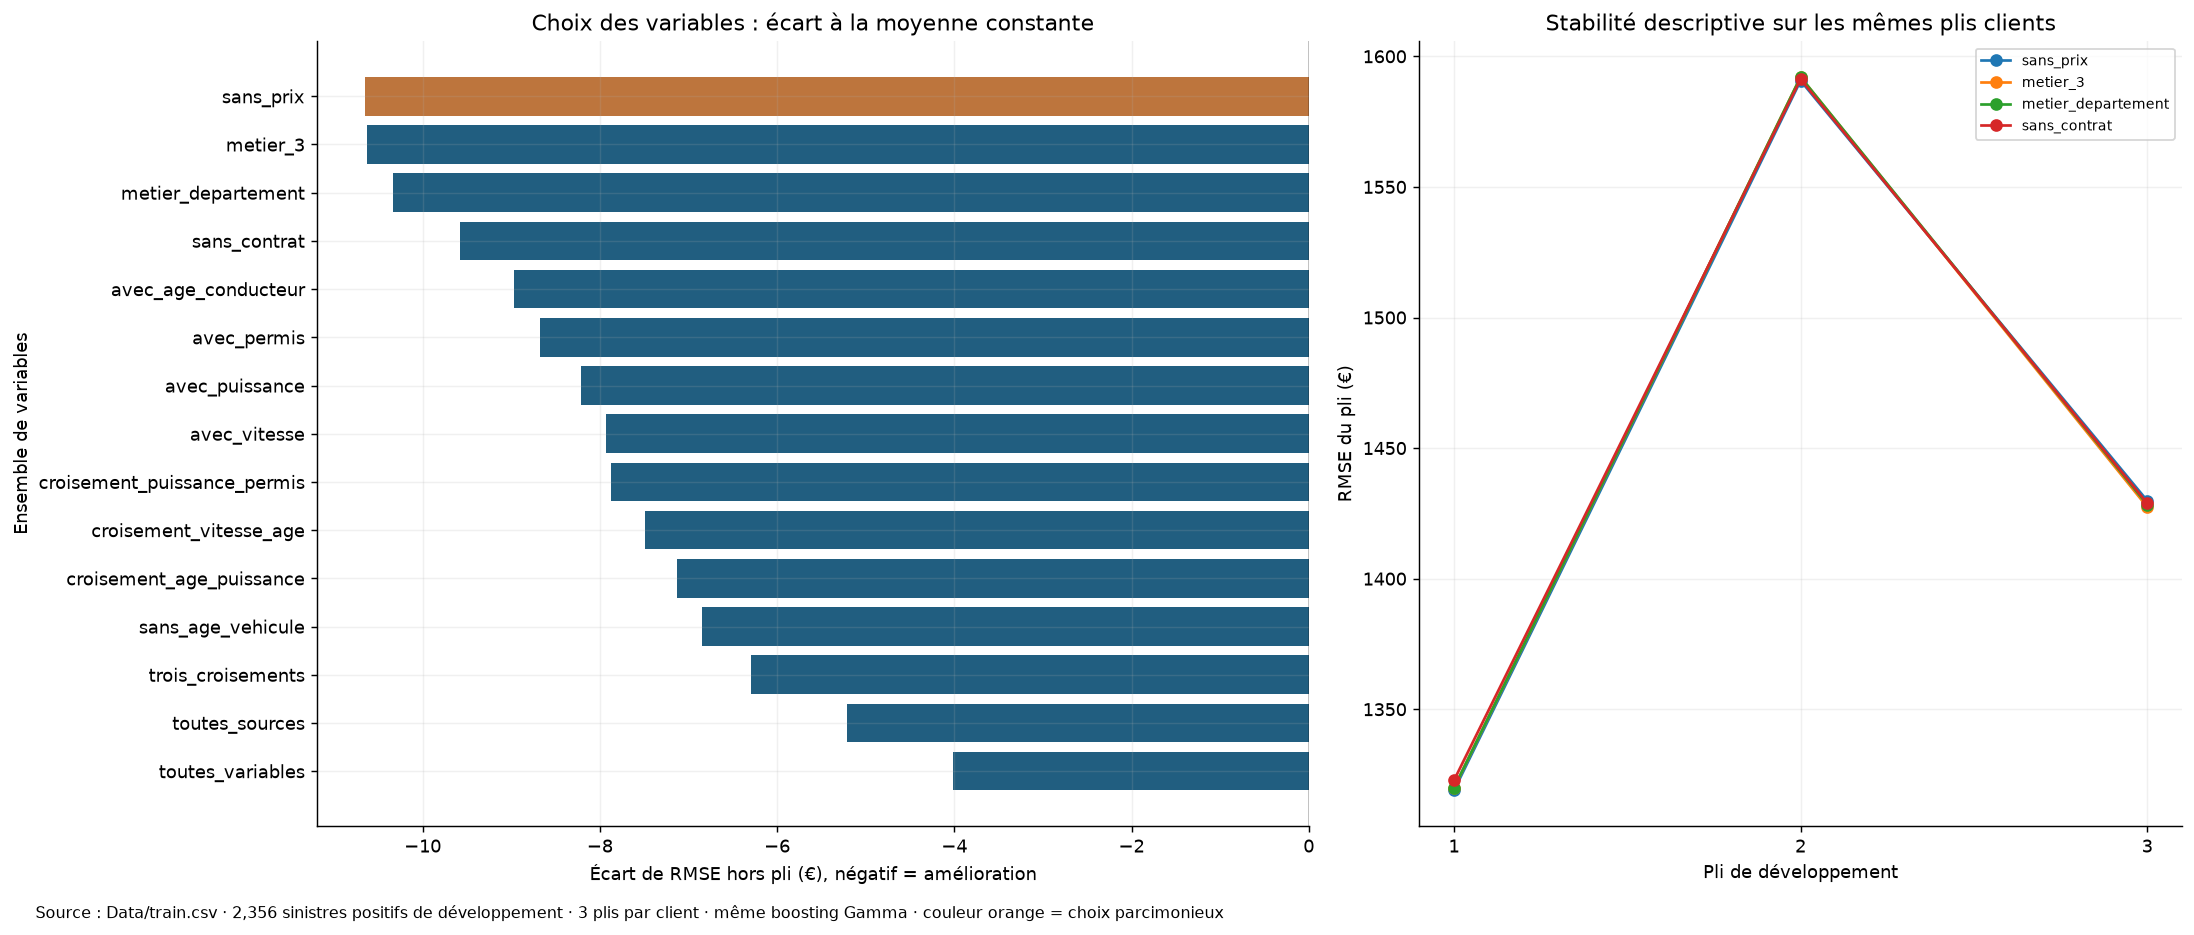

**Variables recommandées pour cette recette :** `type_contrat`, `anciennete_vehicule`, `departement`.

RMSE hors pli : **1,450.85 €**, MAE : **928.46 €**. Le meilleur ensemble testé est à 1,450.85 € de RMSE ; la moyenne constante est à 1,461.50 €. Le choix ci-dessus applique la tolérance de 5 € annoncée avant le calcul.

Les interactions et autres variables non retenues restent disponibles dans les jeux préparés. Ce choix concerne le modèle de comparaison fixé ; un autre modèle ou d’autres réglages peuvent modifier leur intérêt. La validation 20 % n’a pas été utilisée pour la sélection ; aucune performance finale indépendante n’est annoncée.

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={'width_ratios': [1.3, 1]})
chart = selection_results.loc[selection_results['ensemble'].ne('moyenne')].sort_values('rmse_hors_pli_euros', ascending=False)
axes[0].barh(chart['ensemble'], chart['rmse_hors_pli_euros'] - baseline_rmse,
             color=[SECONDARY if name == recommended_name else PRIMARY for name in chart['ensemble']])
axes[0].axvline(0, color='black', lw=.8)
axes[0].set(title='Choix des variables : écart à la moyenne constante',
            xlabel='Écart de RMSE hors pli (€), négatif = amélioration', ylabel='Ensemble de variables')
top_names = selection_results.loc[selection_results['ensemble'].ne('moyenne'), 'ensemble'].head(4).tolist()
if recommended_name not in top_names:
    top_names.append(recommended_name)
for name in top_names:
    t = selection_fold_results.loc[selection_fold_results['ensemble'].eq(name)]
    axes[1].plot(t['pli'], t['rmse_euros'], marker='o', label=name)
axes[1].set(title='Stabilité descriptive sur les mêmes plis clients', xlabel='Pli de développement', ylabel='RMSE du pli (€)')
axes[1].set_xticks([1, 2, 3])
axes[1].legend(fontsize=8)
fig.text(.02, -.015, f'Source : Data/train.csv · {len(selection_y):,} sinistres positifs de développement · '
                     '3 plis par client · même boosting Gamma · couleur orange = choix parcimonieux', fontsize=9)
figure(fig, '12_selection_variables')

note('**Variables recommandées pour cette recette :** ' + ', '.join(f'`{c}`' for c in recommended_variables) + '.\n\n'
     f'RMSE hors pli : **{recommended["rmse_hors_pli_euros"]:,.2f} €**, '
     f'MAE : **{recommended["mae_hors_pli_euros"]:,.2f} €**. '
     f'Le meilleur ensemble testé est à {best_rmse:,.2f} € de RMSE ; '
     f'la moyenne constante est à {baseline_rmse:,.2f} €. '
     'Le choix ci-dessus applique la tolérance de 5 € annoncée avant le calcul.\n\n'
     'Les interactions et autres variables non retenues restent disponibles dans les jeux préparés. '
     'Ce choix concerne le modèle de comparaison fixé ; un autre modèle ou d’autres réglages peuvent '
     'modifier leur intérêt. La validation 20 % n’a pas été utilisée pour la sélection ; '
     'aucune performance finale indépendante n’est annoncée.')

### Lecture de la recommandation et équivalence des petites recettes

Pour ce boosting Gamma à paramètres fixes, le choix parcimonieux retient
**`type_contrat`, `anciennete_vehicule` et `departement`**, avec **1 450,85 €** de
RMSE hors pli. Le noyau contrat / prix / ancienneté donne **1 450,87 €** :
l'écart de **0,02 €** est négligeable et ne démontre pas une supériorité stable
du département sur le prix. Les quatre variables ensemble obtiennent **1 451,17 €**.

Le prix du véhicule reste une alternative crédible ; sa non-sélection dans ce
petit banc d'essai ne prouve pas son inutilité. Les ajouts de puissance, permis,
vitesse et interactions ne réduisent pas la RMSE dans la recette testée. Ils
restent dans les données pour d'autres comparaisons éventuelles.

Cette recommandation privilégie une première version courte. Les hyperparamètres
n'ont pas été optimisés et le classement peut changer avec le modèle. Les 20 %
de validation n'ont servi ni à comparer les ensembles ni à choisir cette recette.


In [26]:
# Traçabilité et contrôles finaux : aucune cible individuelle de réserve affichée.
def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

assert set(FEATURES).isdisjoint(IDS + SEXES + TARGETS + ['code_postal'])
assert gravite[TARGET].gt(0).all()
assert len(gravite) == int(dev_portfolio['nombre_sinistres'].sum())
assert set(gravite['id_client']).isdisjoint(reserved_clients)
assert int(repeated['effectif'].sum()) <= len(gravite)
assert set(audit['variable']) == set(train.columns)
assert relations.groupby('variable')['sinistres'].sum().eq(len(gravite)).all()
manifest = {
    'notebook': 'nouveau_notebook/notebook.ipynb',
    'scope': 'analyse et préparation de gravité, puis sélection de variables en CV sur le développement',
    'selection_variables': selection_summary,
    'cible': TARGET, 'filtre': 'montant_sinistre > 0',
    'decoupage': {'methode': 'GroupShuffleSplit', 'test_size': 0.20, 'random_state': SEED,
                  'groupe': 'id_client', 'clients_communs': 0,
                  'contrats_developpement': len(dev_portfolio),
                  'contrats_reserves': len(reserved_idx)},
    'couts_reserve': 'filtre positif et effectif uniquement ; aucune moyenne, distribution ou corrélation',
    'preparation': preparation_parameters,
    'versions': versions,
    'sources_sha256': {str(path.relative_to(REPO)): sha256(path)
                       for path in [REPO / 'Data/train.csv', REPO / 'Data/test.csv',
                                    REPO / 'gravite_xgboost/assets/roadmap_reference.png',
                                    HERE / 'preparation_gravite.py']},
    'graphiques': sorted(path.name for path in REPORTS.glob('*.png')),
    'tableaux': sorted(path.name for path in REPORTS.glob('*.csv')),
    'limites': ['Données déjà explorées historiquement.',
               'Associations descriptives non causales ; aucune performance estimée.',
               'Unités, exposition, codage géographique et certains codes à confirmer.'],
}
(REPORTS / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
print(f'Analyse terminée : {len(manifest["tableaux"])} tableaux et '
      f'{len(manifest["graphiques"])} graphiques dans nouveau_notebook/reports/.')
print('Contrôles passés : cible positive, séparation des clients et couverture de toutes les variables candidates.')

Analyse terminée : 37 tableaux et 19 graphiques dans nouveau_notebook/reports/.
Contrôles passés : cible positive, séparation des clients et couverture de toutes les variables candidates.
